![RainyDay logo](https://her.cee.wisc.edu/wp-content/uploads/2018/11/rainyday.png)

# RainyDay_fast User's Guide
*Companion to the RainyDay User's Guide: what RainyDay_fast changes, adds and fixes*

# Table of contents <a class="anchor" id="toc"></a>
1. [Introduction to RainyDay_fast](#fast-intro)
    * [What is RainyDay_fast?](#intro-whatis)
    * [Where the code comes from (lineage)](#intro-lineage)
    * [How to use this guide with the original User's Guide](#intro-howtouse)
    * [Ground rule: identical results unless we say otherwise](#intro-bitidentity)
    * [License, authors and contact](#intro-contact)
2. [Getting Started with RainyDay_fast](#fast-start)
    * [Get the code](#start-code)
    * [The Python environment](#start-env)
    * [Do I still need PYTHONPATH?](#start-pypath)
    * [Check that it works](#start-check)
    * [Setting up a new domain](#start-newdomain)
3. [What changed at a glance](#fast-glance)
    * [Changes that alter results](#glance-results)
    * [Speed-ups (bit-identical)](#glance-speed)
    * [New capabilities](#glance-new)
    * [Corrected bugs](#glance-bugs)
4. [How SST works in RainyDay_fast](#fast-steps)
    * [Step 1: the transposition domain](#steps-1)
    * [Step 2: the storm catalog](#steps-2)
    * [Step 3: the number of storms per year](#steps-3)
    * [Step 4: resampling, transposition and the basin depth](#steps-4)
    * [Step 5: ranking and return periods](#steps-5)
5. [New and changed control-file fields](#fast-fields)
    * [An example control file](#field-example)
    * [New fields](#field-new)
    * [Changed fields](#field-changed)
    * [Other fields the code reads](#field-other)
    * [Fields the code does not read](#field-removed)
    * [How RainyDay reads keys](#field-keys)
6. [RainyDay_fast Features](#fast-features)
    * [Cropped input for a domain](#feat-crop)
    * [Light storm catalogs and reusing catalogs](#feat-light)
    * [Catalog-scan engines and the COMPUTE block](#feat-engines)
    * [How the catalog search treats the domain edge](#feat-catsearch)
    * [Strict transposition](#feat-strict)
    * [Many durations from one run: MULTIPLEDURATIONS](#feat-multidur)
    * [Faster frequency analysis: the table engine](#feat-table)
    * [Other output options](#feat-outputs)
    * [Three kinds of bands: ensemble spread, record CI and their combination](#feat-bands)
    * [Record uncertainty: RECORDCI](#feat-recordci)
    * [The exact frequency engine: FREQENGINE](#feat-exact)
    * [Comparing two runs: compare_runs](#feat-compare)
7. [Case Study 1: Point rainfall frequency in Iowa, with every kind of band](#case1)
    * [Part 1: Setting up RainyDay_fast](#c1-setup)
    * [Part 2: Running RainyDay_fast](#c1-run)
    * [Part 3: Rainfall frequency analysis](#c1-rfa)
    * [Part 4: Concluding remarks on the Iowa case study](#c1-conclusions)
8. [Case Study 2: Real basin vs its spread-matched ellipse](#case2)
    * [Part 1: Setting up the two runs](#c2-setup)
    * [Part 2: Running RainyDay_fast and compare_runs](#c2-run)
    * [Part 3: Results](#c2-rfa)
    * [Part 4: Concluding remarks on the HUC-8 case study](#c2-conclusions)
9. [Validation: how we know the results are right](#fast-validation)
    * [What "bit-identical" means, and how we check it](#val-bitidentity)
    * [Evidence for each feature](#val-features)
    * [The exact engine against Monte Carlo, in plain words](#val-exact)
    * [The record CI against real leave-one-year-out runs](#val-record)
    * [How to run the checks yourself](#val-howto)
10. [Corrected bugs](#fast-bugs)
    * [Bugs in the original RainyDay that are fixed here](#bug-original)
    * [Bugs fixed in October 2026](#bug-new)
    * [Bugs introduced and fixed during development](#bug-internal)
    * [Errata for the original User's Guide](#bug-errata)
    * [Were my earlier results affected?](#bug-affected)
11. [Known issues and workarounds](#fast-known)
    * [Not bugs, but worth knowing](#known-notes)
12. [Data issues (AORC)](#fast-data)
13. [Appendix A: Exact SST formulas](#appA)
    * [The pool and the exceedance rate](#appA-pool)
    * [The k-th largest event: PDS](#appA-pds)
    * [The k-th largest annual maximum: AMS](#appA-ams)
    * [The return level](#appA-level)
    * [Quantiles, expected minimum and maximum](#appA-spread)
    * [The record bootstrap](#appA-boot)
    * [Numerical details](#appA-numerics)
14. [Appendix B: Tools](#appB)
    * [Everyday use](#appB-everyday)
    * [Checking results](#appB-checks)
    * [Developers and benchmarks](#appB-dev)
15. [Appendix C: Output files and columns](#appC)
    * [Folder layout of a run](#appC-layout)
    * [Files and their contents](#appC-files)
    * [`_FreqExact.csv`, column by column](#appC-freqexact)
    * [`_RecordCI.csv`, column by column](#appC-recordci)
    * [The `compare_runs.py` CSV](#appC-compare)
16. [Appendix D: Environment variables](#appD)
    * [Precedence: environment variable > COMPUTE > auto](#appD-precedence)
    * [The variables](#appD-table)
    * [Variables used only by the tools](#appD-tools)
17. [Appendix E: Benchmarks](#appE)
    * [Catalog-scan engines on a Mac](#appE-engines)
    * [Catalog-scan engines on Windows with an NVIDIA GPU](#appE-windows)
    * [Cropped input and light catalogs](#appE-io)
    * [MULTIPLEDURATIONS and the compiled duration correction](#appE-multidur)
    * [The table engine](#appE-table)
    * [End to end](#appE-e2e)
    * [Record uncertainty and the exact engine](#appE-record)
18. [Appendix F: Map to README_CHANGES.md](#appF)
19. [Appendix G: References](#appG)

# Introduction to RainyDay_fast <a class="anchor" id="fast-intro"></a>

## What is RainyDay_fast? <a class="anchor" id="intro-whatis"></a>
RainyDay_fast is RainyDay with the same stochastic storm transposition (SST) method, made faster, with new features and with bugs fixed. You run it the same way: one JSON control file, one command, the same output files. We built it for large campaigns: thousands of runs over the same rainfall data and domains.

* **Faster.** On our five test basins, with cropped input, light catalogs and the table engine turned on, a full run (catalog plus frequency analysis for 1–72 h) is 2.3× to 31× faster than RainyDay_mod, the fork it comes from. A light storm catalog takes about 2 MB instead of 2–4 GB.
* **More.** One run gives many durations. You can reuse catalogs from any folder, measure the uncertainty from a short rainfall record, and compute the frequency curve without Monte Carlo noise.
* **Fixed.** A few bug fixes change results, for example where basins were transposed partly outside the domain.

Every new setting is optional, and its default keeps the old behaviour, so your control files keep working. The exceptions are a few inputs that were read wrongly before ([Bugs fixed in October 2026](#bug-new)).

## Where the code comes from (lineage) <a class="anchor" id="intro-lineage"></a>

| Step | Code | GitHub repository | Base or last commit |
|---|---|---|---|
| 1 | original RainyDay | HydroclimateExtremesGroup/RainyDay (D. B. Wright and colleagues) | `b14a011`, 2025-04-17 |
| 2 | RainyDay_mod | Perez-HydroSystems/RainyDay_mod (G. Perez) | `9137292`, 2026-10-21 |
| 3 | RainyDay_fast | Perez-HydroSystems/RainyDay_fast (G. Perez) | a clone of RainyDay_mod at `9137292` |

RainyDay_mod added the faster catalog search, catalog reuse, strict transposition, many durations per run and several bug fixes. RainyDay_fast adds cropped input, light catalogs, the table engine, the record CI and the exact engine. Everything in this guide, including `RECORDCI`, `FREQENGINE` and the [October 2026 bug fixes](#bug-new), is on the `main` branch (since 26 October 2026).

In this guide, "original RainyDay" always means commit `b14a011`. As of October 2026, the upstream repository has moved on since that commit. Its later commits include some of the 2025 RainyDay_mod changes, its own fixes to the valid transposition locations (September 2026) and an updated User's Guide (June 2026). RainyDay_fast is not built on those commits, and we have not compared results with them.

## How to use this guide with the original User's Guide <a class="anchor" id="intro-howtouse"></a>
Keep the original guide open next to this one. **Everything in it still applies unless we say otherwise.** This guide covers only what is new or different, and links back instead of repeating. The links open `RainyDay_Tutorial.ipynb` in this repository's `UserGuide` folder, the guide that matches `b14a011`.

| Original User's Guide | Read with it |
|---|---|
| [Getting Started](RainyDay_Tutorial.ipynb#GetStarted) | [Getting Started with RainyDay_fast](#fast-start) |
| [How SST works in RainyDay](RainyDay_Tutorial.ipynb#RainyDaySteps) | [How SST works in RainyDay_fast](#fast-steps) |
| [Structure of the SST Control File](RainyDay_Tutorial.ipynb#SSTfile) | [New and changed control-file fields](#fast-fields) |
| [RainyDay Features](RainyDay_Tutorial.ipynb#RainyDayFeatures) | [RainyDay_fast Features](#fast-features) |
| [SST Internal Variability](RainyDay_Tutorial.ipynb#variability) | [Three kinds of bands](#feat-bands) |
| [Case Study 1](RainyDay_Tutorial.ipynb#MadisonExample), [Case Study 2](RainyDay_Tutorial.ipynb#BigThompsonExample) | [Case Study 1](#case1), [Case Study 2](#case2) |
| [Appendix A: A General Description of SST](RainyDay_Tutorial.ipynb#SSTappendix) | [Appendix A: Exact SST formulas](#appA) |
| [Appendix B: Precipitation Data Sources](RainyDay_Tutorial.ipynb#PrecipData) | [Data issues (AORC)](#fast-data) |
| [Appendix D: NetCDF4 Files](RainyDay_Tutorial.ipynb#netcdfformats) | [Appendix C: Output files and columns](#appC) |

**Words we use.** These terms have one meaning each in this guide:
* **Realization:** one NYEARS-long synthetic record; RainyDay makes *N* = NREALIZATIONS of them.
* **Ensemble spread:** the range (min–max, or a quantile range) of a result across the *N* realizations. It is not a confidence interval.
* **Monte Carlo error:** the noise in the realization mean that comes from a finite *N*.
* **Record confidence interval (record CI):** the uncertainty from having only a few years of rainfall data.
* **Bit-identical:** the output files are the same byte for byte.

We write *P* for a rainfall depth (mm), *d* for a duration (h), *T* for a return period (yr) and *A* for an area (km<sup>2</sup>).

## Ground rule: identical results unless we say otherwise <a class="anchor" id="intro-bitidentity"></a>
**Every speed-up gives bit-identical output.** For the same data on the same machine and environment, you get the same storm catalogs, random draws and raw depths for every duration, and `_FreqAnalysis.csv` files that match byte for byte, compared with RainyDay_mod `9137292`. No random-number call was added, removed or moved, and we treat any difference as a bug. Only the [changes that alter results](#glance-results) give numbers different from the original RainyDay, and we say why for each.

**How we check it.** A validation matrix of five basins, from a one-cell Iowa pixel to a 16,000 km<sup>2</sup> ellipse, runs with production settings, and every output file is compared with a reference run. Every speed-up and every new option passed it ([Validation](#fast-validation)).

**Limits.**
* Bit-identity holds only on one machine and environment. Catalogs are not portable across operating systems, because exact ties between equal storm windows can break differently.
* The catalog-scan engines agree on every storm, window, position and rain field, bitwise; only the stored storm total may differ in the last digits ([why](#val-bitidentity)).
* The matrix uses irregular domains, uniform transposition, Poisson resampling, PDS and watershed basins. Other engines and rectangular domains were checked separately ([Validation](#val-features)).
* There are two exceptions by design. A cropped input is not bit-identical with `ENHANCEDSST` "stochastic" or "deterministic" ([Cropped input](#feat-crop)). `FREQENGINE` "exact" draws no random numbers and writes no Monte Carlo outputs ([The exact frequency engine](#feat-exact)).

## License, authors and contact <a class="anchor" id="intro-contact"></a>
**License.** The `LICENSE` file of RainyDay_fast is the original MIT License, unchanged: "Copyright (c) 2024 HydroclimateExtremesGroup". It lets you use, copy, modify, merge, publish, distribute, sublicense and sell copies of the software, as long as the copyright notice and the permission notice are included. The software comes "as is", without warranty of any kind. See also the original guide's [RainyDay License Agreement](RainyDay_Tutorial.ipynb#License).

**Authors.** The original RainyDay was written by Dr. Daniel B. Wright at the University of Wisconsin–Madison, with the Hydroclimate Extremes Group (contributors include Mohammad Ashar Hussain). Gabriel Perez wrote RainyDay_mod and RainyDay_fast. If you use RainyDay_fast, please cite the core RainyDay papers (Wright et al., 2017, 2020; [Appendix G](#appG)) and give the RainyDay_fast commit you used.

**Contact.**
* **About RainyDay_fast:** open an issue in the [RainyDay_fast GitHub repository](https://github.com/Perez-HydroSystems/RainyDay_fast/issues). Please do not send RainyDay_fast bugs to the original authors.
* **About SST or the original code:** use the [original RainyDay GitHub repository](https://github.com/HydroclimateExtremesGroup/RainyDay).

# Getting Started with RainyDay_fast <a class="anchor" id="fast-start"></a>
Getting started works as in [Getting Started with RainyDay](RainyDay_Tutorial.ipynb#GetStarted). This section covers only what differs.

## Get the code <a class="anchor" id="start-code"></a>
Clone the repository; its `main` branch has everything in this guide ([lineage](#intro-lineage)):

>git clone https://github.com/Perez-HydroSystems/RainyDay_fast.git<br>
>cd RainyDay_fast<br>

## The Python environment <a class="anchor" id="start-env"></a>
**[Option 1](RainyDay_Tutorial.ipynb#EnvYML).** The file is `RainyDay.yml` in the repository root (the original guide calls it "RainyDay_Env.yml"), unchanged from the original. It creates RainyDay_Env (Python 3.7) with everything RainyDay_fast loads:

>conda env create -f {path}/RainyDay_fast/RainyDay.yml<br>

As the original guide warns, this file is an exact export from one Mac and often fails elsewhere.

**[Option 2](RainyDay_Tutorial.ipynb#NewENV).** Install the packages listed in the original guide, then add three more:

>conda install scipy<br>
>conda install dask<br>
>conda install psutil<br>

* **scipy:** RainyDay_fast loads `scipy.fft` and `scipy.integrate.trapezoid` at start-up, so your SciPy must have both.
* **dask:** RainyDay's functions file loads it at start-up (since RainyDay_mod).
* **psutil (optional):** the automatic [compute settings](#feat-engines) use it to fit the catalog scan into your free memory. Without it, the run prints "RAM unknown (no psutil)" and does not limit the scan by memory.

You need GPU packages only for the optional GPU engines: CuPy for `batchcuda` (NVIDIA), or TensorFlow with its Metal plug-in for `batchtf` (Apple).

**Our tested environment.** We ran every check in this guide on a Mac (Apple M3 Max) with Python 3.8.18, NumPy 1.22.4, SciPy 1.10.1 and Numba 0.55.2, in line with the original guide's advice (Python 3.8, Numba 0.55). Results are bit-identical only within one machine and environment, so match these versions if you need our exact numbers.

## Do I still need PYTHONPATH? <a class="anchor" id="start-pypath"></a>
No. `RainyDay_Py3.py` loads its functions from `RainyDay_utilities_Py3`, the folder next to it in `Source`. Python always searches the script's own folder first, so it finds them without help. This was already true of the original code at `b14a011`, so you can skip the [PYTHONPATH step](RainyDay_Tutorial.ipynb#pypath). The tools in `tools/` find `Source` by themselves, and a PYTHONPATH left over from an older RainyDay does no harm.

## Check that it works <a class="anchor" id="start-check"></a>
**1. Start-up check.** Run RainyDay_fast with the name of a control file that does not exist:

>conda activate RainyDay_Env<br>
>python {path}/RainyDay_fast/Source/RainyDay_Py3.py {path}/nothing.json<br>

You should see the license text and "You either didn't specify a parameter file, or it doesn't exist on the source path given.", followed by a `NameError`. That is fine: every module loaded. With no file name at all, as the [original guide](RainyDay_Tutorial.ipynb#CheckIt) suggests, the run ends with an `IndexError` instead (see [Errata](#bug-errata)).

**2. The Talequah example.** `Examples/Talequah/Talequah.json` is our smoke test. It builds a 72 h catalog of 10 storms for a basin of about 4,300 km<sup>2</sup> on the Oklahoma–Arkansas border. It makes diagnostic plots but no frequency analysis. It reads AORC for July–September 2002 (92 daily files `AORC.YYYYMMDD.preciptemp.nc`); see [NOAA AORC](RainyDay_Tutorial.ipynb#aorc) and [Data issues (AORC)](#fast-data). The JSON holds machine-specific paths, so replace these four with your own before you run it:

```json
{
  "MAINPATH": "{MAINPATH}",
  "RAINPATH": "{AORC folder}/AORC.*.preciptemp.nc",
  "DOMAINSHP": "{path}/RainyDay_fast/Examples/Talequah/Shapefiles/Talequah_transposition_domain.shp",
  "WATERSHEDSHP": "{path}/RainyDay_fast/Examples/Talequah/Shapefiles/Talequah_basin.shp"
}
```

<a class="anchor" id="start-mainpath"></a>**NOTE:** The `MAINPATH` folder must already exist. RainyDay creates only the run folders inside it, with `os.mkdir` (as the original does), and stops with a `FileNotFoundError` if MAINPATH itself is missing. This holds for every run in this guide, so create it first:

>mkdir -p {MAINPATH}<br>

Then run:

>python {path}/RainyDay_fast/Source/RainyDay_Py3.py {path}/RainyDay_fast/Examples/Talequah/Talequah.json<br>

**Hint:** Always give the control file as a full (absolute) path. RainyDay moves into `MAINPATH` at the start and opens the control file again later. With a relative path, the original could silently leave storms out of the catalog; RainyDay_fast stops with an error instead.

The run takes about 30 s on our Mac. Look for:
* the line `Compute config: engine=...`, which names the scan engine it chose (`batchfft_mp` on a Mac or Linux machine with 4 or more cores);
* the line `catalog scan timer: ... minutes`;
* a folder `{MAINPATH}/Talequah_3days/` with `Diagnostics/` and `StormCatalog/`, which holds 10 files `Talequah_3days.nc_storm_<n>_<YYYYMMDD>.nc`.

**3. A stronger check (optional; Mac or Linux).** This script runs Talequah five times: two runs that compute several durations at once (one with MULTIDURATIONENGINE "exact", one with "fast"), and separate 1, 6 and 72 h runs. It then checks that all their depths match bit for bit. With RainyDay_Env active, run:

>bash {path}/RainyDay_fast/tools/test_multidurations.sh $(which python) {AORC folder}<br>

It must print "ALL PASS" twice.

## Setting up a new domain <a class="anchor" id="start-newdomain"></a>
If you will run a domain more than once, crop the input to it first. You do this once per domain, and every later run reads less data:

>python {path}/RainyDay_fast/tools/make_domain_crop.py --json {path}/MyRun.json --verify<br>

This writes the crop and `MyRun_crop.json`, a copy of your control file that points at it. See [Cropped input for a domain](#feat-crop).

# What changed at a glance <a class="anchor" id="fast-glance"></a>
Three short tables list every change, and each row links to the section that explains it. The bugs come last.

## Changes that alter results <a class="anchor" id="glance-results"></a>
These are the changes that give numbers different from the original RainyDay, apart from two narrow fixes in [Original bugs](#bug-original): a failed storm-file write now stops the run, and SCENARIOS no longer squeezes every dimension of size 1.

| Change | What happens now | Your results change if | Details |
|---|---|---|---|
| Strict transposition | A basin is placed only where its whole box is inside the domain. | you use an irregular domain and uniform transposition, and basins reach the edge (SE Texas HUC-8, 72 h, 100-yr: 489 → 412 mm) | [Strict transposition](#feat-strict) |
| Domain-aware catalog search | Every location where the whole basin box fits is searched; the original missed some locations (two edge rows and a middle column) and stored about half of them one cell off. | you build a catalog on an irregular domain | [Catalog search](#feat-catsearch) |
| `RETURNLEVELS` lists | A JSON list now selects the printed return periods; the original ignored it. | you gave a list (only the printed rows change) | [Fields](#field-RETURNLEVELS) |
| Missing time steps | They are filled with zeros instead of stopping the run. | your input has gaps | [Original bugs](#bug-original) |
| Rectangular-domain catalogs (October 2026) | The same exhaustive search as on irregular domains, with the whole rectangle as the domain. RainyDay_mod crashed for basin boxes 3 or more cells wide or tall. | you build a catalog on a rectangular domain: every such catalog differs from the original's | [October 2026 fixes](#bug-new) |
| Control-file parsing (October 2026) | Several settings are now read as you meant them (list below). | you used one of those forms | [October 2026 fixes](#bug-new) |

The parsing fixes cover `EXCLUDEMONTHS` (ranges across the year end such as "12-3", a single month, lists of strings, and its use on a reused catalog without `INCLUDEYEARS`), `INCLUDEYEARS` (lists of strings), `EXCLUDESTORMS` (a single storm number) and, in all three, an unreadable string, which now stops the run; also an unknown `CALCTYPE`, a numeric `UNCERTAINTY`, `RETURNLEVELS` as a comma string, and the `NSTORMS` default when you reuse a catalog.

Bugs that were made and fixed inside the fork, never in the original, are not listed here ([Bugs introduced during development](#bug-internal)).

## Speed-ups (bit-identical) <a class="anchor" id="glance-speed"></a>
None of these changes any output file (the scan engines find the same storms, windows, positions and rain; [details](#val-bitidentity)). Cropped input, light catalogs, the table engine and the memory tracer switched off make a full run of our five test basins 2.3× to 31× faster than RainyDay_mod ([Appendix E](#appE)); the scan engines and the compiled duration correction were already in RainyDay_mod.

| Speed-up | What it does | Example | Details |
|---|---|---|---|
| Cropped input | One cropped copy of the input per domain; `RAINPATH` points at it. | Iowa catalog scan: 11.0 → 2.0 min | [Cropped input](#feat-crop) |
| Light catalog | No rain fields in the catalog; the rain is rebuilt from `RAINPATH` and checked against a checksum. | Iowa catalog: 4.0 GB → 1.8 MB | [Light catalogs](#feat-light) |
| Scan engines and `COMPUTE` | Batched FFT storm search on several CPU cores or a GPU. By default it uses `batchfft_mp` on Mac or Linux with 4 or more cores, else `batchcuda` with an NVIDIA GPU, else `batchfft`. | CONUS, July 2002 scan: 2.16 → 0.13 min | [Engines](#feat-engines) |
| Compiled duration correction | `DURATIONCORRECTION` "true" runs use compiled code (`MULTIDURATIONENGINE` "fast", the default). | Iowa pixel, 1 h: 595 → 86 s | [Table engine](#feat-table) |
| Table engine | A per-storm FFT table finds the few windows that can hold the maximum; only those are summed exactly. | Iowa 16,000 km<sup>2</sup> frequency analysis: 4,048 → 69 s | [Table engine](#feat-table) |
| Memory tracer off | An unused memory tracer (`tracemalloc`) from the original is switched off. | about 3× on a one-cell basin | [Table engine](#feat-table) |

## New capabilities <a class="anchor" id="glance-new"></a>
All are optional and off by default. They add outputs or options and leave your usual outputs unchanged.

| Setting or tool | What you get | Details |
|---|---|---|
| `MULTIPLEDURATIONS` | Many durations from one run and one catalog, each the same as a separate run. | [MULTIPLEDURATIONS](#feat-multidur) |
| `CATALOGPATH` | Reuse a storm catalog from any folder. | [Reusing catalogs](#feat-light) |
| `CATALOGSTORAGE` | A "light" or a "full" catalog. | [Light catalogs](#feat-light) |
| `UNCERTAINTY` "all_realizations" | Every realization in `_FreqAnalysis.csv`. | [Output options](#feat-outputs) |
| `DIAGNOSTICPLOTS` "only-statistics" | The catalog statistics maps, without the per-storm plots. | [Output options](#feat-outputs) |
| `RECORDCI` | The record CI, by bootstrap or jackknife of the record years. | [RECORDCI](#feat-recordci) |
| `FREQENGINE` | The frequency curve computed exactly, with no Monte Carlo error. | [FREQENGINE](#feat-exact) |
| `tools/compare_runs.py` | The difference between two runs, with a CI that combines Monte Carlo error and the record CI. | [compare_runs](#feat-compare) |

## Corrected bugs <a class="anchor" id="glance-bugs"></a>
[Corrected bugs](#fast-bugs) lists the [bugs of the original that are fixed](#bug-original), the [October 2026 fixes](#bug-new), the [bugs made and fixed inside the fork](#bug-internal) and the [errata of the original User's Guide](#bug-errata), and tells you [whether your earlier results are affected](#bug-affected). What is still broken is in [Known issues and workarounds](#fast-known).

# How SST works in RainyDay_fast <a class="anchor" id="fast-steps"></a>
RainyDay_fast does SST in the same five steps as the original. Each step is summarized below in a few sentences; the full text, adapted from Wright et al. (2017), is in [How SST works in RainyDay](RainyDay_Tutorial.ipynb#RainyDaySteps). After each step, a short paragraph says what RainyDay_fast changes there. The figure below shows all of these changes on one page.

![The five SST steps and what RainyDay_fast changes in each](fast_tutorial_figures/fast-steps_flow.png)
**Figure: The five SST steps of RainyDay (left) and the RainyDay_fast changes that act on each (right). Red tags change results relative to the original RainyDay, grey tags are bit-identical speed-ups, and blue tags are new options or outputs.**

## Step 1: the transposition domain <a class="anchor" id="steps-1"></a>
You choose a transposition domain *A<sub>D</sub>* around your area of interest *A<sub>w</sub>* (one grid cell, a rectangle or a watershed polygon), ideally one where extreme rainfall is alike everywhere. You set it with DOMAINTYPE and DOMAINSHP (AREA_EXTENT for a rectangle).

**What RainyDay_fast changes here:** How you define the domain stays the same, but "inside the domain" now has one strict meaning. A basin position counts as inside only if the whole **basin box** (the smallest rectangle of grid cells that holds the basin mask) lies inside the domain. The original used looser rules, and different ones in the catalog search and in transposition. RainyDay_fast uses this one rule in both (in transposition with TRANSPOSITION "uniform"; "nonuniform" keeps the original rule), so make your domain clearly larger than your basin. If you will run the domain many times, also [crop the input](#feat-crop) to it once.

## Step 2: the storm catalog <a class="anchor" id="steps-2"></a>
RainyDay scans the *n*-year record for the *m* largest storms that do not overlap in time (NSTORMS). A storm's size is its *t*-hour rainfall (DURATION) over an area with the size, shape and orientation of *A<sub>w</sub>*, anywhere in *A<sub>D</sub>*. These "parent storms" form the storm catalog.

**What RainyDay_fast changes here:**
* **The search rule (this changes results).** RainyDay_fast evaluates every location where the whole basin box fits inside the domain, and only those: on irregular domains, and since October 2026 on rectangular ones. The original let the box stick out of an irregular domain, skipped some locations and stored about half of them one cell off. See [How the catalog search treats the domain edge](#feat-catsearch).
* **Speed and size (the same storms).** On irregular domains the search runs as batched FFTs on several CPU cores or a GPU ([engines](#feat-engines)). A light catalog keeps no rain fields, and `CATALOGPATH` reuses a catalog from any folder ([light catalogs](#feat-light)).

## Step 3: the number of storms per year <a class="anchor" id="steps-3"></a>
For each synthetic year, RainyDay draws *k*, the number of storms in that year. With RESAMPLING "poisson", *k* follows a Poisson distribution with rate *λ = m/n* storms per year.

**What RainyDay_fast changes here:** Nothing, but check how the years *n* are counted:
* **Without INCLUDEYEARS:** *n* is the number of distinct calendar years in which catalog storms *end*. A year with no catalog storm does not count. A storm that ends at 00:00 on 1 January (the last hour of the 31 December file) counts in the new year, and adds a year if no other storm ends in it. For example, 400 storms from 2002–2023 give *λ* = 400/22 = 18.2. If one storm ends at 00:00 on 1 January 2024, *n* becomes 23 and *λ* = 17.4: 4 % fewer storms in every synthetic year.
* **With INCLUDEYEARS:** *n* is the number of years listed.

**Hint:** Always set INCLUDEYEARS to exactly the years of your input, for example `"INCLUDEYEARS": "2002-2023"`. The [record CI](#feat-recordci) then counts the same years, and it warns you when the two counts differ.

## Step 4: resampling, transposition and the basin depth <a class="anchor" id="steps-4"></a>
RainyDay picks *k* parent storms at random and moves each to a random location in *A<sub>D</sub>*, without changing its motion or structure. For each moved storm, it computes the *t*-hour rainfall averaged over *A<sub>w</sub>*. With CALCTYPE "ams" it keeps the largest of the *k* as the year's synthetic annual maximum; with "pds" it keeps all of them for Step 5.

**What RainyDay_fast changes here:**
* **Where a storm can go (strict transposition; this changes results).** With uniform transposition on an irregular domain, a basin is now placed only where its whole box lies inside the domain. The original required only one corner cell inside, so a basin could hang partly outside the domain and collect rain there. The effect is large where big storms sit on the domain edge; see [Strict transposition](#feat-strict).
* **The basin depth of each draw (faster, bit-identical).** Summing the rain over the basin for every draw takes most of the frequency-analysis time. Compiled code, the table engine and MULTIPLEDURATIONS, which computes every duration from the same draws, give the same sums faster ([MULTIPLEDURATIONS](#feat-multidur), [the table engine](#feat-table)).

## Step 5: ranking and return periods <a class="anchor" id="steps-5"></a>
RainyDay repeats Steps 3 and 4 for *T<sub>max</sub>* = NYEARS synthetic years and ranks the results. Rank *i* gets *AEP<sub>i</sub> = i/T<sub>max</sub>* and return period *T = T<sub>max</sub>/i*. All of this is repeated for *N* = NREALIZATIONS realizations, and `_FreqAnalysis.csv` reports their mean and ensemble spread.

**What RainyDay_fast changes here:** The ranking is unchanged. AMS ranks the NYEARS annual maxima, PDS the NYEARS largest events of all synthetic years together, and both use *T* = NYEARS/rank. With NYEARS 1000, the largest value is the 1000-yr value and the 10th largest the 100-yr value; RETURNLEVELS picks the nearest available *T*.

RainyDay_fast adds two new ways to read the result:
* **The exact engine** (`FREQENGINE`) computes the frequency curve from every storm at every location RainyDay can draw, without random draws. Its `mean` is the realization mean without Monte Carlo error (as if NREALIZATIONS were infinite), and its `level` is the *T*-yr return level itself, which does not depend on NYEARS. See [the exact engine](#feat-exact).
* **The record CI** (`RECORDCI`) shows the uncertainty from having only a few years of rainfall. The ensemble spread cannot show it, because every realization uses the same catalog. See [RECORDCI](#feat-recordci).

[Three kinds of bands](#feat-bands) explains how these relate to the ensemble spread and which one to report.

# New and changed control-file fields <a class="anchor" id="fast-fields"></a>
The original [Description of Control File Fields](RainyDay_Tutorial.ipynb#sstfields) still applies unless we say otherwise; this section covers only the differences. Every new field is optional. Leave them all out and RainyDay reads your control file as the original does, apart from the [changed fields](#field-changed); results still differ where [the catalog search](#feat-catsearch) and [strict transposition](#feat-strict) changed.

## An example control file <a class="anchor" id="field-example"></a>
**Hint**: This is our configuration for watershed runs: irregular domain, uniform transposition, Poisson, PDS, 100 realizations of 1,000 years. Copy it and replace the placeholders.

```json
{
"MAINPATH": "{MAINPATH}",
"SCENARIONAME": "MyBasin",
"RAINPATH": "{AORC folder}/AORC.*.preciptemp.nc",
"CATALOGNAME": "MyBasin_72h",
"CREATECATALOG": "true",
"VARIABLES": {"rainname": "RAINRATE", "latname": "latitude", "longname": "longitude"},
"DOMAINTYPE": "irregular",
"DOMAINSHP": "{path}/MyDomain.shp",
"POINTAREA": "watershed",
"WATERSHEDSHP": "{path}/MyBasin.shp",
"DURATION": 72,
"DURATIONCORRECTION": "false",
"NSTORMS": 400,
"TIMESEPARATION": 24,
"NYEARS": 1000,
"NREALIZATIONS": 100,
"TRANSPOSITION": "uniform",
"RESAMPLING": "poisson",
"CALCTYPE": "pds",
"UNCERTAINTY": "all_realizations",
"RETURNLEVELS": [2, 5, 10, 25, 50, 100, 200, 500, 1000],
"INCLUDEYEARS": "2002-2023",
"EXCLUDEMONTHS": "none",
"EXCLUDESTORMS": "none",
"DIAGNOSTICPLOTS": "only-statistics",
"FREQANALYSIS": "true",
"SCENARIOS": "false",
"CATALOGSTORAGE": "light",
"MULTIPLEDURATIONS": [1, 3, 6, 12, 24, 48, 72],
"MULTIDURATIONENGINE": "table",
"COMPUTE": {"_note": "auto sizes every setting for this machine", "engine": "auto"},
"RECORDCI": "bootstrap",
"RECORDNBOOT": 1000,
"RECORDLEVEL": 90,
"RECORDSEED": 20261026,
"FREQENGINE": "both"
}
```

The new keys, in order:
* `CATALOGSTORAGE` "light" keeps the storm catalog in one file of about 2 MB ([more](#field-CATALOGSTORAGE)).
* `MULTIPLEDURATIONS` writes frequency analyses for all seven durations from the one 72 h catalog ([more](#field-MULTIPLEDURATIONS)).
* `MULTIDURATIONENGINE` "table" picks the fastest of three engines that give bit-identical results ([more](#field-MULTIDURATIONENGINE)).
* `COMPUTE` lets RainyDay choose the catalog-search engine for your machine ([more](#field-COMPUTE)).
* `RECORDCI`, `RECORDNBOOT`, `RECORDLEVEL` and `RECORDSEED` add a 90 % record confidence interval from 1,000 bootstrap records ([more](#field-RECORDCI)).
* `FREQENGINE` "both" writes the exact frequency analysis next to the Monte Carlo one ([more](#field-FREQENGINE)).

It also uses new values of [UNCERTAINTY](#field-UNCERTAINTY) and [DIAGNOSTICPLOTS](#field-DIAGNOSTICPLOTS), and a [RETURNLEVELS](#field-RETURNLEVELS) list.

## New fields <a class="anchor" id="field-new"></a>
* <a class="anchor" id="field-MULTIPLEDURATIONS"></a>**MULTIPLEDURATIONS (optional; a list of durations in hours, or 'none'):** One run writes the frequency analysis for every listed duration from one parent catalog of DURATION hours: about 8× faster than separate runs for the Iowa pixel, 3.4× for a 16,000 km<sup>2</sup> basin ([Appendix E](#appE-multidur)). Each duration *d* is bit-identical to a separate run with [CATALOGPATH](#field-CATALOGPATH) set to this catalog, DURATION *d* and DURATIONCORRECTION 'true'. A string such as "1,3,6" also works. Every *d* must be positive, at most DURATION, and a multiple of the time step; DURATION itself is always analysed. It needs FREQANALYSIS 'true', DURATIONCORRECTION 'false' and a catalog exactly DURATION hours long. It does not work with SCENARIOS, ENHANCEDSST, ROTATIONANGLE, INTENSDISTR, POINTAREA 'point', or a CALCTYPE other than 'ams' or 'pds'. Most checks run only after the catalog is built, so check your settings first. Results go to `{MAINPATH}/<SCENARIONAME>_<d>/`; the catalog and diagnostics stay in `{MAINPATH}/<SCENARIONAME>_<DURATION>/`. If omitted, it is off. See [Many durations from one run](#feat-multidur).

* <a class="anchor" id="field-MULTIDURATIONENGINE"></a>**MULTIDURATIONENGINE (optional; 'fast', 'exact' or 'table'):** How RainyDay finds the wettest *d*-hour window of each transposed storm (shorter MULTIPLEDURATIONS durations, and single runs with DURATIONCORRECTION 'true'). All three are bit-identical; only speed differs. 'exact' is the original code and 'fast' a compiled copy. 'table' precomputes basin sums per storm with FFTs, sums exactly only the windows that can hold the maximum, and also speeds up the parent duration. It applies to watershed and box areas without ENHANCEDSST or ROTATIONANGLE. An unknown value stops the run, but only after the catalog is built. If omitted, it defaults to 'fast'. See [the table engine](#feat-table).

* <a class="anchor" id="field-CATALOGPATH"></a>**CATALOGPATH (optional; text string):** Reuses a full or light storm catalog from any folder, when CREATECATALOG is 'false'. Give the folder plus the CATALOGNAME the catalog was built with, e.g. `"{MAINPATH}/MyBasin_72/StormCatalog/MyBasin_72h"`. That prefix overrides CATALOGNAME; a bare or missing folder stops the run. RainyDay warns if the catalog was built with different DURATION, domain or basin settings, and always takes the basin mask from the catalog. With CREATECATALOG 'true', CATALOGPATH is ignored, with a warning. If omitted, RainyDay reads `{MAINPATH}/<SCENARIONAME>/StormCatalog/` (`<SCENARIONAME>_<DURATION>` with MULTIPLEDURATIONS), where it writes new catalogs. See [Reusing catalogs](#feat-light).

* <a class="anchor" id="field-CATALOGSTORAGE"></a>**CATALOGSTORAGE (optional; 'full' or 'light'):** 'full' writes one netCDF file per storm, as the original does (2–4 GB per basin with AORC). 'light' writes one file of about 2 MB, `StormCatalog/<CATALOGNAME>_lightcatalog.nc` (CATALOGNAME as written, ".nc" included), without the rain fields; RainyDay rebuilds a storm's rain from the files [RAINPATH](#field-RAINPATH) finds and checks it against a stored checksum, so results are bit-identical. When reading, RainyDay uses the storm files if they exist (unless this key is 'light'), else the light file. SCENARIOS needs a full catalog; `tools/materialize_catalog.py` converts a light one. If omitted, it defaults to 'full'. See [Light storm catalogs](#feat-light).

* <a class="anchor" id="field-COMPUTE"></a>**COMPUTE (optional; JSON object):** Speed settings for the catalog search when RainyDay builds a catalog on an irregular domain; they never change which storms are found. Every subkey defaults to 'auto' (sized for your machine), and an [environment variable](#appD) overrides it. Keys starting with `_` are ignored, so they work as notes. Rectangular domains always use the per-step search and ignore COMPUTE. See [Catalog-scan engines](#feat-engines).
>**engine ('auto', 'batchfft', 'batchfft_mp', 'fft_perstep', 'batchtf' or 'batchcuda'):** 'auto' picks 'batchfft_mp' on macOS or Linux with 4 or more cores, else 'batchcuda' with an NVIDIA GPU, else 'batchfft'. Names are case-sensitive; an unknown name runs as 'batchfft'.<br>
>**nworkers ('auto' or integer):** processes for 'batchfft_mp'; 'auto' is cores − 2, at most 8 (at least 1, fewer if memory is short).<br>
>**blockfiles ('auto' or integer):** daily files per FFT batch; 'auto' is 16, halved until a batch fits in memory.<br>
>**gpu_chunk ('auto' or integer):** time steps per GPU FFT for 'batchcuda'; 'auto' sizes it from free GPU memory.<br>
>**gpu_delta (number):** tolerance of the GPU screen; keep the default, 0.001.<br>
>**prefetch ('auto' or integer):** blocks read ahead by a background thread; 2 for 'batchcuda', else 0.<br>

* <a class="anchor" id="field-RECORDCI"></a>**RECORDCI (optional; 'false', 'bootstrap' or 'jackknife'):** Adds the record confidence interval: the uncertainty from having only a few years of rainfall, which the ensemble spread does not include. 'bootstrap' resamples the record years with replacement RECORDNBOOT times ('true' and JSON `true` mean the same). 'jackknife' leaves out one year at a time. It only adds files (`_RecordCI.csv`, plus `_RecordBootstrap.csv` and `_RecordDraws.csv` with [RECORDSAVE](#field-RECORDSAVE) 'true'); every existing output stays bit-identical. It supports uniform transposition, RESAMPLING 'poisson', CALCTYPE 'ams' or 'pds', and a watershed or box area; anything else (e.g. SCENARIOS, ENHANCEDSST, SEASONALSAMPLING) stops the run at the start. Set [INCLUDEYEARS](#field-INCLUDEYEARS) to your record years. Run times are in [Appendix E](#appE-record). If omitted, it defaults to 'false'. See [Record uncertainty](#feat-recordci).

* <a class="anchor" id="field-RECORDNBOOT"></a>**RECORDNBOOT (optional; integer, 2 or more):** The number of bootstrap records *B*. More records give smoother percentiles but take longer: 1,000 records took about 44 s for an Iowa pixel (PDS). If omitted, it defaults to 1000.

* <a class="anchor" id="field-RECORDLEVEL"></a>**RECORDLEVEL (optional; number between 0 and 100):** The level, in percent, of the record CI and the combined bands in `_RecordCI.csv`; 90 gives the 5th and 95th percentiles. The ensemble-spread columns follow [UNCERTAINTY](#field-UNCERTAINTY) instead. If omitted, it defaults to 90.

* <a class="anchor" id="field-RECORDSEED"></a>**RECORDSEED (optional; integer, 0 or more):** The seed of the bootstrap's own random generator. It is separate from RainyDay's random numbers, so it changes only the record CI. Runs you will compare with [compare_runs](#feat-compare) must draw the same years: use the same RECORDCI method, RECORDSEED, RECORDNBOOT, RECORDBLOCK and record years. If omitted, it defaults to 20261026.

* <a class="anchor" id="field-RECORDBLOCK"></a>**RECORDBLOCK (optional; integer, 1 or more):** Years per bootstrap block. 1 treats years as independent. 2 or 3 draws moving blocks of consecutive years, wrapping around the record end, as a check for year-to-year dependence. It must not exceed the number of record years. If omitted, it defaults to 1.

* <a class="anchor" id="field-RECORDSAVE"></a>**RECORDSAVE (optional; 'true' or 'false'):** 'true' also writes every bootstrap record (`_RecordBootstrap.csv` for the mean and `_RecordBootstrapMedian.csv` for the median, per duration; with FREQENGINE 'exact' or 'both' also `_RecordBootstrapLevel.csv`) and the drawn years (`_RecordDraws.csv`, per run). `tools/compare_runs.py` needs both. 'false' writes only `_RecordCI.csv`. JSON booleans also work. If omitted, it defaults to 'true'.

* <a class="anchor" id="field-FREQENGINE"></a>**FREQENGINE (optional; 'montecarlo', 'exact' or 'both'):** 'montecarlo' is RainyDay's usual method, NREALIZATIONS synthetic records. 'exact' uses every catalog storm at every transposition location, with no random draws, to compute the mean the realizations converge to, the return level, quantiles, and the expected minimum and maximum of NREALIZATIONS realizations. It writes `_FreqExact.csv` (and a PNG) instead of `_FreqAnalysis.csv`. 'both' writes both; the Monte Carlo outputs stay bit-identical. Its scope is that of RECORDCI; anything else, SCENARIOS included, stops the run at the start. If omitted, it defaults to 'montecarlo'. See [The exact frequency engine](#feat-exact).

## Changed fields <a class="anchor" id="field-changed"></a>
These fields keep their meaning; we describe only what changed. If a required field is missing (for example RAINPATH when you build a catalog), the run now stops with a message naming it, instead of a Python error.

* <a class="anchor" id="field-RETURNLEVELS"></a>**RETURNLEVELS (optional; a list, a comma-separated string, or 'all'):** A JSON list such as `[2, 5, 10, 100]` now works. The original silently ignored a list, the format of its own examples, and printed every return period. A string such as "2,5,10" also works. Values below 1 or above NYEARS are dropped. Each value is matched to the nearest return period RainyDay computes, *T* = NYEARS/*k* (with NYEARS 1000: 1000, 500, 333.3, …). 'all' writes all NYEARS rows, *T* = NYEARS/*k* from 1 to NYEARS. If omitted, it defaults to 'all'.

* <a class="anchor" id="field-UNCERTAINTY"></a>**UNCERTAINTY (optional; 'ensemble', 'all_realizations', or a number between 0 and 100):** 'all_realizations' writes every realization to `_FreqAnalysis.csv`, as columns `prob.exceed, returnperiod, rlz1 … rlzN`, each holding one realization's sorted maxima; the PNG shows the min–max band. `tools/compare_runs.py` needs it for Monte Carlo runs. A number *X*, written 90 or "90", now works. (The original crashed at the very end or silently used 'ensemble'.) It gives the (100 − *X*)/2 and 100 − (100 − *X*)/2 percentiles of the realizations, in the `minrain` and `maxrain` columns: the 5th and 95th for *X* = 90 (the original guide's formula is wrong; see [Errata](#bug-errata)). If omitted, it defaults to 'ensemble'.

* <a class="anchor" id="field-DIAGNOSTICPLOTS"></a>**DIAGNOSTICPLOTS (optional; 'true', 'false' or 'only-statistics'):** The new value 'only-statistics' writes the four catalog plots (`ProbabilityOfStorms.png`, `MeanStormRain.png`, `StdDevStormRain.png`, `CDF_StormCatalog.png`) and skips the map and hyetograph PNGs of every storm. With 400 storms, that is 800 fewer figures. If omitted, it defaults to 'true'.

* <a class="anchor" id="field-EXCLUDEMONTHS"></a>**EXCLUDEMONTHS (optional; 'none', a month, a range, or a list of months 1–12):** All of these now work: "none"; one month, "8"; a range, "6-9"; a range across the year end, "12-3" (December–March); "1,2,12"; and lists of integers or numeric strings, `[1, 2, 12]` or `["1", "2", "12"]`. (In the original, "8", "12-3" and lists of strings silently excluded nothing.) An unreadable string such as "summer" now stops the run. A new catalog skips the input files of those months; a reused one drops the storms that start in them. If omitted, no month is excluded.

* <a class="anchor" id="field-EXCLUDESTORMS"></a>**EXCLUDESTORMS (optional; 'none', a storm number, a range, or a list):** A single number such as "17" now works; the original ignored it. "1-200", "3,17,42" and `[215, 297]` work as before; an unreadable string now stops the run. Storm numbers are the *n* in `<CATALOGNAME>_storm_<n>_<date>.nc`; they rank the storms by catalog depth, from 1 (smallest) to NSTORMS (largest). It works only on a reused catalog: with CREATECATALOG 'true', or with a number not in the catalog, the run stops. If omitted, no storm is excluded.

* <a class="anchor" id="field-INCLUDEYEARS"></a>**INCLUDEYEARS (optional; 'all', a year, a range, or a list of years):** "all", "2002-2023", "2010", "2002,2005", and lists of integers or numeric strings now all work; "all", "none" and "" mean every year. (In the original, a list of strings crashed the run.) An unreadable string stops the run. A new catalog reads only the files of these years; a reused one keeps only the storms that start in them. It also sets the number of record years in the storm rate; without it, RainyDay counts the years in which catalog storms *end* ([Step 3](#steps-3)). **Hint**: set it to exactly the years of your rainfall data; RECORDCI uses it too. If omitted (or 'all'), every year is used.

* <a class="anchor" id="field-CALCTYPE"></a>**CALCTYPE (optional; 'ams' or 'annmax', 'pds' or 'partialduration'):** Any letter case works. An unrecognised value now stops the run at the start, with a message. The original printed "Defaulting to Annual Maxima Series" and then crashed after the catalog was built. If omitted, it defaults to 'ams'.

* <a class="anchor" id="field-NSTORMS"></a>**NSTORMS (optional; positive integer):** When you build a catalog, nothing changes: the default is 20 storms per year of input files. When you reuse a catalog, the default is now the number of storms in that catalog; in the original, leaving it out stopped the run with a Python error. A larger value is cut to the catalog size, with a warning; a smaller one keeps the NSTORMS largest storms.

* <a class="anchor" id="field-RAINPATH"></a>**RAINPATH (required when building a catalog; text string with wildcards):** Now also read when you reuse a light catalog. RainyDay rebuilds each storm's rain from the files RAINPATH finds, matched by file name, so the catalog survives moving or cropping the input data. If a file is missing there, it uses the path stored in the catalog, and stops if that is gone too. A full catalog does not need RAINPATH. RAINPATH may point to a crop of the input ([Cropped input](#feat-crop)).

* <a class="anchor" id="field-DOMAINTYPE"></a>**DOMAINTYPE (optional; 'rectangular' or 'irregular'):** With 'rectangular', the catalog search is now the same exhaustive search as on irregular domains, one time step at a time; the faster engines and COMPUTE work on irregular domains only. In RainyDay_mod, building a catalog on a rectangular domain stopped with an error for any basin box 3 or more cells wide or tall, and smaller boxes kept the original's search errors ([Bugs fixed in October 2026](#bug-new), [the domain edge](#feat-catsearch)). The rectangle's key is `AREA_EXTENT` (the original text says AREAEXTENT), and its four values are read by position: keep the order LATITUDE_MIN, LATITUDE_MAX, LONGITUDE_MIN, LONGITUDE_MAX. If omitted, it defaults to 'rectangular'. **Hint**: an 'irregular' domain drawn as a rectangle is equivalent and far better tested.

* <a class="anchor" id="field-CATALOGACCELERATOR"></a>**CATALOGACCELERATOR (optional; positive integer):** In the original RainyDay this was a stride that skipped candidate placements to speed up the catalog search, at the risk of missing the best one. In RainyDay_fast it never affected irregular domains, and since the October 2026 rectangular fix it has no effect at all (the run says so). Leave it out; for speed, see [COMPUTE](#field-COMPUTE).

* <a class="anchor" id="field-TRANSPOSITION"></a>**TRANSPOSITION (optional; 'uniform' or 'nonuniform'):** With 'uniform' on an irregular domain, a basin may now be placed only where its whole bounding box lies inside the domain, the rule the catalog search uses. The original needed only the box's corner cell inside. This changes results where basins reach the domain edge. RainyDay prints the number of valid locations and stops if there are none. On rectangular domains the box was always inside. See [Strict transposition](#feat-strict).

## Other fields the code reads <a class="anchor" id="field-other"></a>
The original guide skips these or says "not described here"; SPINPERIOD it describes, but the code does not support it. Each behaves the same in the original RainyDay.

* <a class="anchor" id="field-TIMERESOLUTION"></a>**TIMERESOLUTION (optional; minutes):** No effect. RainyDay prints a caution and ignores the value; the time step comes from the input files or the catalog.

* <a class="anchor" id="field-PADSCENARIOS"></a>**PADSCENARIOS (optional; integer, in hours):** Appends this many hours of zero rain to every scenario file (SCENARIOS 'true' only). A negative or non-integer value silently becomes 0. If omitted, it defaults to 0. Not tested by us.

* <a class="anchor" id="field-SEASONALSAMPLING"></a>**SEASONALSAMPLING (optional; path to a CSV file):** Meant to draw storms by season (CSV: header row, day of year, CDF). **Do not use it.** The code finds the storm closest to each sampled date but never uses it, so storms are still drawn uniformly; the extra random numbers only shift the random stream. An unreadable file silently turns it off. RECORDCI and FREQENGINE refuse it.

* <a class="anchor" id="field-INTENSDISTR"></a>**INTENSDISTR (optional; 'false' or three comma-separated numbers):** The [parametric intensity](RainyDay_Tutorial.ipynb#GEVintensity) option. The numbers are the location, scale and shape (scipy's sign convention) of a GEV distribution, and each synthetic maximum is multiplied by a random draw from it. Not tested by us; MULTIPLEDURATIONS, RECORDCI and FREQENGINE refuse it. If omitted, it is off.

* <a class="anchor" id="field-RAINDISTRIBUTIONFILE"></a>**RAINDISTRIBUTIONFILE (optional; text string):** The file that ENHANCEDSST 'stochastic', 'deterministic' or 'dimensionless' needs; the run stops if it does not exist. Otherwise it is ignored. Not tested by us. On cropped input, 'stochastic' and 'deterministic' are not bit-identical.

* <a class="anchor" id="field-ARFANALYSIS"></a>**ARFANALYSIS:** No effect: the code that read it is commented out.

* <a class="anchor" id="field-SPINPERIOD"></a>**SPINPERIOD:** Described in the [original guide](RainyDay_Tutorial.ipynb#spinup) but not supported: with SCENARIOS 'true', any key containing SPINPERIOD stops the run ("'SPINPERIOD' is not currently supported!"). Otherwise it is ignored.

* <a class="anchor" id="field-POINTLIST"></a>**POINTLIST:** Never read, because POINTAREA 'pointlist' stops the run at the start ("untested in the refactored RainyDay").

* <a class="anchor" id="field-DOMAINFILE"></a>**DOMAINFILE:** A netCDF domain mask instead of DOMAINSHP. With DOMAINTYPE 'irregular' and CREATECATALOG 'true', it stops the run ("This capability isn't tested"). Use DOMAINSHP.

## Fields the code does not read <a class="anchor" id="field-removed"></a>
* <a class="anchor" id="field-MAXTRANSPO"></a><a class="anchor" id="field-STOCHASTICRESCALING"></a>**MAXTRANSPO and STOCHASTICRESCALING:** Documented in the original guide but not read, even at `b14a011`; they are silently ignored. For the largest transposed storm, use the diagnostic plot of the largest catalog storm, as the original guide suggests.

## How RainyDay reads keys <a class="anchor" id="field-keys"></a>
**NOTE:** RainyDay looks for UNCERTAINTY, RETURNLEVELS, ROTATIONANGLE, DURATIONCORRECTION and SPINPERIOD by substring, then reads the exact key. A key such as "RETURNLEVELS_old" passes the check; if the exact key is missing, RainyDay silently uses the default (here, every return period). Any key containing SPINPERIOD stops a SCENARIOS run. So do not add top-level keys whose names contain another key's name; `_note` keys inside COMPUTE are fine. A key that appears twice stops the run.

**NOTE:** Write the original true/false fields as strings ('true', not `true`). A JSON boolean is misread, silently or with a crash ([Known issues](#fast-known)). Only RECORDCI and RECORDSAVE accept JSON booleans.

# RainyDay_fast Features <a class="anchor" id="fast-features"></a>
Everything in the original guide's [RainyDay Features](RainyDay_Tutorial.ipynb#RainyDayFeatures) still applies. This section covers what RainyDay_fast adds or changes. Most of it only makes runs faster, and the output files stay bit-identical (byte for byte the same). Two items change results relative to the original RainyDay: [the catalog search](#feat-catsearch) and [strict transposition](#feat-strict).

**Hint:** for many runs over one domain, combine a crop, a light catalog, MULTIPLEDURATIONS and the table engine, as in [the example control file](#field-example). On our five test basins, whole runs became 2.3–31× faster than with RainyDay_mod, with identical results ([Appendix E](#appE-e2e)).

## Cropped input for a domain <a class="anchor" id="feat-crop"></a>
**What it is.** `tools/make_domain_crop.py` writes a copy of your daily rainfall files that covers only your transposition domain, plus a margin of a few cells. File names, the rainfall values and attributes, and the times stay the same (other variables, such as AORC's temperature, are dropped). RainyDay itself does not change: you point RAINPATH at the crop.

**Why we added it.** Every run decompressed the same CONUS-wide files (8,035 daily AORC files for 2002–2023), and the catalog scan spent about 85 % of its time reading. On the Iowa domain, reading one file took 78 ms from the CONUS files and 4.6 ms from an uncompressed crop; the catalog scan dropped from 11.0 to 2.0 min.

**Does it change my results?** No, it is bit-identical (except with ENHANCEDSST, see Limits).

This needs care. RainyDay takes the grid resolution as the **mean** spacing of the latitude and longitude values in the file. In floating point, the mean spacing of a small window can differ from the CONUS mean in the last bit, and that resolution feeds the domain and basin masks. So the tool widens the margins (at least `--margin` cells, 2 by default) until the crop's mean spacing equals the full file's bitwise, and checks it with RainyDay's own set-up functions before it cuts the files.

**How to turn it on:** crop once per domain, or once per region that holds several domains:
>python {path}/tools/make_domain_crop.py --json {path}/MyRun.json --verify<br>

The tool reads RAINPATH, VARIABLES, DOMAINSHP (or AREA_EXTENT), INCLUDEYEARS, EXCLUDEMONTHS and WATERSHEDSHP from your control file. It writes the crop and `MyRun_crop.json`, a ready-to-run copy of your control file whose RAINPATH points at the crop. `--json A.json B.json --dst {path}/crops/MyRegion` makes one crop for several domains; `--json C.json --dst {path}/crops/MyRegion --verify` reuses it for another domain (it checks the domain fits and adds missing days).

`--verify` checks that RainyDay's own reader returns the same values and times from **every** cropped file as from the source, and that the grid set-up and the domain and watershed masks are identical. All options: [Appendix B](#appB).

**What you get:** the crop, by default in `crops/<domain name>/` next to your rainfall folder, with the same file names; `_crop_manifest.json` (source, window, margins, compression, and the domains made or verified with it); and `<json stem>_crop.json`, which goes next to your control file (or to `--json-out`), not into the crop folder. Sizes for 2002–2023:

| Crop | Uncompressed (`--deflate 0`) | `--deflate 1` (the default) |
|---|---|---|
| Iowa | 29.4 GB | 0.76 GB |
| Texas | 16.9 GB | 0.67 GB |
| Talequah example (Jul–Sep 2002) | – | 8.0 MB |

The deflated crop is lossless, 25× (Texas) to 39× (Iowa) smaller than the uncompressed one, and still about 13× faster to read than the CONUS files (Iowa: about 5.5 against 73 ms per file).

If RAINPATH is a crop that does not contain your domain, the run stops at the start and prints the command that makes the right crop (otherwise it would silently use a smaller domain).

**Limits.**
* ENHANCEDSST "stochastic" and "deterministic" use the extent of the input file, so they are **not** bit-identical on a crop. Use the full files for them.
* The input must have one file per day with the date in the name, all of the day's time steps in each file, a `time` variable with units, 1-D latitude and longitude identical in every file, and precipitation stored as (time, latitude, longitude).
* When the source data change (e.g. a corrected day), make a new crop, or delete the changed days from the crop and rerun the same command. Light catalogs built on the old data then stop with a checksum error; rebuild them.

## Light storm catalogs and reusing catalogs <a class="anchor" id="feat-light"></a>
**What it is.** With `CATALOGSTORAGE "light"` the storm catalog is one small file, `StormCatalog/<CATALOGNAME>_lightcatalog.nc` (CATALOGNAME as written: "MyCat.nc" gives `MyCat.nc_lightcatalog.nc`). It holds every catalog variable **except** the rain fields: storm totals, positions and times, the masks and the time resolution. It also stores each storm's file name in a full catalog, the list of input files, the settings used to read them, and a CRC32 checksum of each storm's rain (a 32-bit fingerprint that almost surely changes if any value changes). Whenever RainyDay needs a storm's rain (diagnostics, transposition), it rebuilds it from the input files exactly as a full catalog holds it, and checks the fingerprint.

**Why we added it.** A full catalog stores each storm's rain over the whole domain, mostly a copy of the input files: about 4 GB per basin on the Iowa domain, written once and read twice.

**Does it change my results?** No, it is bit-identical: every storm and variable equals the full catalog's.

**How to turn it on** ([CATALOGSTORAGE](#field-CATALOGSTORAGE); the default is "full"):
```json
{
  "CATALOGSTORAGE": "light"
}
```

**What you get.** On the Iowa domain the catalog shrinks from 4.0 GB to 1.8 MB, and writing it takes 0.6 min instead of 2.6. The rain is rebuilt from **this run's** RAINPATH ([RAINPATH](#field-RAINPATH)), and the grid is found by its coordinates, so a moved crop, another crop window or the full files all work. If a rebuilt storm fails its checksum, the run stops: "wrong or changed input data".

**Reusing a catalog: CATALOGPATH.** The original reads an existing catalog (CREATECATALOG "false") only from `{MAINPATH}/<SCENARIONAME>/StormCatalog/`. [CATALOGPATH](#field-CATALOGPATH) reads it from any folder; the value is the folder **plus** the catalog prefix:
```json
{
  "CREATECATALOG": "false",
  "CATALOGPATH": "{MAINPATH}/Iowa_72/StormCatalog/Iowa_C72"
}
```
* Full or light is found automatically: the storm files when they exist, otherwise the light catalog (with CATALOGSTORAGE "light", the light one is preferred).
* **Settings that must match.** The catalog stores the control file it was built with. RainyDay compares DURATION, DOMAINTYPE, DOMAINSHP, POINTAREA, WATERSHEDSHP, POINTLAT and POINTLON, and prints a WARNING for each difference. The basin mask, the domain mask and the domain extent always come from the catalog; this run's DOMAINSHP or AREA_EXTENT is not used for the domain (the original's check for a changed domain compares the catalog with itself, so it never stops a run). A light catalog also needs RAINPATH to reach the same data.
* Keep DURATION equal to the catalog's; for shorter durations use DURATIONCORRECTION or [MULTIPLEDURATIONS](#feat-multidur). Read [Known issues](#fast-known) before using EXCLUDEMONTHS on an existing catalog.

**Converting light to full.** `materialize_catalog.py` writes the full catalog with RainyDay's own writer; it is identical to a full run's catalog:
>python {path}/tools/materialize_catalog.py {path}/StormCatalog/Iowa_C72_lightcatalog.nc {path}/Full/StormCatalog --rainpath "{AORC folder}/AORC.*.preciptemp.nc"<br>

**Tools.** `materialize_catalog.py`, `compare_light_catalog.py` (light vs full, bitwise) and `test_light_rebuild.py` ([Appendix B](#appB)).

**Limits.**
* SCENARIOS needs a full catalog; with a light one the run stops. Convert it first.
* A light catalog is useless without its input data. To share or archive a catalog on its own, use a full one.
* Diagnostics rebuild every storm (22 s of the 209 s Iowa-pixel run in [Appendix E](#appE-e2e)).

## Catalog-scan engines and the COMPUTE block <a class="anchor" id="feat-engines"></a>
**What it is.** Building a catalog means scanning every time step of the record for the place where the basin box catches the most rain over DURATION ([How SST works](RainyDay_Tutorial.ipynb#RainyDaySteps)). On irregular domains, RainyDay_fast has five engines for this scan:

| Engine | How it scans | Runs on |
|---|---|---|
| `fft_perstep` | one FFT search per time step (the reference) | any machine |
| `batchfft` | blocks of files (16 by default), batched multithreaded FFTs | any machine |
| `batchfft_mp` | `batchfft` split over worker processes | Mac, Linux |
| `batchtf` | TensorFlow-Metal GPU screen, then an exact CPU check | Mac GPU |
| `batchcuda` | CuPy/cuFFT GPU screen, then an exact CPU check | NVIDIA GPU |

**Why we added it.** The scan dominated long records. `batchfft_mp` with 8 workers scanned 10× faster than `fft_perstep` on the Talequah example, and 16.6× faster on a CONUS-wide domain ([Appendix E](#appE-engines)).

**Does it change my results?** No. On the same machine every engine finds the same storms, windows and positions, with bitwise-identical rain fields. Only the stored storm total (`basinrainfall`) can differ in the last digits (it agrees to a relative 10<sup>-5</sup>), because batching adds the same numbers in another order ([Validation](#val-bitidentity)). The search itself differs from the original RainyDay's: see [the next section](#feat-catsearch).

**The default is "auto".** RainyDay picks `batchfft_mp` if the machine can `fork` (Mac, Linux) and has at least 4 cores; otherwise `batchcuda` if CuPy finds a CUDA GPU; otherwise `batchfft`. If `batchfft_mp` cannot fork, or `batchcuda` finds no CUDA GPU, the run falls back to another engine with a warning; `batchtf` without TensorFlow stops with an ImportError. The run prints its choice, for example:
>Compute config: engine=batchfft_mp (auto), blockfiles=16 (auto), nworkers=8 (auto)  [16 cores, 48 GB free RAM]<br>

**How to turn it on:** the optional [COMPUTE](#field-COMPUTE) block. Every key may be "auto" or left out; keys that start with `_` are ignored, so they work as comments:
```json
{
  "COMPUTE": {
    "engine": "auto",
    "nworkers": "auto",
    "blockfiles": "auto",
    "gpu_chunk": "auto",
    "gpu_delta": 0.001,
    "prefetch": "auto",
    "_note": "auto-detected from this machine"
  }
}
```
An environment variable beats the JSON value, which beats "auto" ([Appendix D](#appD)); [COMPUTE](#field-COMPUTE) says what "auto" picks. Keep "auto" in control files you share.

**GPU engines: a screen, then an exact check.** A GPU rounds differently from the CPU, and next-door windows of a storm are often exact ties, so a plain Metal scan of the Talequah example shifted 3 of its 10 storm windows by 1–2 h. So GPU values are only a screen: every time step within a relative `gpu_delta` (10<sup>-3</sup>; measured GPU errors were below 10<sup>-6</sup>) of the smallest catalog storm so far is recomputed on the CPU, until nothing new needs recomputing. The catalog holds only CPU values, so it matches the CPU engines' catalog. On short records most files get recomputed (82 of 92 on Talequah), so GPUs pay off only on long records and large domains. With `batchcuda`, a reader thread also fetches the next files while the GPU works (`prefetch`): 1.53× faster.

**Windows notes.**
* `batchfft_mp` cannot run inside RainyDay on Windows (no `fork`), so "auto" picks `batchcuda` or `batchfft` ([Appendix E](#appE-windows)).
* On 8 GB GPUs, CONUS-size domains need `gpu_chunk` 64–128. If another package imports CuPy before RainyDay does, set `CUPY_ACCELERATORS` to an empty value yourself.
* Do not write large catalogs into a OneDrive folder: OneDrive locks the files and RainyDay cannot delete the old catalog. Give RainyDay the control file as an absolute path.

**Catalogs are not portable across operating systems.** On Windows, `batchfft` differs from the macOS reference catalog of the Talequah example: storm times are encoded differently, and a floating-point tie gives 3 storms another 72 h window. Compare catalogs only within one operating system.

**Tools.** `compare_catalogs.py`, `test_domainaware_equivalence.py`, `bench_mp_scan.py`, `bench_prefetch.py`, `profile_scan.py` ([Appendix B](#appB)).

**Limits.**
* The engines and COMPUTE apply to irregular domains only. Rectangular domains always use the per-step search ([October 2026 fixes](#bug-new)).
* CATALOGACCELERATOR (the search stride) has no effect on either domain type.
* `batchtf` needs a TensorFlow-Metal environment. It was no faster than `fft_perstep` on Talequah, and 2.7× faster on the CONUS domain.

## How the catalog search treats the domain edge <a class="anchor" id="feat-catsearch"></a>
**What it is.** For each time step, the catalog search slides the basin box (the bounding box of the basin mask) over the domain and records the largest basin-average total and its position. We call each position of the box's upper-left cell an *anchor*. RainyDay_fast searches every anchor whose **whole box lies inside the domain**, exactly, and nothing else. [Strict transposition](#feat-strict) uses the same rule, so storms are scored where they can later be transposed.

**Why we changed it.** The original search for irregular domains had three problems:
* **Some anchors were never searched:** the last two rows of anchors, one column in the middle (two for some domain sizes) and half of another row. On the Iowa domain (152×233 cells, one-cell basin) that is 732 of 35,416 anchors. Another 116 were searched, but their sums were overwritten before the maximum was taken.
* **About half the sums were stored one cell away** from where they were computed, so a storm's recorded position could be off by one cell.
* **The box could hang outside the domain**, with the rain outside the polygon set to zero. Transposition, in contrast, did not zero that rain.

![Grid of anchors showing which ones the original search never reached](fast_tutorial_figures/feat-catsearch_schematic.png)
**Figure: The original irregular-domain search replayed on a 12 × 17 array with a one-cell basin. Grey anchors were searched correctly; blue ones were searched but their sums stored one cell away (arrows); outlined ones were searched but their sums overwritten; hatched red ones were never searched.**

**Does it change my results?** Yes, for every catalog you build (on rectangular domains since October 2026): it can hold other storms, windows and positions. In plain words:
* Storms whose best position lay in the unsearched rows or column were under-scored. They could miss the catalog or enter with a weaker window. Now they are found.
* A storm on the domain edge was scored with a box hanging partly outside. Now it is scored at the best place where the whole basin fits. It can rank higher, or lower: near a concave corner or a narrow part of the domain, an overhanging box reached rain that no box fully inside can cover.
* Positions are now where the sums were computed. They feed the diagnostic maps and nonuniform transposition. Under uniform transposition each storm is placed at random anyway, so frequency results change only through which storms and windows are in the catalog.

**How large is the effect?** We did not record a direct before/after comparison against the original RainyDay; the "identical" checks in [the engines section](#feat-engines) compare RainyDay_fast's engines with each other. Expect the largest differences for basins whose box is large relative to the domain, and for heavy storms near its edge.

**How to turn it on.** Nothing to turn on. Every engine uses this search on irregular domains, and so does the step that searches a catalog longer than DURATION for its best DURATION window. Rectangular domains used a separate search in the original, with the same unsearched anchors and one-cell shifts. Since October 2026 they use this same search, with the whole rectangle as the domain, so every rectangular catalog differs from the original's ([October 2026 fixes](#bug-new)).

**Under the hood:** the original function is `catalogNumba_irregular`. The new `catalogFFT_irregular_domainaware` correlates the rain with the basin mask, and the domain with an all-ones box, by FFT; anchors whose box holds fewer than *maskheight* × *maskwidth* domain cells are excluded.

## Strict transposition <a class="anchor" id="feat-strict"></a>
**What it is.** With an irregular domain and TRANSPOSITION "uniform", a basin may be placed only where its **whole box lies inside the domain**: the same rule as the catalog search.

**Why we added it.** In the original, only the anchor cell had to be inside the domain. The last *maskheight* rows and *maskwidth* columns of the *array* were removed, which kept the box inside the array but not inside the domain *polygon*: it could hang outside by up to about 55 % of its area in our SE Texas check, and in principle by more. Transposition reads a storm's rain over the whole rectangle around the domain, so the overhanging part collected rain from outside. The original also changed the domain mask in place, which affected later steps.

This mattered on our SE Texas domain, whose edge cuts out Galveston Bay, right where Hurricane Harvey's core lies. The bigger the basin, the more its box could hang over the bay and catch Harvey's core, so 100-yr depths **grew** with basin area. For the nested basins of HUC-8 08080201, 72 h:

| Basin | 100-yr depth, original rule (mm) | 100-yr depth, strict rule (mm) |
|---|---|---|
| HUC-12 | 470 | 492 |
| HUC-10 | 486 | 447 |
| HUC-8 | 489 | 412 |

With the strict rule, depth decreases with area, as you would expect. The new transposition locations matched an independent offline calculation exactly.

![Two panels comparing the original and strict transposition rules on a synthetic domain](fast_tutorial_figures/feat-strict_schematic.png)
**Figure: A synthetic domain with a bay, a basin box of 9 × 12 cells and a storm core on the bay edge. Blue cells are the valid anchors (the box's upper-left cell); each box is the one that catches the most storm rain. (a) Original rule: the box hangs over the bay (red hatching). (b) Strict rule: the whole box stays inside.**

**Does it change my results?** Yes, for every run with an irregular domain and uniform transposition. The change is large where basin boxes reached the domain edge. Elsewhere it is mostly Monte Carlo noise: the list of valid places differs, so the same random numbers land on other cells. For a one-cell basin, every domain cell is now valid (the original lost the last row and column of the array).

**How to turn it on.** Nothing to turn on, and there is no switch back. The run prints how many places are valid:
>transposition locations: N (whole watershed inside the domain) out of M domain cells<br>

If N = 0, the run stops: "No transposition location fits the whole watershed inside the domain. Check DOMAINSHP and WATERSHEDSHP."

**Hint:** if N is small compared with M, the basin is large relative to the domain. Consider a larger domain; see [Defining a Meteorologically Homogeneous Transposition Domain](RainyDay_Tutorial.ipynb#HomogDomain) in the original guide.

**Limits.** Rectangular domains with uniform transposition are unchanged: the box already stayed inside the rectangle. Nonuniform transposition is unchanged, and it was not part of our tests.

## Many durations from one run: MULTIPLEDURATIONS <a class="anchor" id="feat-multidur"></a>
**What it is.** One run builds (or reads) the storm catalog for DURATION, then writes a frequency analysis for every duration d in a list, each d ≤ DURATION.

**Why we added it.** IDF curves need several durations, which took one control file and one run per duration. For the Iowa pixel, the frequency analysis of all 7 durations now takes 382 s; separate runs of the six shorter durations took about 3,200 s.

**Does it change my results?** No. Each d < DURATION gives, bit for bit, what a separate run gives with CATALOGPATH = this catalog, DURATION = d and DURATIONCORRECTION "true": the largest d-hour window inside each transposed DURATION-hour storm. DURATION itself gives exactly the usual run.

This is exact because RainyDay sets its random seed once, to 0, at the start, and the random draws (how many storms per year, which storms, where) depend on NSTORMS, NYEARS, NREALIZATIONS and the valid places, never on DURATION or DURATIONCORRECTION. Every duration shares the parent's draws; only each storm's rain field differs. The d-hour storms are windows of the DURATION-hour catalog storms; see [Selecting Rainfall Duration](RainyDay_Tutorial.ipynb#selectduration) in the original guide.

**How to turn it on** ([MULTIPLEDURATIONS](#field-MULTIPLEDURATIONS), [MULTIDURATIONENGINE](#field-MULTIDURATIONENGINE)):
```json
{
  "DURATION": 72,
  "DURATIONCORRECTION": "false",
  "MULTIPLEDURATIONS": [1, 3, 6, 12, 24, 48, 72],
  "MULTIDURATIONENGINE": "fast"
}
```
A string such as "1,3,6" also works; the list is sorted and duplicates are dropped. MULTIDURATIONENGINE only changes the speed: "fast" (the default) does all shorter durations in one compiled pass; "exact" calls the original routine once per duration; "table" is the [table engine](#feat-table).

**What you get.** One folder per duration, `{MAINPATH}/<SCENARIONAME>_<d>/` (1.5 h is written `_1.5`), with its frequency files; the catalog and the diagnostics stay in the DURATION folder, and there is no folder named just `<SCENARIONAME>` ([folder layout](#appC-layout)).

When the run also builds the catalog, it checks that the masks stored in the new catalog equal those in memory, and that INCLUDEYEARS and EXCLUDEMONTHS would keep every storm in a later CATALOGPATH run; otherwise it stops.

**Timings** ([Appendix E](#appE-multidur)): "fast" took 382 s on the Iowa pixel, against 2,988 s for "exact". It gains less on large basins (2,058 vs 4,567 s at 16,000 km<sup>2</sup>), where each window sums a box of about 2,000 cells (39 × 53); the table engine removes most of that cost.

**Tools.** `test_multidurations.sh` (regression test on the Talequah example), `compare_multidurations.py`, and `RAINYDAY_DUMP_WHICHRAIN`, which saves the raw transposed depths of every duration ([Appendix D](#appD)).

**Limits.** [MULTIPLEDURATIONS](#field-MULTIPLEDURATIONS) lists the settings it refuses. The run stops at the start only if DURATION is missing or the list cannot be read (not numbers, or a duration of 0 or less); the other checks run just before transposition, after the catalog is written. Fix the setting and rerun with CATALOGPATH.

## Faster frequency analysis: the table engine <a class="anchor" id="feat-table"></a>
**What it is.** `MULTIDURATIONENGINE "table"`. For every random draw (a storm placed at a location), RainyDay finds, for each duration, the d-hour window with the most rain over the basin. Brute force sums the basin box for every window: for a 72 h storm and durations of 1, 3, 6, 12, 24 and 48 h, that is 72 + 70 + 67 + 61 + 49 + 25 = 344 box sums per draw. The table engine works in two passes:
* **Once per storm,** it computes approximate basin sums of every window at every location, with double-precision FFTs.
* **For each draw,** it keeps only the windows that can hold the maximum (those within a proven rounding bound of the largest approximate sum), and sums just those exactly, with RainyDay's own compiled function, in RainyDay's order.

The window with the true maximum is always a candidate, so the result is the same number, bit for bit. RainyDay's zero rule (depth 0 when every box cell is below 0.5 mm in every window) is applied exactly.

**Why we added it.** Once reading and catalogs were fast, the frequency analysis dominated: about 1.8 million draws with 344 box sums each, about 10<sup>12</sup> operations for a 16,000 km<sup>2</sup> basin.

**Does it change my results?** No, it is bit-identical to "fast" and "exact". On all five test basins every raw depth and CSV matched RainyDay_mod, and in verify mode at 1 % about 18,000 draws per basin were also brute-forced, with 0 mismatches.

**How to turn it on:**
```json
{
  "MULTIDURATIONENGINE": "table"
}
```
It applies to MULTIPLEDURATIONS and to single-duration runs. To double-check a run, set the fraction of draws to brute-force; the run stops at the first mismatch:
>RAINYDAY_VERIFY_TABLE=0.01 python {path}/RainyDay_Py3.py {path}/MyRun.json<br>

**What you get.** The same files, plus a log line that counts the exact sums. On our five test basins the engine needed 1.15–1.72 exact sums per location and duration (where the depth is not zero), 35–62× fewer than brute force. Frequency analysis on a 16,000 km<sup>2</sup> circle took 69 s instead of 4,048 s ([Appendix E](#appE-table)).

**Also faster:**
* **Compiled duration correction.** Single runs with DURATIONCORRECTION "true" use a compiled routine when MULTIDURATIONENGINE is "fast" (the default); "exact" restores the original. Iowa pixel, 1 h: 595 → 86 s (6.9×), identical results.
* **Memory tracing is off.** The original started Python's `tracemalloc` and never read it; on a one-cell basin it took most of the frequency-analysis time. `RAINYDAY_TRACEMALLOC=1` turns it back on.

**Tools.** `verify_fast_sst.py` (offline brute force, and a check that the compiled code is the same) and `bench_fast_sst.py` ([Appendix B](#appB)).

**Limits.** "table" applies to watershed and box areas without rescaling or rotation, like "fast"; elsewhere it has no effect. If its built-in spot check of the FFT sums ever fails, the run stops and asks you to use "fast".

## Other output options <a class="anchor" id="feat-outputs"></a>
**UNCERTAINTY "all_realizations"** ([UNCERTAINTY](#field-UNCERTAINTY)).
* **What it is.** `_FreqAnalysis.csv` gets one column per realization instead of the minimum, mean and maximum: `prob.exceed,returnperiod,rlz1,...,rlzN`, where `rlzj` is realization *j*'s depth at each return period. The PNG is the same as with "ensemble": the realization mean and the min–max ensemble spread.
* **Why we added it.** You can compute any statistic yourself (median, other quantiles, your own bands), and [compare_runs](#feat-compare) needs it for Monte Carlo runs.
* **Does it change my results?** No; only the CSV columns change. The realization mean is the row mean of `rlz1..rlzN`.
* **How to turn it on:**
```json
{
  "UNCERTAINTY": "all_realizations"
}
```

**DIAGNOSTICPLOTS "only-statistics"** ([DIAGNOSTICPLOTS](#field-DIAGNOSTICPLOTS)).
* **What it is.** The diagnostics run, but each storm's rain map and hyetograph (`Storm<n>_<date>.png`, `Hyetograph_Storm<n>_<date>.png`) are skipped. You still get `ProbabilityOfStorms.png`, `MeanStormRain.png`, `StdDevStormRain.png` and `CDF_StormCatalog.png` ([original guide](RainyDay_Tutorial.ipynb#heterogeneity)).
* **Why we added it.** With NSTORMS 400, the per-storm plots are 800 PNG files per run.
* **Does it change my results?** No.
* **Limits.** The statistics maps still read every storm; with a light catalog, every storm is rebuilt.

## Three kinds of bands: ensemble spread, record CI and their combination <a class="anchor" id="feat-bands"></a>
**What it is.** A map of the bands around a RainyDay_fast frequency curve: where each comes from, and which to use. [RECORDCI](#feat-recordci) and [FREQENGINE](#feat-exact) are the mechanics; [Case Study 1](#case1) shows every band on real data, from which these numbers come (Iowa pixel, 24 h, *T* = 100 yr, NYEARS 1000, *N* = 100). There are three sources of variation:
* **Ensemble spread.** Each realization is a synthetic NYEARS-year record drawn from **one fixed storm catalog**. The ensemble spread shows how much one such record differs from another: here 147–194 mm (±14 %). It is internal Monte Carlo variability, not a confidence interval. Its width depends on NYEARS (the 1,000-yr value of a 1,000-year record is its single largest event) and grows with *N*: 1,000 realizations reach further into the tails than 100.
* **Monte Carlo error of the mean.** RainyDay's estimate is the mean of the *N* realizations, with standard error sd/√*N*: here 0.94 mm (0.6 %). It shrinks as *N* grows, and the [exact engine](#feat-exact) removes it.
* **Record CI.** The catalog comes from 22 years of rainfall; another 22 years would have brought other storms. The record CI shows how much the estimate would change with a different 22-year record, from a bootstrap of the record years: here 158–176 mm (±5 %). More realizations do not narrow it; only more years of data would.

And two combinations ("⊕": added as independent errors, [Appendix A](#appA-boot)):
* **est = record ⊕ Monte Carlo error of the mean** is the proper confidence interval of the estimate: here 160–177 mm. With 100 realizations it is nearly the record CI; with the exact engine it is the record CI.
* **pred = record ⊕ ensemble spread** is "what one synthetic record might show" had the 22 years been different: here 152–187 mm. It is **not** a CI: it does not shrink with *N*, and it depends on NYEARS.

| Band | Columns | Narrower with more realizations? | CI of the estimate? |
|---|---|---|---|
| Ensemble spread | `rlz*`, `minrain`/`maxrain`; `ens_lo/hi`; exact `exp_min_N`/`exp_max_N`, `q05`–`q95` | no, the min–max widens | no |
| Monte Carlo error of the mean | `rd_mean` − `sst_expected` | yes; zero in the exact engine | its Monte Carlo part |
| Record CI | `rec_lo/hi`, `rec_se` | no; it needs more years | its record part |
| est | `est_lo/hi` | down to the record CI | **yes** |
| pred | `pred_lo/hi` | no | no |

![Five bands of one cell, and how their widths change with the number of realizations](fast_tutorial_figures/feat-bands_schematic.png)
**Figure: (a) The five bands of the Iowa pixel, 24 h, T = 100 yr, from Case Study 1; dotted lines: Monte Carlo mean (black) and exact mean (blue). (b) Their widths against NREALIZATIONS: the record parts are the run's own bootstrap, the Monte Carlo parts a normal approximation with the spread of its 100 realizations. The min–max grows with N, the Monte Carlo error shrinks, and est settles on the record CI.**

**Why we added it.** RainyDay has always drawn one band, the min–max (or a quantile range) of the realizations, which the original guide calls [internal variability](RainyDay_Tutorial.ipynb#variability). It is not a confidence interval, and it leaves out what is often the largest uncertainty in SST: the short rainfall record.

**Does it change my results?** No. The ensemble spread in `_FreqAnalysis.csv` is unchanged; the other bands come in new files.

**How to turn it on:** [RECORDCI](#field-RECORDCI) gives the record CI, est and pred; [FREQENGINE](#field-FREQENGINE) gives the noise-free mean and ensemble spread.

**What you get:** `_RecordCI.csv` puts all the bands side by side, one row per return period ([Appendix C](#appC-recordci)).

**What to use when.**
* **Reporting a design depth, or comparing with Atlas 14's 90 % CI:** the estimate with **est** (with the exact engine, the record CI). Both are CIs of an estimate.
* **Describing how variable one synthetic record is,** e.g. when you pick scenarios for a flood model: the **ensemble spread**, or **pred** to include the record.
* **Checking that *N* is large enough:** the Monte Carlo error, or the gap between `rd_mean` and `sst_expected` that every RECORDCI run prints.
* **Deciding whether IDF_A differs from IDF_B:** none of these. Use the CI of the **difference**, from [compare_runs](#feat-compare). Two runs share the same record years, which cancel in their difference: in [Case Study 2](#c2-cancel), each 100-yr, 24 h depth has a record CI of about ±8 %, their difference only ±1.4 percentage points. Overlapping bands do not show that two curves agree.

**Limits.** None of these bands includes measurement error, or the effect of your own choices such as the domain or NSTORMS, as the [original guide](RainyDay_Tutorial.ipynb#variability) says of the ensemble spread. At 500–1,000 yr the record CI is a lower bound ([RECORDCI](#feat-recordci)).

## Record uncertainty: RECORDCI <a class="anchor" id="feat-recordci"></a>
**What it is.** RECORDCI adds the record CI to every frequency analysis of a run. It treats your *n* record years as a sample of the climate:
1. It draws *B* = RECORDNBOOT alternative records of *n* years, sampling your years with replacement (a year can appear twice, or not at all).
2. Each catalog storm gets a weight: how many times its year was drawn. The storm rate becomes *λ*\* = *n*\*/*n*, with *n*\* the number of storms in the alternative record.
3. For each record, the noise-free *T*-yr value is computed exactly from the weighted storms at every transposition position, with the [exact engine](#feat-exact)'s formulas. No realizations are drawn, so a record costs milliseconds, not a RainyDay run.
4. The percentiles of the *B* values (5th and 95th for RECORDLEVEL 90) are the record CI.

"jackknife" instead leaves out one year at a time and gives normal-approximation bands. RECORDBLOCK *L* > 1 draws blocks of *L* consecutive years, to check for year-to-year dependence. The bootstrap has its own random generator (RECORDSEED), so RainyDay's draws are untouched. Formulas: [Appendix A](#appA-boot).

**Why we added it.** The ensemble spread holds the catalog fixed, so the original RainyDay could not show how much 22 years of data limit an estimate. Our comparisons between basin shapes needed that, for depths and for differences.

**Does it change my results?** No, it is bit-identical: it only adds files ([Validation](#fast-validation)).

**How to turn it on** (the other RECORD keys and their defaults: [the field bullets](#field-RECORDCI)):
```json
{
  "INCLUDEYEARS": "2002-2023",
  "RECORDCI": "bootstrap"
}
```

**What you get** (columns: [Appendix C](#appC-recordci)):
* `<name>_RecordCI.csv` next to each `_FreqAnalysis.csv` (or `_FreqExact.csv` with FREQENGINE "exact"): `rd_mean`, `sst_expected` (its noise-free value), `sst_level`, and the bands `ens`, `rec`, `est` and `pred` of [Three kinds of bands](#feat-bands). Read it with `comment='#'`.
* With RECORDSAVE "true": `<name>_RecordBootstrap.csv` (`sst_expected` of every bootstrap record, `rec1` … `recB`), `<name>_RecordBootstrapMedian.csv` (the same records for the median: `sst_median`, the exact median of one realization's *T*-yr depth, equal to `q50` of `_FreqExact.csv`, and its value in every record) and, once per run, `<SCENARIONAME>_RecordDraws.csv` (the years drawn). With FREQENGINE on, also `<name>_RecordBootstrapLevel.csv`.
* A log line per duration with the 100-yr record CI and the largest gap between `rd_mean` and `sst_expected`, in Monte Carlo standard errors (2.0 at most in [Case Study 1](#case1)). Above 4, RainyDay_fast warns that the noise-free model may not match the run.

**Tools.** [compare_runs](#feat-compare); `tools/test_record_ci.py` ([Appendix B](#appB-checks)).

**Limits.**
* **The catalog is reweighted, not rebuilt,** so storms near the catalog threshold are never swapped. Leave-one-year-out runs that rebuilt the catalog bound this effect at 0.14 % over the 198 headline cases, and 0.28 % over all 1,540 ([Validation](#val-record)).
* **500–1,000-yr intervals are lower bounds,** and lopsided: resampling years cannot create a storm bigger than the largest observed.
* **A storm belongs to its start year,** also across New Year. **Set INCLUDEYEARS** to exactly your data years: without it, RECORDCI uses the span of the start years while RainyDay counts the years in which storms end ([Step 3](#steps-3)); RainyDay_fast warns when they differ.
* **Years are independent** unless RECORDBLOCK > 1.
* **Cost:** memory of durations × storms × positions × 4 bytes (Iowa pixel, 7 × 400 × 35,416: 0.4 GB); time in [Appendix E](#appE-record).
* **Scope:** uniform transposition, RESAMPLING "poisson", CALCTYPE "pds" or "ams", a watershed or box, one duration or MULTIPLEDURATIONS; anything else stops the run at the start ([RECORDCI](#field-RECORDCI)).
* **Validation:** 22 leave-one-year-out RainyDay runs, each rebuilding its catalog, differ from RECORDCI by −0.17 % (median) ([The record CI against real runs](#val-record)).

## The exact frequency engine: FREQENGINE <a class="anchor" id="feat-exact"></a>
**What it is.** Under uniform transposition and Poisson storm counts, every catalog storm at every transposition position is equally likely. Once each storm has been evaluated at each position (for the Iowa pixel, 400 × 35,416 = 14.2 million depths), the distribution of the *k*-th largest event of NYEARS synthetic years follows from a Poisson count. The exact engine computes the frequency analysis from it directly, with no random draws: **you get what infinitely many realizations would give** ([Appendix A](#appA)). `_FreqExact.csv` has the rows of `_FreqAnalysis.csv` and these columns ([Appendix C](#appC-freqexact)):
* **`mean`:** what RainyDay's realization mean converges to. It depends on NYEARS.
* **`level`:** the return level of the same model, the depth exceeded on average once in *T* years. It does not depend on NYEARS.
* **`q05` … `q95`:** quantiles of **one** realization's *T*-yr depth, the noise-free spread of the `rlz` columns.
* **`exp_min_N`, `exp_max_N`:** the expected smallest and largest of *N* = NREALIZATIONS realizations, the noise-free `minrain` and `maxrain`.

None of these is a CI; the record uncertainty is [RECORDCI](#feat-recordci).

**`mean` or `level`?** RainyDay's *T*-yr value is the *k*-th largest of NYEARS years, *k* = NYEARS/*T*. At *T* = NYEARS it is the largest event of the record, and the return level is only its 37th percentile, so the mean lies above the level; as NYEARS grows, `mean` approaches `level`. In the validation matrix (NYEARS 1000), `mean` exceeded `level` by 0.7 % at 100 yr and 2.7 % at 1,000 yr (medians), at most 8.9 %. Use **`mean`** to reproduce or replace a Monte Carlo run; use **`level`** for the *T*-yr depth of the model itself, or raise NYEARS, which costs the exact engine almost nothing.

**Why we added it.** With 100 realizations, the 1,000-yr mean of the Iowa pixel has a Monte Carlo standard error of 0.9–1.6 %, the size of the differences between basin shapes we wanted to resolve. The exact engine removes that noise and gives the ensemble spread as exact numbers too.

**Does it change my results?** "montecarlo" (the default) and "both": no, bit-identical. "exact": yes, by design: no synthetic years are drawn, and `mean` replaces the noisy realization mean (they differed by 0.2 % in median and at most 3 %, the Monte Carlo error).

| FREQENGINE | What runs | Use it for |
|---|---|---|
| "montecarlo" | RainyDay's realizations | SCENARIOS and flood modelling; the realizations themselves; settings outside the exact scope |
| "exact" | the exact engine only | frequency analysis: IDF curves, comparisons, large *T*, large campaigns |
| "both" | both; Monte Carlo outputs bit-identical | checking one engine against the other; scripts that read `_FreqAnalysis.csv` |

**How to turn it on** ([FREQENGINE](#field-FREQENGINE)):
```json
{
  "FREQENGINE": "exact"
}
```

**What you get:** `<name>_FreqExact.csv` and `.png` for every duration; "exact" writes **no** `_FreqAnalysis.csv`. With RECORDCI in "exact" mode, `_RecordCI.csv` uses the exact distribution (`est` then equals the record CI).

**How fast?** The catalog scan dominates a whole run, so totals barely change. The frequency analysis is as fast or faster (up to about 3× on the largest basin box), and its cost does not grow with NYEARS or NREALIZATIONS ([Appendix E](#appE-record)).

**Tools.** `tools/verify_exact_engine.py` (exact values against the realizations of a "both" run); `compare_runs.py --engine` ([Appendix B](#appB)).

**Limits.**
* **Scope:** as RECORDCI; SCENARIOS stops "exact" and "both" at the start.
* **No realizations in "exact":** no SCENARIOS and no median of the realizations. `q50` is the median of **one** realization's *T*-yr depth, the value that the median of the realizations estimates; [compare_runs](#feat-compare) uses it for `--stat median`.
* **Rows exist only for *T* ≤ NYEARS.** For larger *T*, raise NYEARS or use `level`.
* **Accuracy:** `mean` and `exp_*` have a relative error of about 10<sup>-5</sup>; `level` and the quantiles are exact.
* **Tested end to end** on irregular domains, PDS and MULTIPLEDURATIONS; AMS, single durations, duration correction and rectangular domains by unit tests only.
* **Validation:** the realizations of "both" runs behave like samples from the exact distribution ([The exact engine against Monte Carlo](#val-exact)).

## Comparing two runs: compare_runs <a class="anchor" id="feat-compare"></a>
**What it is.** `tools/compare_runs.py` answers: is IDF_A different from IDF_B, in practical terms? For each duration and return period, it computes **Δ** = 100 (B − A)/A of a statistic (the median of the realizations by default, their mean, or the exact `q50`, `mean` or `level`), **the CI of Δ** and **a class**. The CI combines two independent errors:
* **Monte Carlo:** a bootstrap of each run's realizations; zero for an exact statistic.
* **Record:** the paired bootstrap records. Record *b* uses the same years in both runs, so shared years largely cancel in Δ. Each statistic has its own records: `_RecordBootstrapMedian.csv` for the median, `_RecordBootstrap.csv` for the mean and `_RecordBootstrapLevel.csv` for the level.

| Class | Rule (margin *m* = 5 %, level 90 %) |
|---|---|
| equivalent | the 90 % CI of Δ lies inside ±*m* (two one-sided tests at 5 %; Schuirmann, 1987) |
| increase / decrease | otherwise, the 95 % CI lies entirely above +*m* / below −*m* (with `--bh`: the Benjamini–Hochberg-adjusted p ≤ 0.05; Benjamini & Hochberg, 1995) |
| inconclusive | anything else |

**Why a margin.** A test of "Δ = 0" measures simulation effort: with 100 realizations, differences of about 1 % already test as "significant", and more realizations would flag ever smaller ones. With a margin, "different" means "confidently more than 5 %", and more realizations, or the exact engine, can only shrink the inconclusive class. We chose 5 % because it is about 4 times the Monte Carlo resolution of Δ in Iowa and far inside Atlas 14's 90 % CI (about ±27 % at 100 yr); change it with `--margin`.

**Why we added it.** Overlapping bands cannot tell whether two curves differ ([Three kinds of bands](#feat-bands)); the CI of the difference can.

**Does it change my results?** No; it only reads run outputs.

**How to use it.** Give two run folders `{MAINPATH}/<SCENARIONAME>` (the tool finds the `_<d>` folders):

>python {path}/RainyDay_fast/tools/compare_runs.py {MAINPATH}/RunA {MAINPATH}/RunB --stat median --margin 5<br>

* **`--stat`** "median", "mean" or "level"; **`--engine`** "auto" (realizations if the run has them, else `_FreqExact.csv`), "montecarlo" or "exact". **The median of an exact run** is `q50`, the exact median of one realization's *T*-yr depth, which the median of the realizations estimates. **Mixed pairs** work with `--stat median` and `mean`: the Monte Carlo part then comes from the Monte Carlo run alone. **Runs made before `_RecordBootstrapMedian.csv` existed:** the median borrows the mean's record bootstrap, an approximation; the tool prints a warning and writes "mean-fallback" in the column `rec_source`. All options: [Appendix B](#appB-compare).
* **Both runs need** RECORDCI with RECORDSAVE "true" and identical `_RecordDraws.csv` (same INCLUDEYEARS, method, RECORDSEED, RECORDNBOOT, RECORDBLOCK), or the tool stops. Monte Carlo runs need UNCERTAINTY "all_realizations"; `--stat level` needs FREQENGINE on.

**What you get.** `compare_<A>_vs_<B>.csv`, one row per duration and return period ([Appendix C](#appC-compare)), with `class_mc` (Monte Carlo error alone) and `class` (both), and on screen a table of one against the other. [Case Study 2](#case2) walks through an example.

**Limits.**
* The two runs' realizations are resampled independently: their pairing by RainyDay's fixed seed is lost once the transposition positions differ (in our runs, two shapes' realizations correlated at 0.05).
* Rows are not adjusted for multiplicity unless you add `--bh`; among many rows, a few "increase" or "decrease" calls can be chance.

# Case Study 1: Point rainfall frequency in Iowa, with every kind of band <a class="anchor" id="case1"></a>
In one run we make point rainfall frequency curves for one grid cell in Iowa, for 1–72 h and 2–1,000 years. Then we look at every band RainyDay_fast can put around them ([Three kinds of bands](#feat-bands)) and compare with NOAA Atlas 14, as the original guide's [Madison case study](RainyDay_Tutorial.ipynb#MadisonExample) does.

**You do not need to run RainyDay to follow along.** `fast_tutorial_data/case1_iowa_pixel/` holds byte-for-byte copies of our run's outputs (without the PNGs and `_RecordBootstrapLevel.csv`), and the code cells only read them, with pandas and matplotlib. `fast_tutorial_data/MANIFEST.md` lists every file with its checksum.

## Part 1: Setting up RainyDay_fast <a class="anchor" id="c1-setup"></a>
### Location and data <a class="anchor" id="c1-location"></a>
* **The "basin":** a 1 km<sup>2</sup> circle, `Pixel_Area_1km2_Rotation_0deg.shp`, at the centroid of our Iowa domain (lon −93.3515, lat 42.3158). It lies inside one AORC cell, so RainyDay treats it as a one-cell basin.
* **Its location does not matter:** under uniform transposition, all 35,416 cells of the domain are valid positions for a one-cell basin, and every storm lands on each with equal probability. You get the point rainfall frequency of the whole domain.
* **The benchmark:** NOAA Atlas 14, Volume 8, Version 2 (Perica et al., 2013; PDS), at the centroid of HUC-12 070600040101 (lon −92.4132, lat 43.3637), inside the same domain. `atlas14_070600040101.csv` holds its depths and 90 % confidence intervals.
* **Rainfall and catalog:** AORC 2002–2023 (22 years) with our corrections ([Data issues](#fast-data)), and the 72 h light catalog of 400 storms we built for our study, reused with [CATALOGPATH](#field-CATALOGPATH), so the run skips the catalog scan.

### The control file <a class="anchor" id="c1-json"></a>
`fast_tutorial_data/case1_iowa_pixel/Pixel_r1_A1km2_rot0.json`, with the lists on one line:
```json
{
    "MAINPATH": "{MAINPATH}",
    "SCENARIONAME": "Pixel_r1_A1km2_rot0",
    "RAINPATH": "{AORC folder}/AORC.*.preciptemp.nc",
    "CATALOGNAME": "C72_N400_all.nc",
    "CREATECATALOG": "false",
    "DURATION": 72,
    "DURATIONCORRECTION": "false",
    "NSTORMS": 400,
    "NYEARS": 1000,
    "CALCTYPE": "PDS",
    "NREALIZATIONS": 100,
    "UNCERTAINTY": "all_realizations",
    "TIMESEPARATION": 24,
    "DOMAINTYPE": "irregular",
    "DOMAINSHP": "{path}/SST_domain_rect_buffer_0p5deg.shp",
    "DIAGNOSTICPLOTS": "false",
    "FREQANALYSIS": "true",
    "EXCLUDESTORMS": "none",
    "EXCLUDEMONTHS": "none",
    "INCLUDEYEARS": "2002-2023",
    "TRANSPOSITION": "uniform",
    "RESAMPLING": "poisson",
    "RETURNLEVELS": [2, 3, 5, 10, 15, 20, 25, 50, 75, 100, 150, 200, 250, 500, 1000],
    "RETURNTHRESHOLD": 2,
    "POINTAREA": "watershed",
    "WATERSHEDSHP": "{path}/Pixel_Area_1km2_Rotation_0deg.shp",
    "VARIABLES": {"precip": "RAINRATE", "latname": "latitude", "longname": "longitude"},
    "MULTIPLEDURATIONS": [1, 3, 6, 12, 24, 48, 72],
    "MULTIDURATIONENGINE": "table",
    "CATALOGSTORAGE": "light",
    "CATALOGPATH": "{path}/C72_N400_all_72/StormCatalog/C72_N400_all.nc",
    "RECORDCI": "bootstrap",
    "RECORDNBOOT": 1000,
    "RECORDSEED": 20261026,
    "RECORDLEVEL": 90,
    "RECORDSAVE": "true",
    "FREQENGINE": "both"
}
```

### Selection of options <a class="anchor" id="c1-options"></a>
The other keys are as in the [original guide](RainyDay_Tutorial.ipynb#MSNoptions).

**CREATECATALOG, CATALOGPATH, CATALOGSTORAGE:** reuse our light catalog; CATALOGPATH is its folder plus its name (which happens to end in ".nc"). Without our catalog, set CREATECATALOG "true" and drop CATALOGPATH; your storms may then differ from ours.

**DURATION, MULTIPLEDURATIONS, MULTIDURATIONENGINE:** seven durations from the 72 h catalog in one run, bit-identical to seven runs ([MULTIPLEDURATIONS](#feat-multidur)).

**NYEARS, NREALIZATIONS, UNCERTAINTY:** 1000 years, 100 realizations, and every realization written to `_FreqAnalysis.csv`, for the plots and for [compare_runs](#feat-compare).

**CALCTYPE:** "PDS", like Atlas 14 (letter case does not matter).

**INCLUDEYEARS:** "2002-2023", so RainyDay's storm rate and the bootstrap both count 22 years: 400/22 = 18.18 storms per year ([Step 3](#steps-3)).

**RECORD… and FREQENGINE:** 1,000 bootstrap records with 90 % intervals ([RECORDCI](#feat-recordci)), and "both" engines so we can compare them ([FREQENGINE](#feat-exact)). For production, "exact" alone would do.

**VARIABLES:** the three names are read by position (rain, latitude, longitude), so the rain key can be "precip" as well as "rainname"; keep the keys "latname" and "longname", which catalog creation looks up by name.

## Part 2: Running RainyDay_fast <a class="anchor" id="c1-run"></a>
**NOTE:** MAINPATH must exist before the run ([Getting Started](#start-mainpath)); RainyDay creates only the `<SCENARIONAME>_<d>` folders inside it.

>mkdir -p {MAINPATH}<br>
>conda activate RainyDay_Env<br>
>python {path}/RainyDay_fast/Source/RainyDay_Py3.py {path}/Pixel_r1_A1km2_rot0.json<br>

The run took about 1.5 minutes and 1.75 GB of memory on our Mac. Per duration, the log prints the 100-yr Monte Carlo mean next to its noise-free value and record CI, and warns if the two means are more than 4 Monte Carlo standard errors apart.

**What you get:** a folder `{MAINPATH}/Pixel_r1_A1km2_rot0_<d>/` per duration, with `_FreqAnalysis.csv` and `_FrequencyAnalysis.png`, `_FreqExact.csv` and `.png`, `_RecordCI.csv`, `_RecordBootstrap.csv` and `_RecordBootstrapLevel.csv`; the 72 h folder also holds `Pixel_r1_A1km2_rot0_RecordDraws.csv` ([Appendix C](#appC)).

### Why the return periods are not round <a class="anchor" id="c1-returnlevels"></a>
The `returnperiod` column reads 2, 3.003, 5, 10, 14.925, 20, 25, 50, 76.923, 100, 142.857, 200, 250, 500 and 1000. RainyDay can only report *T* = NYEARS/*k* for whole ranks *k* ([Step 5](#steps-5)), so each requested level moves to the nearest one: 3 → 1000/333 = 3.003, 15 → 1000/67, 75 → 1000/13, 150 → 1000/7. We left out 750: it lies halfway between 1000/2 and 1000/1, and would have landed on the 1000-yr row and duplicated it.

**Hint:** match rows across files by `returnperiod`, not `prob.exceed`: `_FreqAnalysis.csv` rounds both to 2 decimals, so its `prob.exceed` is 0.00 from 250 to 1000 yr.

## Part 3: Rainfall frequency analysis <a class="anchor" id="c1-rfa"></a>
### Monte Carlo and exact frequency curves <a class="anchor" id="c1-curves"></a>
The first cell reads the 24 h results of both engines. Each grey line is one realization (one 1,000-year synthetic record); the black line, their mean, is RainyDay's usual estimate. The blue lines are the exact engine: `mean`, the return `level`, and dotted, the expected smallest and largest of 100 realizations.

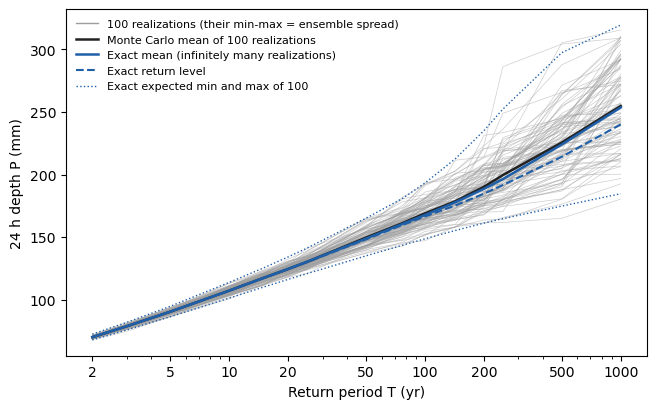

T =  100 yr: Monte Carlo mean 169.0 mm (min-max 147.1-193.5); exact mean 167.7, level 166.5, expected min-max 148.7-193.2
T = 1000 yr: Monte Carlo mean 254.8 mm (min-max 180.4-315.5); exact mean 253.5, level 240.0, expected min-max 184.7-319.5


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

run = "fast_tutorial_data/case1_iowa_pixel/Pixel_r1_A1km2_rot0_24/Pixel_r1_A1km2_rot0_24"
fa = pd.read_csv(run + "_FreqAnalysis.csv", skipinitialspace=True)   # RainyDay's file: rlz1 ... rlz100
ex = pd.read_csv(run + "_FreqExact.csv", comment="#")                # exact engine; '#' lines first
T = ex["returnperiod"]                 # the same rows in both files (_FreqAnalysis.csv rounds T)
rlz = fa.filter(regex=r"^rlz\d+$")

fig, ax = plt.subplots(figsize=(7.5, 4.5))
ax.plot(T, rlz.values, color="#9e9e9e", lw=0.5, alpha=0.5)
ax.plot([], [], color="#9e9e9e", lw=1, label="100 realizations (their min-max = ensemble spread)")
ax.plot(T, rlz.mean(axis=1), color="#222222", lw=1.8, label="Monte Carlo mean of 100 realizations")
ax.plot(T, ex["mean"], color="#1f5fa8", lw=1.8, label="Exact mean (infinitely many realizations)")
ax.plot(T, ex["level"], color="#1f5fa8", lw=1.5, ls="--", label="Exact return level")
ax.plot(T, ex[["exp_min_100", "exp_max_100"]].values, color="#1f5fa8", lw=1, ls=":")[0].set_label("Exact expected min and max of 100")
ax.set(xscale="log", xlabel="Return period T (yr)", ylabel="24 h depth P (mm)")
ax.set_xticks([2, 5, 10, 20, 50, 100, 200, 500, 1000], ["2", "5", "10", "20", "50", "100", "200", "500", "1000"])
ax.legend(fontsize=8, frameon=False, loc="upper left")
plt.show()
for t in (100, 1000):
    i = int(np.argmin(np.abs(T - t)))
    print("T = %4d yr: Monte Carlo mean %.1f mm (min-max %.1f-%.1f); exact mean %.1f, level %.1f, expected min-max %.1f-%.1f"
          % (t, rlz.values[i].mean(), rlz.values[i].min(), rlz.values[i].max(), ex["mean"][i], ex["level"][i],
             ex["exp_min_100"][i], ex["exp_max_100"][i]))

**What to notice:**
* The black and solid blue lines coincide: 169.0 and 167.7 mm at 100 yr. The gap is the Monte Carlo error of 100 realizations (standard error 0.9 mm). **The exact engine is what infinitely many realizations would give.**
* The dotted lines trace the edges of the grey bundle: 148.7–193.2 mm expected, 147.1–193.5 mm observed at 100 yr.
* The dashed `level` falls below the mean at large *T*: 240.0 against 253.5 mm at 1,000 yr, where each realization's value is its single largest event ([mean or level?](#feat-exact)).
* At 1,000 yr the realizations range from 180 to 316 mm. That is how variable **one** synthetic record is for this catalog; it says nothing about the 22 years the catalog came from.

### Adding the record CI <a class="anchor" id="c1-record"></a>
The record CI answers another question: how much would the estimate change with another 22-year record? The next cell plots the bands of `_RecordCI.csv` relative to the noise-free estimate.

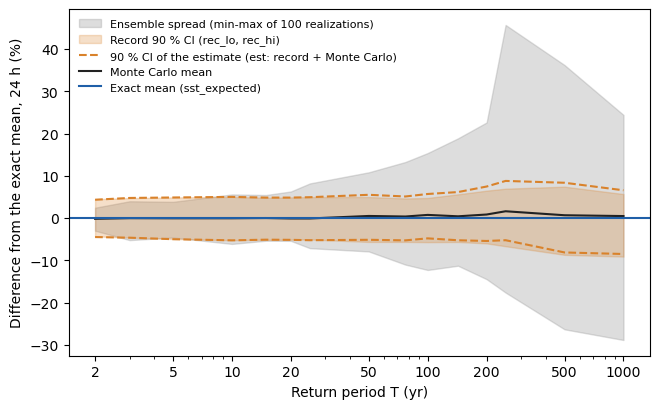

 T (yr)  ensemble spread, half-width (%)  record CI, half-width (%)
   10.0                              5.9                        5.1
  100.0                             13.8                        5.2
 1000.0                             26.6                        7.4


In [2]:
rc = pd.read_csv(run + "_RecordCI.csv", comment="#")      # 24 h; '#' lines define every column
est0 = rc["sst_expected"]                                 # noise-free estimate (= exact mean)
def pct(col):
    return 100 * (rc[col] - est0) / est0

fig, ax = plt.subplots(figsize=(7.5, 4.5))
ax.fill_between(T, pct("ens_lo"), pct("ens_hi"), color="#9e9e9e", alpha=0.35, label="Ensemble spread (min-max of 100 realizations)")
ax.fill_between(T, pct("rec_lo"), pct("rec_hi"), color="#d9822b", alpha=0.25, label="Record 90 % CI (rec_lo, rec_hi)")
ax.plot(T, pct("est_lo"), color="#d9822b", lw=1.5, ls="--", label="90 % CI of the estimate (est: record + Monte Carlo)")
ax.plot(T, pct("est_hi"), color="#d9822b", lw=1.5, ls="--")
ax.plot(T, pct("rd_mean"), color="#222222", lw=1.5, label="Monte Carlo mean")
ax.axhline(0, color="#1f5fa8", lw=1.5, label="Exact mean (sst_expected)")
ax.set(xscale="log", xlabel="Return period T (yr)", ylabel="Difference from the exact mean, 24 h (%)")
ax.set_xticks([2, 5, 10, 20, 50, 100, 200, 500, 1000], ["2", "5", "10", "20", "50", "100", "200", "500", "1000"])
ax.legend(fontsize=8, frameon=False, loc="upper left")
plt.show()
half = lambda lo, hi: (50 * (rc[hi] - rc[lo]) / est0).round(1)
print(pd.DataFrame({"T (yr)": T.round(0), "ensemble spread, half-width (%)": half("ens_lo", "ens_hi"),
                    "record CI, half-width (%)": half("rec_lo", "rec_hi")}).iloc[[3, 9, 14]].to_string(index=False))

**What to notice:**
* **The record CI is narrower than the ensemble spread** above 20 yr: ±5 % against ±14 % at 100 yr (158–176 against 147–194 mm). Up to 20 yr they are alike, and at 2 yr the record CI is even wider (±4 % against ±3 %). They measure different things: the ensemble spread describes one synthetic record, whose 100-yr value rests on its 10 largest events; the record CI describes the estimate, an average over all realizations.
* **The grey edges are jagged** (see 250 yr): the min and max of 100 realizations are noisy themselves; `exp_min_100` and `exp_max_100` are their noise-free versions.
* **est hugs the record CI.** It is centred on the Monte Carlo mean, so it is shifted by that mean's error (most visible at 250 yr), but the Monte Carlo error (0.6 % at 100 yr) hardly widens it.
* **At 1,000 yr the record CI is lopsided** (230–268 mm around 254 mm) and a **lower bound**: resampling years cannot create a storm bigger than the largest observed.

### Depth–duration at 100 years, with Atlas 14 <a class="anchor" id="c1-a14"></a>
Now all seven durations at 100 yr, from one `_RecordCI.csv` per duration (which also holds the ensemble spread), with Atlas 14.

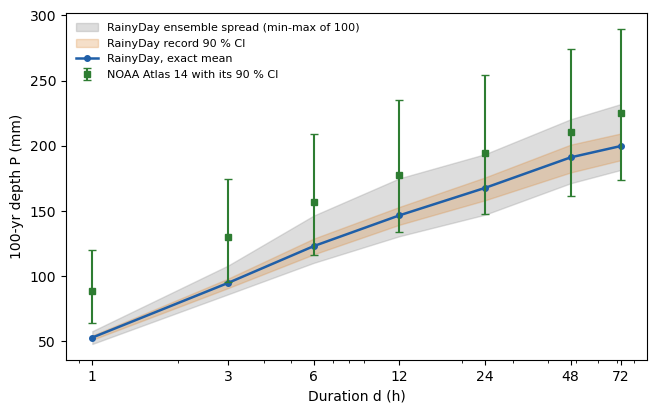

                                                 1      3      6      12     24     48     72
RainyDay / Atlas 14                             0.6   0.73   0.79   0.82   0.86   0.91   0.89
top of record CI below Atlas 14's lower bound  True  False  False  False  False  False  False


In [3]:
durs = [1, 3, 6, 12, 24, 48, 72]
a14 = pd.read_csv("fast_tutorial_data/case1_iowa_pixel/atlas14_070600040101.csv", comment="#")
a14 = a14[(a14["ari_yr"] == 100) & a14["duration_h"].isin(durs)].set_index("duration_h")
a14.index = a14.index.astype(int)
rows = []
for d in durs:
    f = "fast_tutorial_data/case1_iowa_pixel/Pixel_r1_A1km2_rot0_%d/Pixel_r1_A1km2_rot0_%d_RecordCI.csv" % (d, d)
    r = pd.read_csv(f, comment="#")
    rows.append(r[np.isclose(r["returnperiod"], 100)].iloc[0])
dd = pd.DataFrame(rows, index=durs)

fig, ax = plt.subplots(figsize=(7.5, 4.5))
ax.fill_between(durs, dd["ens_lo"], dd["ens_hi"], color="#9e9e9e", alpha=0.35, label="RainyDay ensemble spread (min-max of 100)")
ax.fill_between(durs, dd["rec_lo"], dd["rec_hi"], color="#d9822b", alpha=0.25, label="RainyDay record 90 % CI")
ax.plot(durs, dd["sst_expected"], color="#1f5fa8", lw=1.8, marker="o", ms=4, label="RainyDay, exact mean")
ax.errorbar(a14.index, a14["depth_mm"], yerr=[a14["depth_mm"] - a14["lower90_mm"], a14["upper90_mm"] - a14["depth_mm"]],
            fmt="s", ms=5, color="#2e7d32", lw=1.5, capsize=3, label="NOAA Atlas 14 with its 90 % CI")
ax.set(xscale="log", xlabel="Duration d (h)", ylabel="100-yr depth P (mm)")
ax.set_xticks(durs, [str(d) for d in durs])
ax.legend(fontsize=8, frameon=False, loc="upper left")
plt.show()
print(pd.DataFrame({"RainyDay / Atlas 14": (dd["sst_expected"] / a14["depth_mm"]).round(2),
                    "top of record CI below Atlas 14's lower bound": dd["rec_hi"] < a14["lower90_mm"]}).T.to_string())

**What to notice:**
* **From 6 to 72 h,** the estimate and its record CI lie inside Atlas 14's 90 % CI, at 0.79–0.91 of Atlas 14.
* **At 1 h it is far too low:** 52.9 mm, 0.60 of Atlas 14's 88.7 mm; even the top of the record CI is below Atlas 14's lower bound, at every Atlas 14 return period from 2 to 1,000 yr. At 3 h the estimate is below that bound up to 100 yr.
* **This gap is not the code.** AORC smooths hourly peaks (about 0.8 of rain gauges at 1 h), so short-duration SST depths from AORC are low ([Data issues](#fast-data)). The record CI describes the sampling of 22 years, not a bias in the data.
* **Compare like with like:** Atlas 14's bars are a CI of its estimate; set them next to the record CI (or est), not the grey ensemble spread.

### The numbers at 24 h <a class="anchor" id="c1-table"></a>
A last cell lists the key numbers at 24 h.

In [4]:
rc24 = pd.read_csv(run + "_RecordCI.csv", comment="#")
a24 = pd.read_csv("fast_tutorial_data/case1_iowa_pixel/atlas14_070600040101.csv", comment="#")
a24 = a24[a24["duration_h"] == 24].set_index("ari_yr")
span = lambda lo, hi: lo.map("{:.0f}".format) + "-" + hi.map("{:.0f}".format)
tab = pd.DataFrame({"T (yr)": rc24["returnperiod"].round(0).astype(int),
                    "MC mean": rc24["rd_mean"].round(1), "exact mean": rc24["sst_expected"].round(1),
                    "level": rc24["sst_level"].round(1), "ensemble min-max": span(rc24["ens_lo"], rc24["ens_hi"]),
                    "record CI": span(rc24["rec_lo"], rc24["rec_hi"]), "est": span(rc24["est_lo"], rc24["est_hi"]),
                    "pred": span(rc24["pred_lo"], rc24["pred_hi"])}).iloc[[3, 9, 14]].set_index("T (yr)")
tab["Atlas 14 (90 % CI)"] = [("%.0f (%.0f-%.0f)" % tuple(a24.loc[t, ["depth_mm", "lower90_mm", "upper90_mm"]])) for t in tab.index]
print("24 h depths (mm); ranges are min-max (ensemble) or 90 % intervals")
print(tab.to_string())

24 h depths (mm); ranges are min-max (ensemble) or 90 % intervals
        MC mean  exact mean  level ensemble min-max record CI      est     pred Atlas 14 (90 % CI)
T (yr)                                                                                            
10        107.3       107.3  107.1          101-113   102-113  102-113  100-114       116 (95-141)
100       169.0       167.7  166.5          147-194   158-176  160-177  152-187      194 (148-254)
1000      254.8       253.5  240.0          180-316   230-268  232-270  199-309      297 (203-409)


**What to notice:** from 25 yr on, `pred` lies between the record CI and the min–max of 100 realizations; up to 20 yr it is slightly wider than the min–max (100–114 against 101–113 mm at 10 yr). It is the 90 % range of what **one** synthetic record might show had the 22 years been different: useful for single realizations (e.g. flood-model scenarios), never as the CI of the estimate.

## Part 4: Concluding remarks on the Iowa case study <a class="anchor" id="c1-conclusions"></a>
1. **One run gives everything.** Under two minutes on a reused catalog gave seven durations, 15 return periods, both engines and every band.
2. **The exact engine and the realizations agree,** within the Monte Carlo error. For frequency curves alone, FREQENGINE "exact" gives the same answer without the noise.
3. **Report the estimate with its record CI (or est), not the ensemble spread.** At 100 yr the record CI of this pixel is ±3–6 % at every duration, the ensemble spread ±9–15 %, because it describes single realizations. At 500–1,000 yr the record CI is only a lower bound.
4. **Mind the short durations.** From 6 to 72 h the pixel agrees with Atlas 14; at 1–3 h it is well below, because AORC smooths hourly peaks. No band can reveal a bias in the input data.

# Case Study 2: Real basin vs its spread-matched ellipse <a class="anchor" id="case2"></a>
**Why we ask.** SST results for synthetic shapes (ellipses of given area *A*, axis ratio *R* = *a*/*b* and orientation) generalise far better than results for one real basin, but only if an ellipse can stand in for a real basin. So we ask: does the rainfall frequency of HUC-8 07100006 in Iowa (about 6,400 km<sup>2</sup>) differ from that of its equivalent ellipse by more than 5 %? This follows the original guide's [Big Thompson case study](RainyDay_Tutorial.ipynb#BigThompsonExample) in form; as in [Case Study 1](#case1), the cells only read the outputs in `fast_tutorial_data/case2_huc07100006/`.

**The spread-matched ellipse** ("rg", for radius of gyration) has the basin's area and orientation. Its axis ratio solves *R* + 1/*R* = 4π·tr(Cov)/*A*, where Cov is the covariance matrix of the coordinates of the basin's cells, so it has the same spatial spread as the basin (our work in preparation). Here *R* = 4.6.

## Part 1: Setting up the two runs <a class="anchor" id="c2-setup"></a>
`Basin_raw_Iowa_HUC_07100006.json` (the real basin) and `Basin_rg_Iowa_HUC_07100006.json` (the ellipse) are the [Case Study 1 control file](#c1-json) with four keys changed. The real basin:
```json
{
    "SCENARIONAME": "Basin_raw_Iowa_HUC_07100006",
    "CATALOGNAME": "Basin_raw_Iowa_HUC_07100006.nc",
    "WATERSHEDSHP": "{path}/Basin_raw_Iowa_HUC_07100006.shp",
    "CATALOGPATH": "{path}/Basin_raw_Iowa_HUC_07100006_72/StormCatalog/Basin_raw_Iowa_HUC_07100006.nc"
}
```
The ellipse:
```json
{
    "SCENARIONAME": "Basin_rg_Iowa_HUC_07100006",
    "CATALOGNAME": "Basin_rg_Iowa_HUC_07100006.nc",
    "WATERSHEDSHP": "{path}/Basin_rg_Iowa_HUC_07100006.shp",
    "CATALOGPATH": "{path}/Basin_rg_Iowa_HUC_07100006_72/StormCatalog/Basin_rg_Iowa_HUC_07100006.nc"
}
```
**Each run uses its own catalog,** built with its own mask: the 400 storms largest **for that shape** (12–26 per record year for the real basin, 13–24 for the ellipse). That is what you would do in practice.

**Both runs draw the same record years:** the same INCLUDEYEARS, RECORDSEED, RECORDNBOOT and RECORDBLOCK give identical `_RecordDraws.csv` files, which [compare_runs](#feat-compare) checks. It pairs bootstrap record *b* of one run with record *b* of the other.

## Part 2: Running RainyDay_fast and compare_runs <a class="anchor" id="c2-run"></a>
Create MAINPATH first ([Getting Started](#start-mainpath)), then run both control files:

>python {path}/RainyDay_fast/Source/RainyDay_Py3.py {path}/Basin_raw_Iowa_HUC_07100006.json<br>
>python {path}/RainyDay_fast/Source/RainyDay_Py3.py {path}/Basin_rg_Iowa_HUC_07100006.json<br>

Each run took about 3 minutes on our Mac. Then three comparisons, with Δ = 100 (rg − raw)/raw:

>python {path}/RainyDay_fast/tools/compare_runs.py {MAINPATH}/Basin_raw_Iowa_HUC_07100006 {MAINPATH}/Basin_rg_Iowa_HUC_07100006 --stat median --engine montecarlo --out compare_median_montecarlo.csv<br>
>python {path}/RainyDay_fast/tools/compare_runs.py {MAINPATH}/Basin_raw_Iowa_HUC_07100006 {MAINPATH}/Basin_rg_Iowa_HUC_07100006 --engine exact --stat mean --out compare_mean_exact.csv<br>
>python {path}/RainyDay_fast/tools/compare_runs.py {MAINPATH}/Basin_raw_Iowa_HUC_07100006 {MAINPATH}/Basin_rg_Iowa_HUC_07100006 --stat level --out compare_level.csv<br>

The first compares the medians of the realizations, the others the exact `mean` and `level`, with the default margin (±5 %) and level (90 %). They took 3.4, 0.6 and 0.6 s.

**Hint:** the data folder keeps RainyDay's layout, so the first two commands also run on `fast_tutorial_data/case2_huc07100006/Basin_raw_Iowa_HUC_07100006` and `..._rg_...` and give the same CSVs, plus a last column `rec_source`. These runs predate `_RecordBootstrapMedian.csv`, so the first command borrows the mean's record bootstrap for the median, as these CSVs did, and prints a warning; runs that include the file give the same 105 classes. The third needs `_RecordBootstrapLevel.csv`, which we left out.

## Part 3: Results <a class="anchor" id="c2-rfa"></a>
### Two depth–duration curves <a class="anchor" id="c2-curves"></a>
First, the 100-yr depths of both shapes with their record CIs (`sst_expected` is the exact mean).

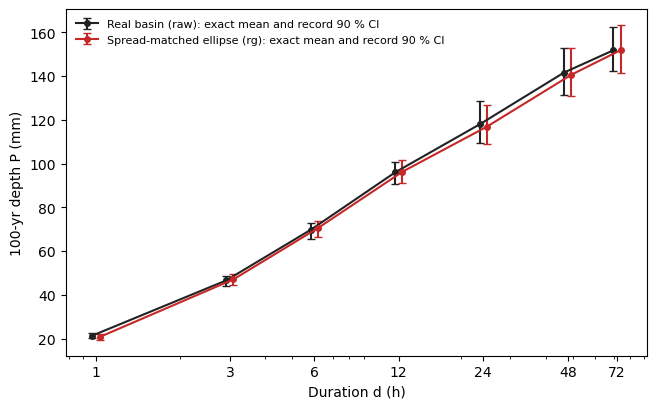

                  1      3      6      12      24      48      72
raw (mm)       21.42  46.64  69.76  96.02  117.97  141.65  151.86
rg (mm)        20.78  47.15  70.57  96.32  116.92  140.66  151.93
rg vs raw (%)  -2.98   1.08   1.17   0.31   -0.89   -0.70    0.05


In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

base = "fast_tutorial_data/case2_huc07100006/"
durs = [1, 3, 6, 12, 24, 48, 72]
def at100(shape, kind="RecordCI"):          # one row per duration: the T = 100 yr row of each file
    rows = []
    for d in durs:
        n = "Basin_%s_Iowa_HUC_07100006_%d" % (shape, d)
        f = pd.read_csv(base + n + "/" + n + "_" + kind + ".csv", comment="#")
        rows.append(f[np.isclose(f["returnperiod"], 100)].iloc[0])
    return pd.DataFrame(rows, index=durs)
raw, rg = at100("raw"), at100("rg")

fig, ax = plt.subplots(figsize=(7.5, 4.5))
for df, col, lab, shift in [(raw, "#222222", "Real basin (raw)", 0.97), (rg, "#c62828", "Spread-matched ellipse (rg)", 1.03)]:
    y = df["sst_expected"]
    ax.errorbar(np.array(durs) * shift, y, yerr=[y - df["rec_lo"], df["rec_hi"] - y], color=col, lw=1.5,
                marker="o", ms=4, capsize=3, label=lab + ": exact mean and record 90 % CI")
ax.set(xscale="log", xlabel="Duration d (h)", ylabel="100-yr depth P (mm)")
ax.set_xticks(durs, [str(d) for d in durs])
ax.legend(fontsize=8, frameon=False, loc="upper left")
plt.show()
print(pd.DataFrame({"raw (mm)": raw["sst_expected"], "rg (mm)": rg["sst_expected"],
                    "rg vs raw (%)": 100 * (rg["sst_expected"] / raw["sst_expected"] - 1)}).round(2).T.to_string())

**What to notice:** the curves agree within 3 % at every duration (rg is 3.0 % lower at 1 h). Each record CI is ±5–8 % and they overlap almost completely, but that tells you little: both runs share the same 22 years, so a record that is wetter for one shape is wetter for the other. What matters is the CI of the **difference**.

### The difference and its class <a class="anchor" id="c2-delta"></a>
The next cell plots Δ at 100 yr from the three tables, with its combined 90 % CI (Monte Carlo and record errors) and the ±5 % band. Filled markers are "equivalent", open ones "inconclusive"; no row is an "increase" or "decrease".

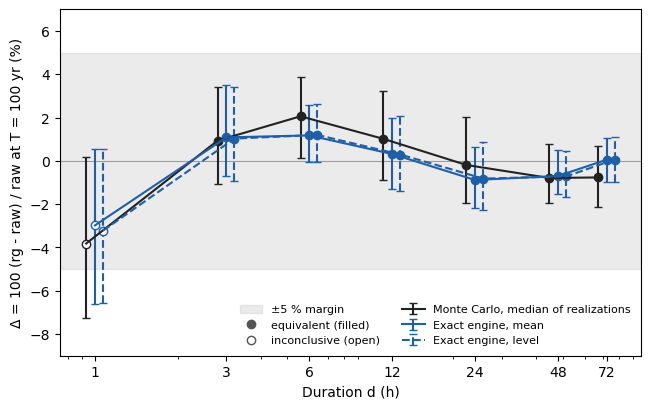

In [6]:
files = {"Monte Carlo, median of realizations": ("compare_median_montecarlo.csv", "#222222", "-", 0.93),
         "Exact engine, mean": ("compare_mean_exact.csv", "#1f5fa8", "-", 1.0),
         "Exact engine, level": ("compare_level.csv", "#1f5fa8", "--", 1.07)}
fig, ax = plt.subplots(figsize=(7.5, 4.5))
ax.axhspan(-5, 5, color="#9e9e9e", alpha=0.2, label="±5 % margin")
ax.axhline(0, color="#9e9e9e", lw=0.8)
for lab, (f, col, ls, shift) in files.items():
    c = pd.read_csv(base + f)
    c = c[np.isclose(c["returnperiod"], 100)]
    x, y = c["duration_h"].values * shift, c["delta_pct"].values
    eb = ax.errorbar(x, y, yerr=[y - c["comb_ci90_lo"], c["comb_ci90_hi"] - y], color=col, lw=1.5, ls=ls, capsize=3, label=lab)
    eb[-1][0].set_linestyle(ls)
    eq = (c["class"] == "equivalent").values
    ax.plot(x[eq], y[eq], "o", color=col, ms=6)
    ax.plot(x[~eq], y[~eq], "o", color=col, mfc="white", ms=6)
ax.plot([], [], "o", color="#555555", label="equivalent (filled)")
ax.plot([], [], "o", color="#555555", mfc="white", label="inconclusive (open)")
ax.set(xscale="log", xlabel="Duration d (h)", ylabel="Δ = 100 (rg - raw) / raw at T = 100 yr (%)", ylim=(-9, 7))
ax.set_xticks(durs, [str(d) for d in durs])
ax.legend(fontsize=8, frameon=False, loc="lower right", ncol=2)
plt.show()

**What to notice:**
* **From 3 to 72 h, all three are "equivalent":** Δ is between −0.9 and +2.1 %, with the 90 % CI inside ±5 %.
* **At 1 h, all three are "inconclusive":** Δ is −3.8 % (median), −3.0 % (mean) and −3.2 % (level), with the CI reaching −7.2, −6.6 and −6.6 %. The ellipse may be up to 7 % low, or no lower at all; 22 years of data cannot tell.
* **Monte Carlo noise shows in the median:** at 6 h it gives +2.1 %, the exact mean +1.2 %. The exact `mean` and `level` agree within 0.3 points at every duration at 100 yr (within 1.5 points over all 105 rows).

### Counting the classes <a class="anchor" id="c2-classes"></a>
Each table has 105 rows (7 durations × 15 return periods). The next cell counts the classes with the Monte Carlo part alone (`class_mc`) and with both parts (`class`), and crosses the two engines row by row.

In [7]:
order = ["equivalent", "inconclusive", "increase", "decrease"]
counts = {}
for lab, (f, _, _, _) in files.items():
    c = pd.read_csv(base + f)
    counts[lab + ": Monte Carlo part only"] = c["class_mc"].value_counts()
    counts[lab + ": Monte Carlo + record"] = c["class"].value_counts()
print(pd.DataFrame(counts).reindex(order).fillna(0).astype(int).T.to_string())
mc, ex = pd.read_csv(base + "compare_median_montecarlo.csv"), pd.read_csv(base + "compare_mean_exact.csv")
print("\nRow by row (Monte Carlo + record):")
print(pd.crosstab(mc["class"], ex["class"], rownames=["Monte Carlo median"], colnames=["exact mean"]).to_string())
left = ex[ex["class"] == "inconclusive"]
print("\nStill inconclusive with the exact engine:", ", ".join("%g h %g yr" % (d, t) for d, t in zip(left["duration_h"], left["returnperiod"])))

                                                            equivalent  inconclusive  increase  decrease
Monte Carlo, median of realizations: Monte Carlo part only         100             5         0         0
Monte Carlo, median of realizations: Monte Carlo + record           86            19         0         0
Exact engine, mean: Monte Carlo part only                          105             0         0         0
Exact engine, mean: Monte Carlo + record                            93            12         0         0
Exact engine, level: Monte Carlo part only                         105             0         0         0
Exact engine, level: Monte Carlo + record                           93            12         0         0

Row by row (Monte Carlo + record):
exact mean          equivalent  inconclusive
Monte Carlo median                          
equivalent                  86             0
inconclusive                 7            12

Still inconclusive with the exact engine: 1 h 25

**What to notice:**
* **Monte Carlo median:** 86 equivalent, 19 inconclusive; with the Monte Carlo part alone, 100 and 5. The record CI turns 14 rows inconclusive.
* **Exact mean and level:** 93 equivalent, 12 inconclusive. Their Monte Carlo part has zero width, so only the record CI decides.
* **No increase or decrease** with either engine.
* **The exact engine moves 7 rows from inconclusive to equivalent, and none back:** Δ is no longer shifted by Monte Carlo noise, and its CI loses the Monte Carlo part. The 12 rows left are at 1 h (25–1,000 yr) and 3 h (250–1,000 yr); only more years of data would narrow them.

### Why the record CI of Δ is small <a class="anchor" id="c2-cancel"></a>
The last cell compares the record CI of each 100-yr depth with that of Δ, and correlates the 1,000 bootstrap depths of the two shapes.

In [8]:
braw, brg = at100("raw", "RecordBootstrap"), at100("rg", "RecordBootstrap")
recs = [c for c in braw.columns if c.startswith("rec")]          # rec1 ... rec1000: one value per bootstrap record
dl = pd.read_csv(base + "compare_mean_exact.csv")
dl = dl[np.isclose(dl["returnperiod"], 100)].set_index("duration_h")
dl.index = dl.index.astype(int)
half = lambda df: 50 * (df["rec_hi"] - df["rec_lo"]) / df["sst_expected"]
print(pd.DataFrame({"raw depth: record CI, half-width (%)": half(raw), "rg depth: record CI, half-width (%)": half(rg),
                    "Δ: record CI, half-width (pp)": (dl["rec_ci90_hi"] - dl["rec_ci90_lo"]) / 2,
                    "correlation of the bootstrap depths": [np.corrcoef(braw.loc[d, recs].astype(float), brg.loc[d, recs].astype(float))[0, 1] for d in durs]},
                   index=durs).round(2).T.to_string())

                                        1     3     6     12    24    48    72
raw depth: record CI, half-width (%)  5.44  5.35  5.35  5.46  8.17  7.72  6.55
rg depth: record CI, half-width (%)   6.48  5.34  5.29  5.65  7.53  7.64  7.22
Δ: record CI, half-width (pp)         3.48  2.09  1.30  1.63  1.39  1.03  1.01
correlation of the bootstrap depths   0.83  0.93  0.97  0.96  0.99  0.99  0.99


**What to notice:** at 24 h each depth has a record CI of about ±8 %, Δ only ±1.4 points. The years that make one shape wetter make the other wetter too (their bootstrap depths correlate at 0.99 from 24 to 72 h), so most of the record uncertainty cancels. At 1 h the correlation drops to 0.83 and Δ's record CI widens to ±3.5 points; hence the inconclusive 1 h rows. Because each shape has its own catalog, the cancellation is never complete.

## Part 4: Concluding remarks on the HUC-8 case study <a class="anchor" id="c2-conclusions"></a>
1. **The ellipse can stand in for this basin from 3 to 72 h.** With the exact engine it is equivalent (90 % CI of Δ inside ±5 %) at 6–72 h for all return periods from 2 to 1,000 yr, and at 3 h up to 200 yr. Nothing is classed as different.
2. **At 1 h the answer is "we cannot tell", not "different".** The ellipse is about 3 % low, and the CI of Δ crosses −5 % from 25 yr on; only a longer record could resolve it.
3. **Use the exact engine for comparisons.** It removes the Monte Carlo noise from Δ and its CI, moved 7 rows to "equivalent", and compares in 0.6 s.
4. **Judge differences by the CI of Δ, never by overlapping bands.** Shared years cancel: the record CI of Δ is 1.6 to 7.5 times narrower than that of each depth.

# Validation: how we know the results are right <a class="anchor" id="fast-validation"></a>
This section is for you if you want to trust RainyDay_fast before you use it. A change that should not alter results (a speed-up, an option left off, a new output file) must give **bit-identical** outputs. A new calculation (the [record CI](#feat-recordci), the [exact engine](#feat-exact)) must agree with an independent method within that method's known error. The [ground rule](#intro-bitidentity) and its limits are in the introduction; here is the evidence.

## What "bit-identical" means, and how we check it <a class="anchor" id="val-bitidentity"></a>
Bit-identical means the output files are the same byte for byte. That is much stronger than "the same results": one changed random draw, or one storm placed one cell away, fails it.

**The validation matrix** is five basins: the Talequah example (a smoke test), the Iowa pixel (one grid cell, where the overheads of the frequency analysis dominate), an Iowa circle of 16,000 km<sup>2</sup> (the largest basin), an Iowa ellipse of the same area with *R* = 10 rotated 45° (a basin box much larger than the basin), and the Texas HUC-12 120401020101 (a real basin on another domain). The Iowa and Texas basins use our production settings: NSTORMS 400, a 72 h light catalog on a crop of our corrected AORC data ([Data issues](#fast-data)), MULTIPLEDURATIONS 1–72 h with the table engine, NYEARS 1000, 100 realizations, 10 return periods from 2 to 1000 yr, PDS, uniform transposition, Poisson resampling and INCLUDEYEARS 2002–2023. Talequah uses 10 storms, NYEARS 100 and 5 realizations. The scan engine is `batchfft`.

**`tools/compare_dumps.py`** compares, basin by basin, a reference run and a test run:
1. **the raw transposed depths** of every duration before ranking (saved with `RAINYDAY_DUMP_WHICHRAIN`, [Appendix D](#appD)): if these are bitwise equal, so are the random draws, storm positions and basin sums;
2. **every `_FreqAnalysis.csv`**, byte for byte;
3. **the storm catalog** (`--catalogs`): a full one with `compare_catalogs.py` at zero tolerance, a light one variable by variable, bitwise.

**"ALL PASS, 80 checks"** is 16 checks per basin: the list of raw-depth files, 7 raw-depth files, 7 CSVs and the catalog. The 55 PNG files of a run (35 frequency plots, 20 diagnostic maps) are compared separately.

**Reference runs.** The speed-ups were compared with RainyDay_mod `9137292`: ALL PASS, 89 checks, including the CSVs of our earlier production campaign. The record CI and the exact engine were compared with RainyDay_fast `main` (`b63865a`): ALL PASS, 80 checks for each set of runs, 55 of 55 PNG files identical.

**Catalogs from different scan engines.** Storms, time windows, positions and rain fields are bitwise identical. Only the stored storm total (`basinrainfall`) is compared with a relative tolerance of 10<sup>-5</sup>, because batching adds the same numbers in another order; the measured difference was zero for every CPU engine, and between `batchcuda` and `batchfft` on Windows. This total feeds only the diagnostic plots and the storm ranking.

## Evidence for each feature <a class="anchor" id="val-features"></a>

| Feature | How we checked it | Result |
|---|---|---|
| [Cropped input](#feat-crop) | `make_domain_crop.py --verify` (RainyDay's reader on every file; grid and masks); whole runs | Talequah, Iowa pixel, Texas HUC: catalogs, raw depths, CSVs identical |
| [Light catalog](#feat-light) | `compare_light_catalog.py` against full catalogs; `test_light_rebuild.py` (the rebuild against RainyDay's write loop, with missing days) | Every storm bitwise equal to RainyDay_mod's; matrix ALL PASS, also when reusing a catalog |
| [Scan engines](#feat-engines) | `compare_catalogs.py` against `fft_perstep` catalogs (Talequah; CONUS, July 2002); `test_domainaware_equivalence.py` (a concave domain with a hole) | ALL PASS; the same placement at every time step |
| [Table engine](#feat-table) | Verify mode at 1 % (about 18,000 draws per basin by brute force); `verify_fast_sst.py --asm` | 0 mismatches; the same machine code as RainyDay's summing function |
| [MULTIPLEDURATIONS](#feat-multidur) | Every CSV against separate runs of the earlier code (Iowa pixel and 16,000 km<sup>2</sup>, 7 durations; Texas 8,000 km<sup>2</sup>, 1 and 72 h); `test_multidurations.sh` | Byte-identical; "fast" and "exact" raw depths bitwise equal |
| [RECORDCI](#feat-recordci) | Matrix with the option off and on; our earlier prototype; 22 real runs ([below](#val-record)); `test_record_ci.py` | ALL PASS, 80 checks each; prototype matched to every printed decimal |
| [FREQENGINE](#feat-exact) | Matrix with "montecarlo" and "both"; "exact" against "both"; exact values against the realizations ([below](#val-exact)); 16 more unit tests | ALL PASS, 80 checks each; "exact" catalogs bitwise equal; `_FreqExact.csv` 35 of 35 byte-identical |
| [October 2026 fixes](#bug-new) | `test_parsing.py` (72 checks: old and new parsing on every input that already worked); `test_rect_catalog.py` (19 checks: brute force on rectangles); short runs; the full matrix (options off, FREQENGINE "both", RECORDCI with "both") | ALL PASS; Talequah identical to the code before the fixes; matrix ALL PASS, 80 checks per variant |

## The exact engine against Monte Carlo, in plain words <a class="anchor" id="val-exact"></a>
The exact engine reproduces no Monte Carlo file, so bit-identity cannot test it. Instead we ran the matrix with `FREQENGINE` "both", which writes the exact values **and** the realizations of the same run, and asked whether the realizations look like random samples from the exact distribution. There are 322 cells (4 basins × 7 durations × 10 return periods, plus Talequah's 7 × 6), tested by `tools/verify_exact_engine.py`:

* **The mean.** Per cell, z = (realization mean − exact mean) / (standard error of the realization mean). If the exact mean is right, z is close to a standard normal variable: half the cells should have |z| below 0.67, and about 5 % above 2. In the 280 Iowa and Texas cells the median |z| is 0.66; 5 cells (1.8 %) exceed 2, none exceeds 3, and the largest is 2.64. Over all 322 cells the median is 0.73.
* **The quantiles** of one realization's T-yr depth (5–95 %). If a quantile is right, the number of realizations below it is a binomial count: for the median and 100 realizations, 37 to 63 in 99 % of cells. Of 1,610 quantiles, 1,603 fall inside their 99 % range, and 1,570 inside the 95 % range.
* **The smallest and largest realization** should fall in the central 90 % of the exact distribution of the minimum (or maximum) of *N* draws (100; 5 for Talequah) in 90 % of cells. They do in 288 of 322 (89.4 %) and 289 of 322 (89.8 %).

**The worst cell is chance.** It is Talequah, 6 h, *T* = 2 yr, with z = 3.87. Talequah has only 5 realizations, so the standard error itself comes from 5 values, and the right reference is Student's t with 4 degrees of freedom: p = 0.018, not unusual among 42 cells. The next two worst cells (48 and 72 h, *T* = 2 yr) use the same 5 realizations, so they are not separate evidence.

The cell below draws the histogram of z for the 280 Iowa and Texas cells, with the standard normal curve that z should follow.

Mean, 280 cells: median |z| 0.66; |z| > 2: 5; |z| > 3: 0
All 322 cells: quantiles inside the 99 % band 1603 of 1610; observed min / max inside the central 90 %: 89.4 % / 89.8 %


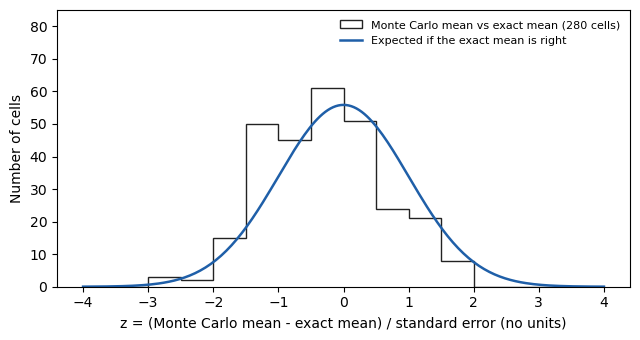

In [9]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

v = pd.read_csv("fast_tutorial_data/validation/verify_exact_both.csv")
big = v[v["N"] == 100]                       # Iowa and Texas: 4 basins x 7 durations x 10 T, 100 realizations
z = big["z_mean"]
print("Mean, %d cells: median |z| %.2f; |z| > 2: %d; |z| > 3: %d"
      % (len(z), z.abs().median(), (z.abs() > 2).sum(), (z.abs() > 3).sum()))
print("All %d cells: quantiles inside the 99 %% band %d of %d; observed min / max inside the central 90 %%: %.1f %% / %.1f %%"
      % (len(v), v["q_ok99"].sum(), 5 * len(v), 100 * v["min_ok"].mean(), 100 * v["max_ok"].mean()))

x = np.linspace(-4, 4, 201)
normal = len(z) * 0.5 * np.exp(-x ** 2 / 2) / np.sqrt(2 * np.pi)     # 0.5 = bin width
fig, ax = plt.subplots(figsize=(6.5, 3.5))
ax.hist(z, bins=np.arange(-4, 4.01, 0.5), histtype="step", color="#222222", lw=1.8,
        label="Monte Carlo mean vs exact mean (%d cells)" % len(z))
ax.plot(x, normal, color="#1f5fa8", lw=1.8, label="Expected if the exact mean is right")
ax.set_xlabel("z = (Monte Carlo mean - exact mean) / standard error (no units)")
ax.set_ylabel("Number of cells")
ax.set_ylim(0, 85)
ax.legend(loc="upper right", fontsize=8, frameon=False)
plt.tight_layout()
plt.show()

**What to notice.** The histogram follows the curve, and nothing lies beyond ±3. It is a little narrower than the curve and shifted slightly left. That is expected: the 70 cells of a basin share the same random draws, so their Monte Carlo errors move together (the Iowa circle's cells average z = −0.9, the Iowa pixel's +0.5). They are not 280 independent tests.

## The record CI against real leave-one-year-out runs <a class="anchor" id="val-record"></a>
The [record CI](#feat-recordci) never reruns RainyDay: it keeps the one storm catalog and reweights each storm by how often its start year is drawn. To test that shortcut, we made 22 real RainyDay runs of the Iowa pixel. Each left out one year of 2002–2023 (INCLUDEYEARS) and **rebuilt its own catalog**. We compared each run with the record method for the same year left out:

| Check | Result |
|---|---|
| RainyDay mean against the record method (198 cases: 1, 24, 72 h; 10, 100, 500 yr; 22 runs) | median −0.17 % (5–95 %: −1.6 to +0.4 %; largest −2.2 %) |
| Spread of the 22 values (jackknife standard error), RainyDay against the record method | median ratio 1.00 (70 duration × return period cells) |
| Bootstrap standard error against the jackknife one | median ratio 0.95 |
| Reweighting the catalog instead of rebuilding it | median 0.000 %; at most 0.14 % in the 198 cases, 0.28 % over all 1,540 (at 1 h, 2 yr) |

Most of the differences in the first row are the Monte Carlo error of the 22 runs themselves (0.2–1.2 % for a mean). The last row is why we say that keeping the catalog fixed changes results by at most 0.14 % in the 198 headline cases, and 0.28 % over all 1,540.

RECORDCI reproduces the prototype used in this test to every printed decimal, including its 22 leave-one-year-out values. Each run also prints how far the realization mean lies from its noise-free value `sst_expected`, in Monte Carlo standard errors, and warns above 4: on the Iowa pixel, median 0.60 and largest 1.74 (70 cells); on the matrix, largest 2.64 in the Iowa and Texas basins (3.87 in Talequah, which has only 5 realizations).

**Limits.** The test used one Iowa grid cell. At 500–1000 yr, record CIs are lower bounds: resampling the record cannot create a storm larger than the largest observed.

## How to run the checks yourself <a class="anchor" id="val-howto"></a>
**1. The unit tests** need no rainfall data. With RainyDay_Env active, run from the repository folder (`cd {path}/RainyDay_fast`), for example:

>python tools/test_record_ci.py<br>

and likewise `test_windowed_block.py`, `test_domainaware_equivalence.py`, `test_parsing.py` and `test_rect_catalog.py` ([Appendix B](#appB-checks)). Each ends with "ALL PASS" (`test_domainaware_equivalence.py` with one "PASS" line).

**2. A regression test on real data**, the Talequah example ([Check that it works](#start-check)):

>bash tools/test_multidurations.sh $(which python) {AORC folder}<br>

**3. Your own runs.** Run a control file twice, changing only the option you want to test (for example `"FREQENGINE": "both"`) and SCENARIONAME, so the second run does not overwrite the first. Then compare: `cmp` prints nothing when two files are identical (on Windows, use `fc /b`). The third line checks a light catalog against a full one:

>cmp {MAINPATH}/RunA_24/RunA_24_FreqAnalysis.csv {MAINPATH}/RunB_24/RunB_24_FreqAnalysis.csv<br>
>python tools/compare_catalogs.py {MAINPATH}/RunA_72/StormCatalog {MAINPATH}/RunB_72/StormCatalog --rtol 0<br>
>python tools/compare_light_catalog.py {MAINPATH}/RunA_72/StormCatalog {MAINPATH}/RunB_72/StormCatalog/MyCatalog_lightcatalog.nc<br>

**4. Built-in checks.** `make_domain_crop.py --verify` checks a crop; `RAINYDAY_VERIFY_TABLE=0.01` makes the table engine recompute 1 % of the draws by brute force and stop at the first mismatch ([Table engine](#feat-table)). The full matrix needs our control files and data ([Appendix B](#appB-dev)).

# Corrected bugs <a class="anchor" id="fast-bugs"></a>
This section lists the bugs we fixed: what was wrong, which settings it needed, what it did to results, what we changed and how we tested it. In each list, the bugs that change results most come first.

**NOTE:** "Original RainyDay" always means commit `b14a011` (17 April 2025). The upstream repository has moved on since then, and newer upstream versions may have fixed some of these bugs on their own. We have not checked them ([lineage](#intro-lineage)).

## Bugs in the original RainyDay that are fixed here <a class="anchor" id="bug-original"></a>

| Bug | It bit you if | Effect on results | What we changed |
|---|---|---|---|
| **Lenient transposition.** Only the corner cell of the basin box had to be inside the domain, so the box could hang partly outside it (up to about 55 % in our SE Texas check) and collect rain there. | DOMAINTYPE "irregular", TRANSPOSITION "uniform", heavy storms near the domain edge | Large near the edge: SE Texas HUC-8, 72 h, 100-yr, 489 → 412 mm ([more](#feat-strict)) | The whole box must lie inside the domain ([Strict transposition](#feat-strict)) |
| **Catalog search on irregular domains.** Iowa domain, one-cell basin: 732 of 35,416 anchors never searched, 116 more overwritten, and half the stored sums (17,284 of 34,568) one cell away. The box could hang outside the domain. | You built a catalog on an irregular domain | Other storms, windows and positions in the catalog; effect on depths not measured | Every anchor whose whole box lies inside the domain is searched exactly ([The domain edge](#feat-catsearch)) |
| **RETURNLEVELS as a JSON list was ignored**, although the original guide's own control files use one | RETURNLEVELS such as `[2, 5, 10]` | Every return period from 1 to NYEARS was written; the values were right | The list is used |
| **A missing time step stopped the catalog** with an IndexError | Gaps in the input data | Crash | The step is filled with zeros, with a message |
| **Write errors were swallowed.** Any OS error other than "permission denied" while writing a storm file was ignored | E.g. a relative path to the control file | Storms silently missing from the catalog | The error is printed and the run stops |
| **Memory tracing** (`tracemalloc`) was on and never read | Every run | None, but about 3× slower frequency analysis on a one-cell basin | Off ([Table engine](#feat-table)) |
| **SCENARIOS sorting** squeezed every dimension of size 1 | SCENARIOS with, e.g., NREALIZATIONS 1 | Wrong scenario files, or a crash | Only the intended dimension is squeezed |
| **Diagnostic plots** drew storm markers at the box corner, with shifted coordinates | DIAGNOSTICPLOTS "true" | Plots only | Markers at the box centre |

**How we tested them.** The strict-transposition locations matched an independent offline calculation exactly. The new search matched a brute-force sum at every anchor on a rectangle (see the rectangular fix below), and the faster engines matched it on a concave domain with a hole. Memory tracing off is bit-identical in the [validation](#fast-validation) matrix. The other fixes date from May 2025 (the write-error fix from July 2026), with no recorded test.

## Bugs fixed in October 2026 <a class="anchor" id="bug-new"></a>
We found these while writing this guide and fixed them on 26 October 2026 (commits `e723e81`, `ed96ce2` and `7ab20cf`).

**Rectangular domains (a bug of the fork itself).**
* **What was wrong.** In May 2025, RainyDay_mod enlarged the search range of irregular domains to reach storms at the edge, and the separate rectangular search got the larger range without being adapted. Since then, a rectangular catalog stopped at the first time step ("ValueError: unable to broadcast") for any basin box 3 or more cells wide or tall, such as the 0.25° box of the original [Madison case study](RainyDay_Tutorial.ipynb#MadisonExample). Boxes of 1–2 cells ran, but kept the original's errors (anchors never searched, sums stored one cell away) and lost the last row and column too.
* **When it bit you.** DOMAINTYPE "rectangular" (the default) with CREATECATALOG "true", or a reused catalog longer than DURATION with DURATIONCORRECTION "false".
* **What we changed.** Rectangular domains use the [exhaustive search](#feat-catsearch) of irregular domains, with the whole rectangle as the domain, one time step at a time (as the `fft_perstep` engine). The faster [engines](#feat-engines) stay irregular-only. CATALOGACCELERATOR has no effect, and the run says so.
* **How we tested it.** Against a brute-force sum at every anchor, for boxes of 1×1, 2×3 and 5×7 cells and a basin mask with a hole, 26 random rain fields each: the same best anchor every time, sums within 2.4 × 10<sup>-7</sup> (relative). Maxima placed at all 8 edge and corner anchors were found. The Talequah box as "rectangular" and as an "irregular" rectangle polygon gave identical catalogs.

**Hint:** Draw your rectangle as an "irregular" polygon: the catalog is identical, and the faster engines work.

**Control-file parsing.** The original RainyDay (and RainyDay_mod) read these inputs wrongly. Each field is described in [Changed fields](#field-changed).

| You wrote | Before | Now |
|---|---|---|
| EXCLUDEMONTHS "12-3" (across the new year) | nothing excluded | December–March excluded |
| EXCLUDEMONTHS "8" or EXCLUDESTORMS "17" (one value) | nothing excluded | excluded |
| EXCLUDEMONTHS `["8"]` or INCLUDEYEARS `["2002"]` (lists of strings) | months: nothing excluded; years: crash | read as numbers |
| INCLUDEYEARS "all" or "none" | all years, by accident | all years, on purpose ("" too) |
| EXCLUDEMONTHS on a reused catalog, without INCLUDEYEARS | storm arrays out of line with the storm files (372 of 377 rows on an Iowa catalog) | aligned |
| An unknown CALCTYPE, e.g. "foo" | "Defaulting to Annual Maxima Series", then a crash after the catalog | stops at the start |
| UNCERTAINTY 90 (a JSON number) | silently the min–max | 5th–95th percentiles |
| UNCERTAINTY "90" (a string) | crash at the very end of the run | 5th–95th percentiles |
| A required key left out | a Python KeyError | one message naming every missing key |
| NSTORMS left out, reused catalog | crash (NameError) | every storm in the catalog |
| RETURNLEVELS "2,5,10" | worked in the original; stopped since RainyDay_mod | same as `[2, 5, 10]` |

**Beyond the bug list:** an unreadable string in EXCLUDEMONTHS, INCLUDEYEARS or EXCLUDESTORMS (e.g. "summer") now **stops** the run and lists the accepted formats; before, it was ignored silently. A non-string CALCTYPE also stops (it ran as AMS). Other UNCERTAINTY strings, such as "false" in the Talequah example, still mean "ensemble", with a message. `make_domain_crop.py` reads INCLUDEYEARS and EXCLUDEMONTHS with the same rules.

**How we tested them.** A new test (72 checks) runs verbatim copies of the old parsing code next to the new code: every input that already worked, including our study and test control files, gives identical objects, down to the number types. Talequah runs with UNCERTAINTY 90 and "90" wrote exactly the 5th percentile, mean and 95th percentile of the raw realizations. Leaving out NSTORMS, or RETURNLEVELS as a string, gave byte-identical CSVs to the explicit forms. The full [validation](#fast-validation) matrix (5 shapes; options off, FREQENGINE "both", and RECORDCI with "both") is bit-identical to RainyDay_fast before the fixes: all 80 checks pass in each case. All unit tests pass: 72/72 for parsing, 19/19 for the rectangular search, and 44/44 for the record CI and the exact engine.

**Which fixes change the results of runs that used to finish?** Those for rectangular domains with a basin box of 1–2 cells (a new catalog), a reused catalog with EXCLUDEMONTHS and no INCLUDEYEARS, UNCERTAINTY as a JSON number (the band, not the mean), and the EXCLUDEMONTHS and EXCLUDESTORMS spellings in the table; [Were my earlier results affected?](#bug-affected) says what to do. Unreadable strings and a non-string CALCTYPE now stop. The other fixes only touch inputs that crashed before; every other control file, ours included, reads exactly as before. Compared with the original RainyDay, every rectangular catalog changes, because the original search missed anchors and shifted sums.

## Bugs introduced and fixed during development <a class="anchor" id="bug-internal"></a>
These were never in the original RainyDay. They matter only for runs made with RainyDay_mod at the commits listed.

**August 2017 was always skipped.** In RainyDay_mod commits `5536ca0` to `f5ca299` (13 July to 16 October 2026), the input-file list dropped every file dated August 2017, whatever the control file said: a temporary way to run "without Hurricane Harvey". **Every catalog built with RainyDay_mod in that window excluded Harvey's month, unconditionally,** and so did every frequency analysis on those catalogs. Commit `42bd1e0` removed it. To leave out one month of one year, use an input folder without those files; EXCLUDEMONTHS drops the month in every year.

| Bug | In RainyDay_mod | Effect | Fixed in |
|---|---|---|---|
| One-hour windows in the batched scan | 13 July – 20 October 2026 | Native 1 h catalogs (DURATION equal to the time step) built with a batched engine, the default: wrong windows, memory growing without bound (13–38 GB), stalled scans. Longer catalogs, and 1 h results from them, were fine | `3453cbc`, with a regression test |
| North and west edge trims | 28 May 2025 – 13 July 2026 | Uniform transposition on irregular domains, basins wider or taller than one cell: a band as wide as the basin box along the north and west edges of the array lost its valid locations | `5536ca0`; now [strict transposition](#feat-strict) |
| Start method of `batchfft_mp` | inside `5536ca0` | With "spawn", the workers re-ran the whole script | always "fork" |
| `compare_dumps.py` | RainyDay_fast tools | 1 h files matched 12 h ones; `--catalogs` skipped light catalogs | `cc3f80a`, `874db70` |

## Errata for the original User's Guide <a class="anchor" id="bug-errata"></a>
These are mistakes in `RainyDay_Tutorial.ipynb`, checked against the code at `b14a011`.

| Where | It says | In fact |
|---|---|---|
| [UNCERTAINTY](RainyDay_Tutorial.ipynb#sstfields) | the range "between the *X/2* and *100-X/2* quantiles" | the (100 − *X*)/2 and 100 − (100 − *X*)/2 percentiles: the 5th–95th for *X* = 90. The guide's example (realizations 50 and 950 of 1,000) is right; the formula would give the 45th–55th |
| [Case Study 1, UNCERTAINTY](RainyDay_Tutorial.ipynb#MSNoptions) | "90% interquartile spread (also known as the 90% confidence interval)" | the central 90 % of the realizations (interquartile means 25th–75th). Nor is it a confidence interval: all realizations share one storm catalog, so the band leaves out the uncertainty of a short record. We call it the ensemble spread ([Three kinds of bands](#feat-bands)) |
| Table of contents; [Case Study 2](RainyDay_Tutorial.ipynb#BToptions) | links to `#BTstormcat` and `#MSNExample` | neither anchor exists (use `#MadisonExample`). Case Study 2 reuses the ids `MSNstormcat` and `MSNcreatecat` of Case Study 1, so its Part 2 has no anchor of its own |
| [Check to see if RainyDay works!](RainyDay_Tutorial.ipynb#CheckIt) | with no control file you get "You either didn't specify a parameter file…" | an IndexError. A missing file name gives the message, then a NameError ([Check that it works](#start-check)) |
| [Case Study 1, Part 3](RainyDay_Tutorial.ipynb#MSNrfa) | an image ending in `_FreqAnalysis.png` | `_FrequencyAnalysis.png` |
| [DOMAINTYPE](RainyDay_Tutorial.ipynb#sstfields) | AREAEXTENT | `AREA_EXTENT`, as in the examples; keep its four keys in the documented order ([Known issues](#fast-known)) |
| MAXTRANSPO, STOCHASTICRESCALING ([fields](RainyDay_Tutorial.ipynb#sstfields), [maximum storm](RainyDay_Tutorial.ipynb#maxstorm)) | fields that do something | not read, not even at `b14a011`; no `_maximizedstorm.nc` is written |
| [EXCLUDEMONTHS, EXCLUDESTORMS](RainyDay_Tutorial.ipynb#sstfields) examples | `EXLCUDEMONTHS`, `EXLCUDESTORMS` | `EXCLUDEMONTHS`, `EXCLUDESTORMS`; a misspelled key is ignored silently |
| [INCLUDEYEARS](RainyDay_Tutorial.ipynb#sstfields) example "none" | "will not exclude any years" | true only by accident at `b14a011`; on purpose now |
| [RETURNLEVELS](RainyDay_Tutorial.ipynb#sstfields) | a "comma-delimited list" | "2,5,10" and `[2, 5, 10]` both work now. At `b14a011` the JSON lists of the guide's own control files were ignored |
| [NSTORMS](RainyDay_Tutorial.ipynb#sstfields) | with an existing catalog, NSTORMS "will be inherited" | at `b14a011`, leaving it out crashed; now every storm of the catalog is used |

## Were my earlier results affected? <a class="anchor" id="bug-affected"></a>
Find your setup below. "Original" means `b14a011`; dates are when the fix landed.

| Your setup | Affected versions | How much | What to do |
|---|---|---|---|
| Irregular domain, uniform transposition, basins near the domain edge | original; RainyDay_mod before 16 Oct 2026 | Large where heavy storms sit on the edge: SE Texas HUC-8, 72 h, 100-yr, 489 → 412 mm (−16 %). Elsewhere mostly Monte Carlo noise | Rerun |
| Any catalog built on an irregular domain | original; RainyDay_mod before 13 Jul 2026 | Other storms, windows and positions; not measured | Rebuild the catalog |
| Rectangular domain | original: every box size. RainyDay_mod and RainyDay_fast before 26 Oct 2026: boxes of 1–2 cells (larger ones crashed) | Other storms and positions; not measured | Rebuild the catalog |
| EXCLUDEMONTHS "12-3", "8" or `["8"]`; EXCLUDESTORMS "17" | all, before 26 Oct 2026 | Nothing was excluded | Rerun if you meant the exclusion |
| Reused catalog with EXCLUDEMONTHS, no INCLUDEYEARS | all, before 26 Oct 2026 | Storms paired with other storms' times and positions; storm rate too high | Rerun, with INCLUDEYEARS set |
| UNCERTAINTY as a JSON number | all, before 26 Oct 2026 | The band was the min–max, not percentiles; the mean was right | Rerun, or take percentiles of "all_realizations" |
| Catalogs built with RainyDay_mod, 13 Jul – 16 Oct 2026 | `5536ca0` to `f5ca299` | August 2017 (Harvey) missing. In our SE Texas runs, leaving Harvey out lowers 24–72 h depths at *T* ≥ 100 yr by 10–32 % (averaged over basin sizes) | Rebuild the catalog |
| Native 1 h catalogs, RainyDay_mod, 13 Jul – 20 Oct 2026 | batched engines | Wrong storm windows | Rebuild the catalog |
| INCLUDEYEARS left out | all, still today | The storm rate counts the years in which storms *end*: 4 % too low for 2002–2023 if one storm ends at 00:00 on 1 January 2024 | Set INCLUDEYEARS to your data years ([Step 3](#steps-3)) |
| AORC in RainyDay format, 1–3 h | any version | Our patch lowered the 1 h depths of large Iowa basins by 21–29 % | See [Data issues](#fast-data) |

**Not affected:** depths when RETURNLEVELS was a JSON list (only the rows printed changed), and anything that only crashed before.

# Known issues and workarounds <a class="anchor" id="fast-known"></a>
These problems are known and not fixed. All of them are also in the original RainyDay unless we say otherwise; the COMPUTE row and the MULTIPLEDURATIONS and MULTIDURATIONENGINE checks concern keys that only RainyDay_mod and RainyDay_fast have, and the original never wrote a numeric UNCERTAINTY band.

**None of them affects the configuration we use in our studies:** a watershed on an irregular domain, uniform transposition, RESAMPLING "poisson", CALCTYPE "pds", RETURNLEVELS as a list, INCLUDEYEARS set to the data years, EXCLUDEMONTHS and EXCLUDESTORMS "none", and MULTIPLEDURATIONS from a 72 h light catalog. It is a safe place to start ([the example control file](#field-example)).

| Issue | When it matters | Effect | Workaround |
|---|---|---|---|
| **Control-file parsing** | | | |
| Keys found by substring | a key that contains UNCERTAINTY, RETURNLEVELS, ROTATIONANGLE, DURATIONCORRECTION or SPINPERIOD, e.g. "RETURNLEVELS_old", without the real key | the default is used, silently (a key containing SPINPERIOD stops a SCENARIOS run) | avoid such names ([How RainyDay reads keys](#field-keys)) |
| JSON booleans | `true`/`false` in the original keys | CREATECATALOG crashes; DIAGNOSTICPLOTS and FREQANALYSIS become "true", SCENARIOS and DURATIONCORRECTION "false", silently. A non-string DOMAINTYPE crashes | write "true" and "false" |
| JSON numbers | EXCLUDEMONTHS 8, INCLUDEYEARS 2002, EXCLUDESTORMS 17 | ignored, silently | "8" or `[8]` |
| Reversed range | INCLUDEYEARS "2023-2002" | no input files; IndexError | "2002-2023" |
| Strings in an EXCLUDESTORMS list | `["17"]` | stops: "excluding storms that aren't in the catalog" | `[17]` or "17" |
| A RETURNLEVELS list with a non-number | `[2, "x"]` | every return period is written, after the message "Non-numeric value provided to RETURNLEVELS." | numbers only |
| AREA_EXTENT read by position | its four keys in another order | a wrong domain, silently (also in `make_domain_crop.py`) | LATITUDE_MIN, LATITUDE_MAX, LONGITUDE_MIN, LONGITUDE_MAX, in this order |
| PADSCENARIOS | negative, or not an integer | becomes 0, silently | whole hours |
| COMPUTE engine names | misspelled or wrongly capitalised; unknown subkeys | runs `batchfft`; ignored | read the "Compute config:" line |
| Late checks | bad EXCLUDESTORMS or MULTIDURATIONENGINE values, and most bad MULTIPLEDURATIONS values | the run stops only after the catalog is built | fix the value, rerun with CATALOGPATH |
| No control file | a wrong or missing file name | a NameError after the message, or an IndexError | check the path ([Check that it works](#start-check)) |
| **Catalog** | | | |
| Catalog longer than DURATION | a reused catalog, DURATIONCORRECTION "false" | the message says DURATIONCORRECTION is turned on, but it is not; the last window is never searched; storm times are wrong | keep DURATION equal to the catalog's; use DURATIONCORRECTION "true" or [MULTIPLEDURATIONS](#feat-multidur) |
| First file of a storm window missing | gaps in the input | crash (later gaps are filled with zeros) | complete data |
| Catalog built with EXCLUDEMONTHS | building a catalog with EXCLUDEMONTHS, then reusing it | a storm window can start in an excluded month (before its first file is read), which may crash the build or drop the storm on reuse; not tested | build catalogs without EXCLUDEMONTHS and exclude months on reuse |
| **Transposition and resampling** | | | |
| INCLUDEYEARS left out | always | the storm rate counts the years in which storms end ([Step 3](#steps-3)) | set INCLUDEYEARS |
| RESAMPLING "empirical" | some years have no storm | such years count 1 storm, not 0: rate too high | "poisson" |
| SEASONALSAMPLING | any use | storms are still drawn uniformly; the random stream shifts | do not use it |
| ROTATIONANGLE | any use | crash; the rotation code is commented out | do not use it |
| ENHANCEDSST "stochastic" | POINTAREA "point" | takes the watershed branch | untested; avoid |
| ENHANCEDSST without RAINDISTRIBUTIONFILE | "stochastic", "deterministic" or "dimensionless" | prints "No rescaling will be performed!", then a NameError | give the file |
| Storm-position density, rectangular domains | a small catalog | fitted in every run, even uniform, without the storms on the first and last anchors. The October 2026 search finds more edge storms, so too few could remain and stop the run (a risk; not seen) | an "irregular" rectangle polygon |
| **Frequency analysis and outputs** | | | |
| PDS with one realization | CALCTYPE "pds", NREALIZATIONS 1 | wrong array shape: wrong output or a crash | NREALIZATIONS ≥ 2 |
| AMS years without a storm | CALCTYPE "ams", fewer than about 0.7 storms per year | −9999 enters the mean | more storms |
| UNCERTAINTY with an odd *X* | e.g. 95 | the message says "2th-97th"; the band is 2.5th–97.5th | ignore the message |
| Unreachable code | — | the point ARF code never runs; `writedomain` exits on its first line; a PDS bookkeeping array uses the AMS index but is never read | none needed |

## Not bugs, but worth knowing <a class="anchor" id="known-notes"></a>
* **TIMESEPARATION** is added to DURATION, and the sum separates storm *end* times: with 24 h and a 72 h catalog, two catalog storms end at least 96 h apart.
* **Ties:** if two windows have exactly the same total, the catalog keeps the later one. This is one reason why Apple (arm64) and Intel (x86) machines can give slightly different catalogs.
* **Zero rule:** if every cell of the basin box is below 0.5 mm in every window, the depth is set to 0.
* **Storm file dates** (`<CATALOGNAME>_storm_<n>_<YYYYMMDD>.nc`) are the dates the storm window *starts*. INCLUDEYEARS and EXCLUDEMONTHS filter reused catalogs by them.

# Data issues (AORC) <a class="anchor" id="fast-data"></a>
Our runs use AORC in RainyDay format ([NOAA AORC](RainyDay_Tutorial.ipynb#aorc) in the original guide): daily files `AORC.YYYYMMDD.preciptemp.nc` with hourly RAINRATE (mm/h) on a 1/30° grid. Each file holds the hours ending 01:00 to 24:00 UTC of its day. We found six defects in our copy. They are in the data, not in the code, so RainyDay_fast does not fix them, and your copy probably has them too.

| Defect | How it shows up in results | What we did |
|---|---|---|
| **23:00 UTC is an exact copy of 22:00,** every day of 1979–2020 | At 1 h, the real 23:00 hour is lost (about 4 % of all hours). The 22:00 rain counts twice, which inflates 2–3 h sums: 37 % of the Iowa 3 h windows of 150 mm or more span the pair | 23:00 replaced from NOAA AORC v1.1, for 2002–2020 |
| **AORC.20211231 holds the rain of 20211230** | 31 December 2021 is lost, and 30 December counts twice | all 24 hours from v1.1 |
| **2022-05-29 20:00 UTC is 22.875 mm/h at every CONUS cell** (in v1.1 too) | It covers every basin completely, so it pinned the 1 h depths of Iowa basins of 2,000 km<sup>2</sup> or more at about 22.9 mm. The fix lowered them by 21–29 %, and rare 3–6 h depths by up to 6.5 %. Texas was not affected | the mean of 19:00 and 21:00 |
| **2011-07-23 00:00 UTC is −9999 everywhere** (the last hour of file 20110722) | one hour treated as dry | from v1.1 |
| **2010-12-31 16:00 UTC: a 96.7 mm streak in NW Iowa,** probably a Stage IV radar artifact | all 25 cold-season Iowa 1 h events of 75 mm or more come from it | **not fixed**; check it in the diagnostic plots and consider EXCLUDESTORMS |
| **The 23:00 copies before 2002** | as in the first row | **not fixed** in our copy |

**How to check your copy.** This prints `True` four times for an unpatched copy, and `False` four times for ours:
```python
import netCDF4 as nc, numpy as np
def rain(day):   # the 24 hourly fields of one daily file, 01:00 ... 24:00 UTC
    with nc.Dataset("{AORC folder}/AORC." + day + ".preciptemp.nc") as f:
        v = f.variables["RAINRATE"]; v.set_auto_mask(False)
        return np.asarray(v[:])
r = rain("20100715")
print("23:00 is a copy of 22:00:   ", np.array_equal(r[21], r[22], equal_nan=True))
print("20211231 is a copy of 1230: ", np.array_equal(rain("20211230"), rain("20211231"), equal_nan=True))
h = rain("20220529")[19]
print("2022-05-29 20:00 is uniform:", np.nanmin(h) == np.nanmax(h))
print("2011-07-23 00:00 is missing:", bool(np.all(rain("20110722")[23] < 0)))
```
Compare the rain arrays, not file checksums: the two December 2021 files differ in their time stamps.

**How we patched ours.**
* The original files stay untouched. A second folder for RAINPATH holds patched copies of 6,942 daily files and links to all the other originals.
* The new hours come from NOAA AORC version 1.1, the 1 km product on the AWS Open Data registry (NOAA Office of Water Prediction, n.d.). The RainyDay files are a nearest-neighbour subsample of that grid (every 4th cell), not an average, so we took the same cells; the values match v1.1 within storage rounding (0.025 mm). Cells missing in the original stay missing, and each patched file says what changed in a global attribute.
* 2022-05-29 20:00 is corrupt in v1.1 too, so it is the mean of the hours before and after.
* **Checks:** every patched 23:00 now differs from 22:00 where it rains; sampled days equal v1.1; all other hours are byte-identical to the originals, and so is the temperature except at the two corrupt hours (2011-07-23 00:00 and 2022-05-29 20:00); the patched rain has the same checksums on two machines.
* The patching scripts are not part of this repository.

After patching, make new crops and rebuild light catalogs: a light catalog built on the old data stops with a checksum error ([Cropped input](#feat-crop)).

**NOTE:** Apart from these defects, AORC smooths hourly peaks (about 0.8 of rain gauges at 1 h). In [Case Study 1](#c1-a14), the 1 h, 100-yr depth of a single Iowa grid cell is 0.60 of NOAA Atlas 14 (52.9 against 88.7 mm). Expect 1–3 h SST depths from AORC to be low.

# Appendix A: Exact SST formulas <a class="anchor" id="appA"></a>
These are the formulas behind the [exact engine](#feat-exact) and [RECORDCI](#feat-recordci), both in `Source/RainyDay_utilities_Py3/fast_record.py`. They describe the model RainyDay samples with uniform transposition and Poisson resampling ([How SST works](#fast-steps)).

**Notation.** *m* catalog storms; *n* record years (INCLUDEYEARS; without it, RainyDay's own count in the exact engine and the span of the storm start years in RECORDCI); *n<sub>A</sub>* valid transposition positions; *T<sub>max</sub>* = NYEARS; *N* = NREALIZATIONS; *k* = *T<sub>max</sub>*/*T*, the rank of the *T*-yr row ([Step 5](#steps-5)). Pr means probability.

## The pool and the exceedance rate <a class="anchor" id="appA-pool"></a>
For every storm *s* and position *a*, $v_{s,a}$ is the basin-average depth of the wettest *d*-hour window of storm *s* moved to *a*: the depth RainyDay would get for that draw (to about 10<sup>-6</sup>, with its zero rule). These *m* × *n<sub>A</sub>* values are the **pool**. With a weight $w_s$ per storm (1 for the estimate; other values in the [bootstrap](#appA-boot)), the exceedance rate is

$$\Lambda(x) = \frac{1}{n\,n_A} \sum_{s=1}^{m} w_s \,\#\{a : v_{s,a} \ge x\},$$

the number of storms per year that give at least *x* over the basin: *λ* = *m*/*n* storms per year, times the fraction of pool values of at least *x*.

## The k-th largest event: PDS <a class="anchor" id="appA-pds"></a>
In *T<sub>max</sub>* synthetic years, the number of events of at least *x* is Poisson with mean *T<sub>max</sub>* Λ(*x*). One realization's *T*-yr value, *X*<sub>(*k*)</sub>, is its *k*-th largest event, so it exceeds *x* when at least *k* events do:

$$\Pr\big(X_{(k)} > x\big) = \Pr\big(\mathrm{Poisson}(T_{max}\Lambda(x)) \ge k\big) = G\big(k,\; T_{max}\Lambda(x)\big),$$

where $G$ is the regularized lower incomplete gamma function (`scipy.special.gammainc`). The `mean` column (and RECORDCI's `sst_expected`), the noise-free value of RainyDay's realization mean, integrates this survival function:

$$E\big[X_{(k)}\big] = \int_0^\infty \Pr\big(X_{(k)} > x\big)\,dx \;-\; 9999\,\big[1 - G(k,\; T_{max}\lambda)\big].$$

The second term copies RainyDay's −9999 for a realization with fewer than *k* events in all; it is negligible in practice (Case Study 1: *T<sub>max</sub> λ* = 18,182 events, *k* ≤ 500).

## The k-th largest annual maximum: AMS <a class="anchor" id="appA-ams"></a>
With Poisson storm counts, a year's maximum reaches *x* with probability $p(x) = 1 - e^{-\Lambda(x)}$, independently from year to year, so

$$\Pr\big(X_{(k)} > x\big) = \Pr\big(\mathrm{Binomial}(T_{max},\, p(x)) \ge k\big) = I_{p(x)}\big(k,\; T_{max} - k + 1\big),$$

with $I$ the regularized incomplete beta function (`scipy.special.betainc`). The mean is the same integral.

## The return level <a class="anchor" id="appA-level"></a>
`level` (RECORDCI's `sst_level`) is the depth $x_T$ that the model exceeds on average once in *T* years:

$$\Lambda(x_T) = \frac{1}{T}\ \ \text{(PDS)}, \qquad \Lambda(x_T) = -\ln\!\Big(1 - \frac{1}{T}\Big)\ \ \text{(AMS, so that } p(x_T) = 1/T\text{)}.$$

It is the pool value of rank about *n n<sub>A</sub>* Λ(*x<sub>T</sub>*), each value counted *w<sub>s</sub>* times. *T<sub>max</sub>* does not appear, so `level` does not depend on NYEARS. As *T<sub>max</sub>* grows with *T* fixed, *X*<sub>(*k*)</sub> concentrates around *x<sub>T</sub>* and `mean` tends to `level`. At *T* = *T<sub>max</sub>* (PDS, *k* = 1), $\Pr(X_{(1)} \le x_T) = e^{-1} = 0.37$: the level is the 37th percentile of the largest event, and the mean lies above it.

## Quantiles, expected minimum and maximum <a class="anchor" id="appA-spread"></a>
**Quantiles** (`q05` … `q95`): $Q(q) = \min\{x : \Pr(X_{(k)} \le x) \ge q\}$. Counting the pool values strictly above *x*, the condition becomes "at most $c^*$ values lie above *x*", with

$$c^* = \frac{n\,n_A}{T_{max}}\, G^{-1}(k,\; 1-q)\ \ \text{(PDS)}, \qquad c^* = -n\,n_A \ln\!\big(1 - I^{-1}(k,\; T_{max}-k+1;\; 1-q)\big)\ \ \text{(AMS)}$$

(`gammaincinv`, `betaincinv`). $Q(q)$ is the pool value of rank $\lfloor c^* \rfloor + 1$, an exact value, ties and zero depths included; −9999 where the chance of fewer than *k* events is at least *q*.

**Expected minimum and maximum** of *N* realizations (`exp_min_N`, `exp_max_N`): with $S(x) = \Pr(X_{(k)} > x)$, the minimum exceeds *x* when all *N* realizations do, the maximum when at least one does:

$$E[\min] = \int_0^\infty S(x)^N\,dx, \qquad E[\max] = \int_0^\infty \big[1 - (1 - S(x))^N\big]\,dx,$$

plus the −9999 terms, as for the mean.

## The record bootstrap <a class="anchor" id="appA-boot"></a>
* **Draws.** For each record *b* = 1 … *B*, *n* years are drawn with replacement (NumPy `default_rng(RECORDSEED)`). With RECORDBLOCK *L* > 1, ⌈*n*/*L*⌉ start years are drawn, each followed by its *L* − 1 next years (wrapping around), and the list is cut to *n*.
* **Weights.** $w_s$ = how many times the start year of storm *s* was drawn; $\lambda^* = \sum_s w_s / n$. Λ\*(*x*) follows from the [pool formula](#appA-pool), and $\theta^*_b = E^*[X_{(k)}]$ is column `rec`*b* of `_RecordBootstrap.csv`. With all weights 1 it is $\hat\theta$ = `sst_expected`.
* **Median.** Column `rec`*b* of `_RecordBootstrapMedian.csv` is the 0.5 quantile of $X_{(k)}$ under record *b*'s weights, computed as `q50` in [the quantile formula](#appA-spread) with the weighted counts (and *n* − 1 years for the jackknife); with all weights 1 it is `sst_median` = `q50`.
* **Record CI.** `rec_lo`, `rec_hi`: the (100 − RECORDLEVEL)/2 and 100 − (100 − RECORDLEVEL)/2 percentiles of the $\theta^*_b$; `rec_se`: their standard deviation.
* **Jackknife.** Record *j* gives year *j* weight 0 and divides by *n* − 1; then $se_J = \sqrt{\tfrac{n-1}{n}\sum_j (\theta_j - \bar\theta)^2}$ and the record CI is $\hat\theta \pm z\, se_J$.
* **est and pred** (bootstrap). With *SE* = sd(realizations)/√*N* and 1,000 equally probable normal deviates $z_i = \Phi^{-1}\big((i - 0.5)/1000\big)$:
  * `est`: percentiles of $\bar r + (\theta^*_b - \hat\theta) + SE\,z_i$ over all pairs (*b*, *i*), with $\bar r$ = `rd_mean`;
  * `pred`: percentiles of $r_j + (\theta^*_b - \hat\theta)$ over all realizations *j* and records *b*.

  In "exact" mode *SE* = 0, and 1,000 equally probable quantiles of *X*<sub>(*k*)</sub> replace the realizations. The jackknife uses normal approximations instead.
* **Differences** ([compare_runs](#feat-compare)): $\Delta^*_b = 100\,(\theta^*_{B,b} - \theta^*_{A,b})/\theta^*_{A,b}$, with the same years in both runs; this pairing is why shared years cancel.

## Numerical details <a class="anchor" id="appA-numerics"></a>
* **Integrals:** the trapezoid rule on a geometric grid of 20,000 points, from the smallest pool value kept (at least 0.001 mm) to the largest. Below it, $\Pr(X_{(k)} > x) = 1$ is assumed and checked (if it falls below 1 − 10<sup>-9</sup>, more of the pool is used). `mean`, `exp_*`, `sst_expected` and the bootstrap values have a relative error of about 10<sup>-5</sup>; `level` and the quantiles are exact pool values, found by integer counts.
* **Pool truncation:** only the top *M* = 4 *M<sub>req</sub>* + 1000 values are sorted, with $M_{req} = (k + 10\sqrt{k} + 10)\, n\, n_A / T_{max}$ for the largest *k* (PDS); the pool grows fourfold whenever more is needed. Iowa pixel, 24 h: 2.29 of 14.2 million values.
* **Storm rate:** the exact engine divides by RainyDay's own *n*, so `mean` matches `rd_mean` even without INCLUDEYEARS; RECORDCI divides by its record years, and the two agree when INCLUDEYEARS is set.

# Appendix B: Tools <a class="anchor" id="appB"></a>
The tools are scripts in the repository's `tools/` folder. Run them from the repository folder (`cd {path}/RainyDay_fast`) with RainyDay_Env active. The usage lines are taken from each script's own options (`python tools/NAME.py -h` prints details for the scripts with `--` options; the others do not read `-h`: `make_synthetic_2003.py` ignores it and runs, and `make_conus_shapefile.py` takes it as its output folder); square brackets mark optional arguments, with their defaults.

## Everyday use <a class="anchor" id="appB-everyday"></a>
* **`make_domain_crop.py`:** writes a bit-identical cropped copy of your daily input files for one domain, or one region that holds several domains ([Cropped input](#feat-crop)).<br>
  `python tools/make_domain_crop.py --json RUN.json [RUN2.json ...] [--dst DIR] [--json-out OUT.json] [--deflate 1] [--verify] [--margin 2] [--workers 4] [--dry-run] [--bench N]`<br>
  Without a control file: `python tools/make_domain_crop.py SRC_DIR DOMAIN.shp DST_DIR [--pattern AORC.*.preciptemp.nc] [--years 2002 2023] [--only-days YYYYMMDD ...] [--watershed SHP ...] [--precip RAINRATE] [--lat latitude] [--lon longitude]`

* **`materialize_catalog.py`:** turns a light catalog into a full one, written by RainyDay's own catalog writer, for SCENARIOS, sharing or archiving ([Light catalogs](#feat-light)).<br>
  `python tools/materialize_catalog.py LIGHT_CATALOG.nc OUT_STORMCATALOG_DIR [--rainpath GLOB] [--overwrite]`

* **`compare_runs.py`:** compares two runs, for example a basin and its ellipse, per duration and return period, with a CI that combines Monte Carlo error and the record CI ([Comparing two runs](#feat-compare); [below](#appB-compare)).<br>
  `python tools/compare_runs.py RUN_A RUN_B [--stat median|mean|level] [--engine auto|montecarlo|exact] [--margin 5] [--level 90] [--seed 42] [--nboot-mc 10000] [--bh] [--durations D ...] [--returnperiods T ...] [--out FILE.csv]`<br>
  Many pairs at once: `python tools/compare_runs.py --family PAIRS.txt [same options]`, with one "RUN_A,RUN_B" pair per line.

### compare_runs in brief <a class="anchor" id="appB-compare"></a>
What it computes, what the runs need and the rule for each class are in [Comparing two runs](#feat-compare). The tool stops if the two `_RecordDraws.csv` files differ.

**Options.**
* `--stat`: "median" (the default: the median of the realizations, or the exact `q50`, with its record part from `_RecordBootstrapMedian.csv`; runs without that file borrow the mean's, with a warning), "mean" (the realization mean, or the exact `mean`, with its record part from `_RecordBootstrap.csv`), or "level" (the exact `level` of both runs, from `_FreqExact.csv`, with its record part from `_RecordBootstrapLevel.csv`).
* `--engine`: "auto" (the default) uses the realizations when a run has them, else `_FreqExact.csv`; "montecarlo" or "exact" forces one. A pair may mix the two.
* `--margin`: the equivalence margin *m* in % (5); `--level`: the CI level *L* (90); `--bh`: the Benjamini–Hochberg adjustment of the difference tests.
* `--durations`, `--returnperiods`: only these rows; `--seed`, `--nboot-mc`: the bootstrap of the realizations.

**Outputs.** `compare_<A>_vs_<B>.csv` in the current folder (or `--out`), one row per duration and return period ([columns](#appC-compare)), and on screen a table of `class_mc` (Monte Carlo error alone) against `class` (both errors).

## Checking results <a class="anchor" id="appB-checks"></a>
How we used these is in [Validation](#fast-validation).

* **`compare_catalogs.py`:** two full catalogs: storm numbers and dates, positions, times, rain fields and masks must match exactly; the storm totals within `--rtol`. Exit code 0 means they match. The `fft_perstep` reference catalogs it was used with are not in the repository; make your own with that engine.<br>
  `python tools/compare_catalogs.py REF_STORMCATALOG_DIR TEST_STORMCATALOG_DIR [--rtol 1e-5]`
* **`compare_light_catalog.py`:** a light catalog against a full one, storm by storm and variable by variable, bitwise, plus each storm's checksum.<br>
  `python tools/compare_light_catalog.py FULL_STORMCATALOG_DIR LIGHT_CATALOG.nc [--storms N ...]`
* **`verify_fast_sst.py`:** checks the table engine offline against brute force on storms of a **full** catalog; `--asm` checks that the compiled summing code is the same as RainyDay's.<br>
  `python tools/verify_fast_sst.py STORMCATALOG_DIR [--storms 10] [--anchors 2000] [--durs 1 3 6 12 24 48] [--seed 12345] [--all-anchors] [--asm] [--synthetic N]`
* **`verify_exact_engine.py`:** the exact values of a FREQENGINE "both" run against its realizations ([The exact engine against Monte Carlo](#val-exact)). The run must use the matrix folder layout (`FAST_TEST_ROOT`) and set `RAINYDAY_DUMP_EXACTPOOL` and `RAINYDAY_DUMP_WHICHRAIN`.<br>
  `python tools/verify_exact_engine.py VARIANT [NAME ...] [--pools DIR] [--out FILE.csv]`
* **`compare_multidurations.py`:** the raw depths saved by a MULTIPLEDURATIONS run against separate single-duration runs, bitwise.<br>
  `python tools/compare_multidurations.py MULTI_DIR SCENARIONAME REF_DIR [REF_DIR ...]`
* **Tests** (each ends with ALL PASS or PASS):
  * `python tools/test_record_ci.py`: 44 unit tests of RECORDCI and the exact engine, about 1 min.
  * `python tools/test_light_rebuild.py AORC_DIR DOMAIN.shp [--n 150]`: the light-catalog rebuild against RainyDay's write loop, with missing days.
  * `bash tools/test_multidurations.sh [ENV_OR_PYTHON] [AORC_DIR]`: MULTIPLEDURATIONS on the Talequah example against separate runs.
  * `python tools/test_windowed_block.py`: the time windows of the batched scan engines, including one-step windows.
  * `python tools/test_domainaware_equivalence.py`: batched against per-step search on a concave domain with a hole.
  * `python tools/test_parsing.py`: the October 2026 parsing fixes, 62 checks (72 when the validation-matrix control files are in `$FAST_TEST_ROOT/jsons/ref/`).
  * `python tools/test_rect_catalog.py`: the rectangular-domain search against brute force, 19 checks.

## Developers and benchmarks <a class="anchor" id="appB-dev"></a>
These were written for our machines. The first three read the variables in [Appendix D](#appD-tools); `run_talequah.sh` and `make_synthetic_2003.py` have fixed folders that you must edit.

* **`make_test_jsons.py`:** writes the control files of the validation matrix for one set of runs (a "variant").<br>
  `python tools/make_test_jsons.py VARIANT [--rainpath SET=DIR ...] [--catalog-from VARIANT] [--set KEY=VALUE ...] [--only NAME ...]`
* **`run_matrix.sh`:** runs those control files in parallel and records the raw depths, logs, wall time and peak memory. It uses `batchfft` with 16 files per block unless you set the variables.<br>
  `bash tools/run_matrix.sh REPO_DIR VARIANT [NAME ...]`
* **`compare_dumps.py`:** the acceptance check of [Validation](#val-bitidentity); prints ALL PASS.<br>
  `python tools/compare_dumps.py REF_VARIANT TEST_VARIANT [NAME ...] [--catalogs] [--csv-ref DIR]`
* **`bench_fast_sst.py`:** per-storm timings of the table engine against "fast", with a bitwise check; needs a full catalog.<br>
  `python tools/bench_fast_sst.py STORMCATALOG_DIR [--storms 5] [--draws 4550] [--durs 1 3 6 12 24 48] [--seed 7] [--no-fast] [--no-parent]`
* **`bench_mp_scan.py`**, **`bench_prefetch.py`**, **`profile_scan.py`:** time `batchfft_mp` through a Windows-safe process pool; time `batchcuda` with and without read-ahead and check that the results match; split the scan time into reading, windowing and computing. They read a file written by a run with `RAINYDAY_DUMP_SCANINPUTS` ([Appendix D](#appD)).<br>
  `python tools/bench_mp_scan.py SCANINPUTS.pkl [NWORKERS]`<br>
  `python tools/bench_prefetch.py SCANINPUTS.pkl [NFILES 48] [PREFETCH 2]`<br>
  `python tools/profile_scan.py SCANINPUTS.pkl [BLOCKFILES] [NFILES]` (it profiles `batchcuda` first, so it needs CuPy and an NVIDIA GPU)
* **`run_talequah.sh`:** runs `Examples/Talequah/Talequah.json` as it is (edit its paths first; [Check that it works](#start-check)) with one engine and logs the scan time. It looks for Python in one fixed conda folder.<br>
  `bash tools/run_talequah.sh [ENV] [ENGINE] [LOGFILE]`
* **`make_conus_shapefile.py`:** writes `CONUS_domain.shp`, the CONUS mainland from Natural Earth, used as a benchmark domain. It needs cartopy, shapely and fiona.<br>
  `python tools/make_conus_shapefile.py [OUTDIR]`
* **`make_synthetic_2003.py`:** makes a 2-year test record by copying 2002 as 2003, with the dates shifted; the rain is not new weather. No arguments.

# Appendix C: Output files and columns <a class="anchor" id="appC"></a>
This appendix lists every file a RainyDay_fast run writes, checked against the files of our validation runs. The storm-catalog files are described in the original guide's [Output NetCDF4 Files](RainyDay_Tutorial.ipynb#outputformats).

## Folder layout of a run <a class="anchor" id="appC-layout"></a>
A run with one duration writes into `{MAINPATH}/<SCENARIONAME>/`. With SCENARIONAME "MyRun" and CATALOGNAME "MyCat":
```text
MyRun/
  StormCatalog/                      only with CREATECATALOG "true"
    MyCat_storm_1_20020710.nc ...    full catalog, one file per storm
    MyCat_lightcatalog.nc            or, with CATALOGSTORAGE "light", this one file
  Diagnostics/                       DIAGNOSTICPLOTS "true" (the default) or "only-statistics"
  MyRun_FreqAnalysis.csv             FREQENGINE "montecarlo" (the default) or "both"
  MyRun_FrequencyAnalysis.png
  MyRun_FreqExact.csv                FREQENGINE "exact" or "both"
  MyRun_FreqExact.png
  MyRun_RecordCI.csv                 RECORDCI
  MyRun_RecordBootstrap.csv          RECORDCI with RECORDSAVE "true" (the default)
  MyRun_RecordBootstrapLevel.csv     ... and FREQENGINE "exact" or "both"
  MyRun_RecordBootstrapMedian.csv    RECORDCI with RECORDSAVE "true"
  MyRun_RecordDraws.csv              RECORDCI with RECORDSAVE "true"
```
With MULTIPLEDURATIONS (here DURATION 72 and durations 1, 24 and 72 h) there is no `MyRun/` folder. Each duration gets a folder with its own frequency files; the catalog, the diagnostics and `_RecordDraws.csv` (once per run) stay with the parent duration:
```text
MyRun_72/    StormCatalog/  Diagnostics/  MyRun_72_FreqAnalysis.csv ...  MyRun_RecordDraws.csv
MyRun_24/    MyRun_24_FreqAnalysis.csv  MyRun_24_FrequencyAnalysis.png  MyRun_24_RecordCI.csv ...
MyRun_1/     MyRun_1_FreqAnalysis.csv ...
```
CATALOGNAME is used as written: "MyCat.nc" gives `MyCat.nc_lightcatalog.nc`.

## Files and their contents <a class="anchor" id="appC-files"></a>
"name" is the run's folder name (`MyRun`, or `MyRun_24` with MULTIPLEDURATIONS). Every frequency CSV has one row per return period of RETURNLEVELS, in the same order; `_RecordDraws.csv` has one row per record, and the `compare_runs.py` CSV one per duration and return period.

| File | Written when | Columns or contents |
|---|---|---|
| `name_FreqAnalysis.csv` | FREQENGINE "montecarlo" or "both" | UNCERTAINTY "ensemble" (the default): `prob.exceed, returnperiod, minrain, meanrain, maxrain`, the minimum, mean and maximum of the realizations, 2 decimals |
| | numeric UNCERTAINTY *X* | the same columns; `minrain` and `maxrain` are the (100 − *X*)/2 and 100 − (100 − *X*)/2 percentiles. Works since the [October 2026 fixes](#bug-new) |
| | UNCERTAINTY "all_realizations" | `prob.exceed, returnperiod, rlz1, ..., rlzN` |
| `name_FrequencyAnalysis.png` | with the CSV | the realization mean (blue) and the band of the CSV (light blue) |
| `name_FreqExact.csv`, `.png` | FREQENGINE "exact" or "both" | [see below](#appC-freqexact); the PNG shows the exact mean, its band and the return level (dashed) |
| `name_RecordCI.csv` | RECORDCI | [see below](#appC-recordci) |
| `name_RecordBootstrap.csv` | RECORDCI, RECORDSAVE "true" | `prob.exceed, returnperiod, sst_expected, rec1, ..., recB`: the noise-free estimate of each bootstrap record, the record counterpart of the `rlz` columns (jackknife: `drop2002`, ...) |
| `name_RecordBootstrapLevel.csv` | the same, with FREQENGINE "exact" or "both" | the same for `sst_level` (`compare_runs.py --stat level`) |
| `name_RecordBootstrapMedian.csv` | RECORDCI, RECORDSAVE "true" | `prob.exceed, returnperiod, sst_median, rec1, ..., recB`: the median of one realization's *T*-yr depth in each bootstrap record; `sst_median` equals `q50` of `_FreqExact.csv` (`compare_runs.py --stat median`; jackknife: `drop2002`, ...) |
| `MyRun_RecordDraws.csv` | RECORDCI, RECORDSAVE "true" | `#` lines (method, seed, block, records, years, storm-year rule), then `draw, 2002, 2003, ...`: how often each year is drawn in each record |
| `MyCat_storm_<n>_<YYYYMMDD>.nc` | CATALOGSTORAGE "full" | as in the original; the date is the start of the storm window |
| `MyCat_lightcatalog.nc` | CATALOGSTORAGE "light" | the variables of a storm file except `rain` and `time` (`basinrainfall`, `xlocation`, `ylocation`, `cattime`, `gridmask`, `domainmask`, `timeresolution`, `latitude`, `longitude`), plus `storm_file`, `rain_crc32` (each storm's rain checksum), `rain_file` (the input files) and the attributes `catalogstorage` and `rain_meta` |
| Crop folder | `make_domain_crop.py` | the cropped daily files, with the source names, and `_crop_manifest.json` (source, variables, window, margins, the cells just outside it, resolution, compression, years, domains). `<stem>_crop.json` goes next to your control file, not into the crop |
| `compare_<A>_vs_<B>.csv` | `compare_runs.py` | [see below](#appC-compare) |
| Debug files ([Appendix D](#appD)) | `RAINYDAY_DUMP_WHICHRAIN`, `RAINYDAY_DUMP_EXACTPOOL`, `RAINYDAY_DUMP_SCANINPUTS` | `name_whichrain.npy` (raw depths before ranking) and `name_exactpool.npz` (the exact engine's pool) per duration; a `.pkl` of the catalog-search inputs, after which the run stops |

## `_FreqExact.csv`, column by column <a class="anchor" id="appC-freqexact"></a>
Read it with `pandas.read_csv(file, comment="#")`. Depths are in mm, with 4 decimals; −9999 means "no event", as in RainyDay.

| Column | In plain words |
|---|---|
| `prob.exceed`, `returnperiod` | 1/*T* and *T* (yr) |
| `mean` | what the realization mean (`meanrain`) would be with infinitely many realizations; it depends on NYEARS |
| `level` | the *T*-yr return level of the same storm model; it does not depend on NYEARS ([The exact engine](#feat-exact)) |
| `q05` … `q95` | the 5, 25, 50, 75 and 95 % quantiles of **one** realization's *T*-yr depth (the spread of the `rlz` columns). A numeric UNCERTAINTY adds its pair if missing, e.g. `q10`, `q90` for 80 |
| `exp_min_N`, `exp_max_N` | the expected smallest and largest of *N* = NREALIZATIONS realizations: the noise-free `minrain` and `maxrain` |

The file starts with `#` lines: the run, the model (for the Iowa pixel of [Case Study 1](#case1): 400 storms / 22 years = 18.18 storms per year, 35,416 transposition locations, a pool of 14,166,400 depths of which the top 2,287,364 are used), one line per column or group of columns, and a reminder that none of the columns is a confidence interval. Open any `_FreqExact.csv` in `fast_tutorial_data/` to see them.

## `_RecordCI.csv`, column by column <a class="anchor" id="appC-recordci"></a>
Read it the same way; values in mm, 4 decimals. The bands use RECORDLEVEL (90 % by default).

| Column | In plain words |
|---|---|
| `returnperiod` | *T* (yr); there is no `prob.exceed` column |
| `rd_mean` | RainyDay's estimate, the realization mean; with FREQENGINE "exact", the exact `mean` |
| `sst_expected` | what `rd_mean` would be with infinitely many realizations; equal to the exact `mean` when INCLUDEYEARS is set |
| `sst_level` | the *T*-yr return level of the same model (the exact `level`) |
| `ens_lo`, `ens_hi` | the ensemble spread, as in `_FreqAnalysis.csv`. **Not a CI** |
| `rec_lo`, `rec_hi`, `rec_se` | the **record CI**: the (100 − RECORDLEVEL)/2 and 100 − (100 − RECORDLEVEL)/2 percentiles of `sst_expected` over the bootstrap records (5th and 95th by default), and their standard deviation |
| `est_lo`, `est_hi` | the **total CI** of RainyDay's estimate: record CI plus the Monte Carlo error of `rd_mean` (none in "exact" mode) |
| `pred_lo`, `pred_hi` | where one realization's *T*-yr depth may fall, with the record uncertainty added. **Not a CI**: it does not shrink with more realizations, and depends on NYEARS |

The `#` lines give the method and its settings (for [Case Study 1](#case1): a year bootstrap, B = 1000, RECORDSEED 20261026, RECORDBLOCK 1, record years 2002–2023 from INCLUDEYEARS, a storm's year = its start year, level 90 %), then one line per column. They follow your settings, so read your own file: with "jackknife" the bands are normal approximations (the record CI is `sst_expected` ± z `rec_se`), and with FREQENGINE "exact" the `rd_mean`, `ens`, `est` and `pred` lines describe the exact distribution.

## The `compare_runs.py` CSV <a class="anchor" id="appC-compare"></a>
One row per duration and return period ([the classes](#feat-compare)). The columns, in order: `run_a`, `run_b`, `duration_h`, `returnperiod`, `stat` (`--stat`); `stat_a_mm`, `stat_b_mm` and `delta_pct` (Δ = 100 (B − A)/A); `mc_ci90_lo/hi` and `mc_ci95_lo/hi` (CIs of Δ from Monte Carlo error alone); `rec_delta_point_pct` and `rec_ci90_lo/hi` (Δ of the noise-free estimates, and its record CI); `comb_ci90_lo/hi` and `comb_ci95_lo/hi` (CIs from both errors); `p_tost_mc`, `p_diff_mc`, `p_tost` and `p_diff` (p-values of the equivalence test, small when Δ is within ±margin, and of the difference test, small when it is beyond); `engine_a`, `engine_b` ("montecarlo" or "exact"); with `--bh`, `q_diff_mc` and `q_diff` (the Benjamini–Hochberg-adjusted `p_diff_mc` and `p_diff`); `class_mc`, `class`; and last `rec_source`, the records used for the record part ("median", "mean", "level", or "mean-fallback": `--stat median` with a run that has no `_RecordBootstrapMedian.csv`). The "90" and "95" in the names follow `--level` *L*: the *L* % and (100 − (100 − *L*)/2) % CIs.

# Appendix D: Environment variables <a class="anchor" id="appD"></a>
A few settings are read from environment variables. None changes your results: each gives the same outputs as a run without it (for the catalog-search ones, see note ¹ below), or is a debugging aid. Most users need none of them; the catalog-search ones also exist in [COMPUTE](#field-COMPUTE). To set one for a single run (macOS or Linux):

>RAINYDAY_TIMERS=1 python {path}/RainyDay_Py3.py {path}/MyRun.json<br>

On Windows, in the Command Prompt:

>set RAINYDAY_TIMERS=1<br>
>python {path}/RainyDay_Py3.py {path}/MyRun.json<br>

## Precedence: environment variable > COMPUTE > auto <a class="anchor" id="appD-precedence"></a>
The first six variables below are settled once, when RainyDay starts a catalog search on an irregular domain: a variable set in your shell wins; otherwise a COMPUTE subkey other than 'auto'; otherwise RainyDay sizes the setting for your machine. It prints each choice with its source, e.g. `Compute config: engine=batchfft_mp (auto), blockfiles=16 (auto), nworkers=8 (auto)  [...]`. Rectangular domains do not use them. The other variables have no control-file equivalent.

## The variables <a class="anchor" id="appD-table"></a>

| Variable | What it does | Values | Default | Changes results? |
|---|---|---|---|---|
| `RAINYDAY_CATALOG_ENGINE` | Catalog-search engine (COMPUTE `engine`) | `batchfft`, `batchfft_mp`, `fft_perstep`, `batchtf`, `batchcuda` | auto: `batchfft_mp` on macOS or Linux with 4 or more cores, else `batchcuda` with an NVIDIA GPU, else `batchfft` | No, same catalog¹ |
| `RAINYDAY_NWORKERS` | Processes for `batchfft_mp` (COMPUTE `nworkers`) | integer | auto: cores − 2, at most 8, fewer if RAM is short | No, same catalog¹ |
| `RAINYDAY_BLOCKFILES` | Daily files per FFT batch (COMPUTE `blockfiles`) | integer | auto: 16, halved until a batch (one per worker for `batchfft_mp`) fits in 60 % of free RAM | No, same catalog¹ |
| `RAINYDAY_GPU_CHUNK` | Time steps per GPU FFT in `batchcuda` (COMPUTE `gpu_chunk`) | integer | auto: from free GPU memory, 8–256, or 64 | No, same catalog¹ |
| `RAINYDAY_GPU_DELTA` | Tolerance of the GPU screen in `batchtf` and `batchcuda` (COMPUTE `gpu_delta`) | number | 1e-3 | No, same catalog¹, if you keep the default |
| `RAINYDAY_SCAN_PREFETCH` | Blocks read ahead by a background thread (COMPUTE `prefetch`) | integer | 2 for `batchcuda`, 0 otherwise | No, bit-identical |
| `CUPY_ACCELERATORS` | Set to empty by RainyDay so that CuPy compiles with NVRTC (no MSVC compiler needed on Windows); your own value wins | CuPy's values | empty | No |
| `RAINYDAY_TABLE_WORKERS` | Threads for the FFTs of the 'table' engine | integer | 1 | No: the FFT only picks candidate windows, which are then summed exactly |
| `RAINYDAY_TIMERS` | Prints a table of wall-clock times at the end of the run | `1` | off | No, bit-identical |
| `RAINYDAY_TRACEMALLOC` | Turns Python's memory tracing back on. It was always on in the original RainyDay and took most of the frequency-analysis time | `1` | off | No, bit-identical (slower) |
| `RAINYDAY_VERIFY_TABLE` | Re-computes this fraction of each storm's draws by brute force in the 'table' engine and stops on any mismatch | number, e.g. `0.01` | off | No (debugging; slower) |
| `RAINYDAY_VERIFY_SEED` | Seed of the generator that picks those draws; separate from RainyDay's random numbers | integer | 20261022 | No (debugging) |
| `RAINYDAY_DUMP_WHICHRAIN` | Saves the raw transposed depths of every duration, before ranking, as `<name>_whichrain.npy` in this folder | folder | off | No (debugging) |
| `RAINYDAY_DUMP_SCANINPUTS` | Saves the catalog-search inputs to this `.pkl` file and **stops the run**; used by the benchmark tools | file path | off | Debugging only: no catalog is written |
| `RAINYDAY_DUMP_EXACTPOOL` | Saves the exact engine's pool (the largest storm-by-location depths it used, sorted) as `<name>_exactpool.npz` in this folder | folder | off | No (debugging) |

¹ The same storms, windows, positions and rain fields, bitwise (checked with `tools/compare_catalogs.py` against `fft_perstep`). Only the stored storm total, `basinrainfall`, may differ in the last digits (it agrees to a relative 10<sup>-5</sup>), because batching adds the sums in another order; it feeds only the diagnostic plots and the storm ranking ([Validation](#val-bitidentity)).

## Variables used only by the tools <a class="anchor" id="appD-tools"></a>
These variables are read by the validation tools in `tools/`, not by RainyDay. Their built-in defaults point to folders on the authors' machines, so set them before you use the tools (see [Appendix B](#appB)).

| Variable | Used by | What it is |
|---|---|---|
| `FAST_TEST_ROOT` | `make_test_jsons.py`, `run_matrix.sh`, `compare_dumps.py`, `verify_exact_engine.py`; `test_parsing.py` for its optional checks | Root folder of the validation matrix (`jsons/`, `runs/`, `dumps/`, `logs/`) |
| `FAST_KIT_JSON` | `make_test_jsons.py` | Folder of the control files used as templates for the test shapes |
| `PY` | `run_matrix.sh` | The Python interpreter to run RainyDay with; `run_matrix.sh` also passes every `RAINYDAY_*` variable on, and uses `batchfft` with 16 block files unless you set them |

# Appendix E: Benchmarks <a class="anchor" id="appE"></a>
These are wall-clock times that we measured while developing RainyDay_fast. Every run in this appendix gave the same results as its reference: bit-identical files, or for the scan engines the same storms, windows, positions and rain ([details](#val-bitidentity)). Your times will differ with the machine, the disk, the domain and the record length. Each table names its machine and its source in the repository.

## Catalog-scan engines on a Mac <a class="anchor" id="appE-engines"></a>
Apple M3 Max, 16 cores (`batchtf` in a TensorFlow-Metal environment). Scan time in minutes, with the speed-up over `fft_perstep`. Talequah example: 180 × 180-cell domain, 28 × 33-cell basin box, 72 h, 10 storms, 92 daily files (Jul–Sep 2002). CONUS: the mainland as the domain (747 × 1734 cells), July 2002 (31 files), same basin. Source: `tools/benchmark_results.md`.

| Case | `fft_perstep` | `batchfft` | `batchfft_mp` ×8 | `batchtf` |
|---|---|---|---|---|
| Talequah | 0.30 | 0.12 (2.5×) | 0.03 (10×) | 0.30 (1×) |
| CONUS, July 2002 | 2.16 | 0.37 (5.8×) | 0.13 (16.6×) | 0.80 (2.7×) |

## Catalog-scan engines on Windows with an NVIDIA GPU <a class="anchor" id="appE-windows"></a>
Laptop with an RTX 4060 (8 GB), 22-core CPU, 34 GB RAM and a single disk. Two years of CONUS data (2002, plus a synthetic 2003 that copies 2002 with shifted dates; 730 files). Scan time in minutes; blockfiles in parentheses. `batchfft_mp` was timed with `tools/bench_mp_scan.py`, because it cannot run inside RainyDay on Windows. Source: `CLAUDE.md`, "Windows/CUDA machine".

| Engine | Scan (min) |
|---|---|
| `batchfft` (16) | 14.55 |
| `batchcuda` with prefetch (16, gpu_chunk 64) | 12.39 |
| `batchfft_mp` ×4 (2) | 5.79 |
| `batchfft_mp` ×8 (2) | **4.30** (fastest) |
| `batchfft_mp` ×12 (2) | 4.74 |
| `batchfft_mp` ×8 (4) | 7.15 |
| `batchfft_mp` ×16 (1) | 8.98 |

More workers stop helping at about 8, because the single disk saturates; smaller blocks help more than extra cores. The scan was 44 % reading, 44 % building the time windows and 12 % GPU FFT, which is why `batchfft_mp` beats the GPU here. On one year (2002, before prefetch was added) the times were 7.92 min (`batchfft`), 3.15 (`batchfft_mp` ×8) and 10.05 (`batchcuda`). With two years, the share of files that the GPU engine had to recompute on the CPU fell from 44 % to 25 %. Prefetch alone made the CUDA scan 1.53× faster.

## Cropped input and light catalogs <a class="anchor" id="appE-io"></a>
Iowa domain, Mac M3 Max. Source: `README_CHANGES.md`, cropped input and light catalog.

| Step | Before | After |
|---|---|---|
| Read one daily file | 78 ms (CONUS file) | 4.6 ms (uncompressed crop) |
| Catalog scan | 11.0 min | 2.0 min (crop) |
| Write the catalog | 2.6 min | 0.6 min (light) |
| Catalog size | 4.0 GB | 1.8 MB (light) |

## MULTIPLEDURATIONS and the compiled duration correction <a class="anchor" id="appE-multidur"></a>
Mac (16 cores), 14 jobs at once. Seven durations (1–72 h) from an existing catalog (CATALOGPATH); NSTORMS 400, NYEARS 500, NREALIZATIONS 100. Source: `CLAUDE.md`, "MULTIPLEDURATIONS".

| Basin | MULTIDURATIONENGINE "fast" | MULTIDURATIONENGINE "exact" | Separate runs, d < 72 h (production campaign) |
|---|---|---|---|
| Iowa pixel | 382 s | 2,988 s | about 3,200 s |
| Texas, 8,000 km<sup>2</sup> | 1,031 s | 3,906 s | – |
| Iowa, 16,000 km<sup>2</sup> | 2,058 s | 4,567 s | about 7,000 s |

Single runs with DURATIONCORRECTION "true", same machine and catalogs, original routine vs the compiled one:

| Case | Original | Compiled | Speed-up |
|---|---|---|---|
| Iowa pixel, 1 h | 595 s | 86 s | 6.9× |
| Iowa pixel, 24 h | 432 s | 73 s | 5.9× |
| Iowa 16,000 km<sup>2</sup>, 1 h | 879 s | 278 s | 3.2× |

## The table engine <a class="anchor" id="appE-table"></a>
Mac M3 Max, the validation matrix: the five test basins with production settings (NYEARS 1000, MULTIPLEDURATIONS 1–72 h, 10 return levels). Frequency-analysis time only. Source: `CLAUDE.md` and `README_CHANGES.md`, table engine.

| Basin | "fast" | "table" |
|---|---|---|
| Talequah example | 16 s | 6 s |
| Iowa pixel | 579 s | 36 s |
| Iowa circle, 16,000 km<sup>2</sup> | 4,048 s | 69 s |
| Iowa ellipse, axis ratio *R* = 10, 16,000 km<sup>2</sup>, rotated 45° | about 9,200 s | 140 s |
| Texas HUC-12 120401020101 | 705 s | 37 s |

The ellipse's "fast" time is RainyDay_mod's total run time minus its catalog time.

## End to end <a class="anchor" id="appE-e2e"></a>
Mac M3 Max, the five basins run in parallel, for RainyDay_mod (commit 9137292) and RainyDay_fast (commit 6e9c316, 2026-10-22). RainyDay_fast used all three speed-ups: a deflated crop, a light catalog and the table engine. Settings: NYEARS 1000, MULTIPLEDURATIONS 1–72 h, 10 return levels, the corrected AORC data ([Data issues](#fast-data)). All 89 checks passed: every raw depth of every duration bitwise equal and every CSV byte-identical. Source: `README_CHANGES.md`, end-to-end result.

| Basin | RainyDay_mod | RainyDay_fast | Speed-up | Catalog size | Peak memory |
|---|---|---|---|---|---|
| Talequah example | 32 s | 14 s | 2.3× | 300 KB (was 92 MB) | 1.6 GB |
| Texas HUC-12 | 1,198 s | 149 s | 8.0× | 1.7 MB (was 2.3 GB) | 1.5 GB (was 2.4) |
| Iowa pixel | 1,436 s | 209 s | 6.9× | 1.7 MB (was 4.0 GB) | 2.2 GB (was 2.9) |
| Iowa circle, 16,000 km<sup>2</sup> | 4,957 s | 241 s | 20.6× | 1.7 MB (was 4.0 GB) | 2.1 GB (was 2.7) |
| Iowa ellipse, *R* = 10, rotated 45° | 10,066 s | 325 s | 31× | 1.7 MB (was 4.0 GB) | 2.2 GB (was 2.9) |

What remains of the 209 s Iowa-pixel run: catalog scan 123 s (the FFTs; reading no longer costs much), catalog write 22 s, diagnostics 22 s (they rebuild every storm), transposition and frequency analysis 35 s.

## Record uncertainty and the exact engine <a class="anchor" id="appE-record"></a>
**FREQENGINE.** Mac M3 Max, the validation matrix with RECORDCI off, the catalog built in the run, five jobs at once. "Frequency analysis" is the time `RAINYDAY_TIMERS` reports for it; it includes reading the storms (9–13 s) for both engines. Source: `README_CHANGES.md`, FREQENGINE.

| Basin | Whole run: "montecarlo" | "exact" | "both" | Frequency analysis: "montecarlo" | "exact" |
|---|---|---|---|---|---|
| Talequah example | 9.8 s | 8.7 s | 12.2 s | – | – |
| Texas HUC-12 | 139 s | 133 s | 155 s | 30 s | 24 s |
| Iowa pixel | 197 s | 197 s | 216 s | 34 s | 34 s |
| Iowa circle, 16,000 km<sup>2</sup> | 233 s | 206 s | 263 s | 66 s | 41 s |
| Iowa ellipse, *R* = 10, 16,000 km<sup>2</sup> | 320 s | 220 s | 352 s | 143 s | 44 s |

The exact engine's cost does not grow with NYEARS or NREALIZATIONS; the Monte Carlo cost grows with the number of draws. The "both" runs also saved the exact engine's pool for the validation (`RAINYDAY_DUMP_EXACTPOOL`), which is included in their times. The peak memory of an "exact" run was within −0.17 to +0.21 GB of a "montecarlo" run's.

**RECORDCI.** The same matrix with 200 bootstrap records, five jobs at once. Source: `README_CHANGES.md`, RECORDCI.

| Basin | Off | On | Added | Peak memory, off → on |
|---|---|---|---|---|
| Talequah example | 10 s | 19 s | +9 s | 1.64 → 1.64 GB |
| Texas HUC-12 | 146 s | 172 s | +26 s | 1.51 → 1.72 GB |
| Iowa pixel | 202 s | 232 s | +30 s | 2.24 → 2.53 GB |
| Iowa circle, 16,000 km<sup>2</sup> | 235 s | 279 s | +44 s | 2.15 → 2.49 GB |
| Iowa ellipse, *R* = 10, 16,000 km<sup>2</sup> | 317 s | 365 s | +48 s | 2.16 → 2.34 GB |

With 1,000 records, RECORDCI added about 44 s to an Iowa pixel run (PDS) and 82 s to an Iowa HUC-8 run. Its pool of depths, durations × storms × positions × 4 bytes (0.4 GB for the Iowa pixel), is shared with the exact engine.

**The median's record bootstrap** (`_RecordBootstrapMedian.csv`, written with RECORDSAVE "true") adds 0.2 s per duration on the Iowa pixel with 1,000 records, 1.5 s for its 7 durations. Source: `README_CHANGES.md`, per-record median bootstrap.

# Appendix F: Map to README_CHANGES.md <a class="anchor" id="appF"></a>
`README_CHANGES.md`, in the repository root, is the developers' change log. Its ids appear only here. Section A lists the changes made in RainyDay_mod, B those new in RainyDay_fast, C which changes alter results, and D the settings. Statements corrected while we wrote this guide are marked "docs review 2026-10-26" there.

| Id | What it is | In this guide |
|---|---|---|
| A1 | UNCERTAINTY "all_realizations"; RETURNLEVELS lists are read | [Other output options](#feat-outputs), [Original bugs](#bug-original) |
| A2 | Missing time steps filled with zeros | [Original bugs](#bug-original) |
| A3 | Diagnostic plots and SCENARIOS sorting; also the wider search range behind the rectangular crash | [Original bugs](#bug-original), [October 2026 fixes](#bug-new) |
| A4 | Parallel version of the irregular search (no longer used) | [The domain edge](#feat-catsearch) |
| A5 | Catalog-scan engines | [Engines](#feat-engines) |
| A6 | COMPUTE block | [Engines](#feat-engines), [COMPUTE](#field-COMPUTE) |
| A7 | CATALOGPATH | [Reusing catalogs](#feat-light) |
| A8 | August 2017 skip removed | [During development](#bug-internal) |
| A9 | Strict transposition | [Strict transposition](#feat-strict) |
| A10 | One-hour windows in the batched scan | [During development](#bug-internal) |
| A11 | MULTIPLEDURATIONS; compiled duration correction | [MULTIPLEDURATIONS](#feat-multidur), [Table engine](#feat-table) |
| A12 | Write errors no longer swallowed; "fork" for `batchfft_mp` | [Original bugs](#bug-original), [During development](#bug-internal) |
| A13 | Verification tools | [Validation](#fast-validation), [Appendix B](#appB) |
| A14 | Domain-aware catalog search on irregular domains | [The domain edge](#feat-catsearch), [Original bugs](#bug-original) |
| A15 | North and west transposition trims (a fork bug, now gone) | [During development](#bug-internal) |
| B1 | Cropped input | [Cropped input](#feat-crop) |
| B2 | Light catalogs | [Light catalogs](#feat-light) |
| B3 | Table engine; memory tracing off | [Table engine](#feat-table) |
| B4 | Crop from a control file, compression, coverage check, `materialize_catalog.py` | [Cropped input](#feat-crop), [Light catalogs](#feat-light) |
| B5 | Validation and profiling tools | [Validation](#fast-validation), [Appendix B](#appB) |
| B6 | End-to-end timings | [Appendix E](#appE-e2e) |
| B7 | RECORDCI and `compare_runs.py` | [RECORDCI](#feat-recordci), [compare_runs](#feat-compare) |
| B8 | FREQENGINE, the exact frequency engine | [The exact engine](#feat-exact) |
| B9 | Bug fixes of October 2026: B9.1 rectangular catalog search; B9.2–B9.10 control-file parsing (EXCLUDEMONTHS, INCLUDEYEARS, EXCLUDEMONTHS on a reused catalog, EXCLUDESTORMS, CALCTYPE, UNCERTAINTY, required keys, NSTORMS, RETURNLEVELS) | [October 2026 fixes](#bug-new) |
| B10 | The median's record bootstrap (`_RecordBootstrapMedian.csv`) and `compare_runs.py --stat median` with exact runs | [RECORDCI](#feat-recordci), [compare_runs](#feat-compare) |
| C | Which changes alter results; fork bugs that were never in the original | [Changes that alter results](#glance-results), [Were my results affected?](#bug-affected) |
| D | Settings and environment variables | [Fields](#fast-fields), [Appendix D](#appD) |

# Appendix G: References <a class="anchor" id="appG"></a>
These are the works this guide cites. The original guide's [Appendix E: References](RainyDay_Tutorial.ipynb#References) lists the wider SST literature.

Benjamini, Y., & Hochberg, Y. (1995). Controlling the false discovery rate: A practical and powerful approach to multiple testing. *Journal of the Royal Statistical Society: Series B (Methodological)*, *57*(1), 289–300. https://doi.org/10.1111/j.2517-6161.1995.tb02031.x

NOAA Office of Water Prediction. (n.d.). *Analysis of Record for Calibration (AORC), version 1.1* [Data set]. Registry of Open Data on AWS. https://registry.opendata.aws/noaa-nws-aorc/

Perica, S., Martin, D., Pavlovic, S., Roy, I., St. Laurent, M., Trypaluk, C., Unruh, D., Yekta, M., & Bonnin, G. (2013). *NOAA Atlas 14 Volume 8 Version 2, Precipitation-Frequency Atlas of the United States, Midwestern States*. NOAA, National Weather Service.

Schuirmann, D. J. (1987). A comparison of the two one-sided tests procedure and the power approach for assessing the equivalence of average bioavailability. *Journal of Pharmacokinetics and Biopharmaceutics*, *15*(6), 657–680. https://doi.org/10.1007/BF01068419

Wright, D. B., Mantilla, R., & Peters-Lidard, C. D. (2017). A remote sensing-based tool for assessing rainfall-driven hazards. *Environmental Modelling & Software*, *90*, 34–54. https://doi.org/10.1016/j.envsoft.2016.12.006

Wright, D. B., Yu, G., & England, J. F. (2020). Six decades of rainfall and flood frequency analysis using stochastic storm transposition: Review, progress, and prospects. *Journal of Hydrology*, *585*, 124816. https://doi.org/10.1016/j.jhydrol.2020.124816